# Levodopa and the STN–GPe circuit: simulation-based inference on STN-LFP and MEG in Parkinson's disease

**Release v5.1 (analysis frozen).** A cortex–STN–GPe rate model with an STN HFO generator and an
absolute-scale LFP/MEG observation model, fitted to resting STN-LFP + MEG (OpenNeuro ds004998) and
STN-LFP (Oxford MRC BNDU) with amortised simulation-based inference. Model history: `CHANGELOG.md`.

**Model.** A rate model of the STN–GPe loop (the β generator, with a slow fluctuating GPe→STN gain for β
bursts), the hyperdirect pathway (cortex → STN), basal-ganglia output to cortex (STN → thalamus → cortex) and a
cortical E–I population, with Erlang (linear-chain) conduction delays, integrated on the GPU (stochastic Heun,
0.2 ms, CUDA graphs). Recordings are generated by an observation model: circuit fields at absolute scale, an STN
HFO generator (β-state gated, β-phase locked), a shared low-frequency component, α, aperiodic backgrounds,
sensor floors and the same notches as the data. ~53 scale-free summary statistics per recording.

| § | Content |
|---|---|
| 1 | paths and switches |
| 2 | GPU circuit simulator (CUDA-graph self-check, benchmark) |
| 3 | observation model and summary statistics |
| 4–5 | prior, simulation bank, neural posterior estimation: recovery, calibration, identifiability |
| 6 | factorial pathway hypotheses (β route × HFO shift + 4 pathways): amortised model comparison, model and family recovery |
| 7–8 | ds004998: loading, preprocessing, OFF vs ON statistics, EMG control, UPDRS; 8b calibrated β→HFO coupling |
| 9 | pipeline lock |
| 10 | fits: OOD check, single-session posteriors, RFX-BMS (hypothesis and family level) |
| 10.6 | joint OFF/ON network (neutral sparse two-sided change prior): held-out recovery, attribution, cohort posterior |
| 10.7 | full joint network (all OFF parameters + changes + session nuisance), posterior predictive check with ablation, β reachability |
| 10.8 | β-state HFO-gate ablation (gated vs frozen vs no gate, identical circuit runs) |
| 11 | Oxford MRC BNDU STN-only replication (pre-stimulation segments), DBS (exploratory) |

**Runtime (RTX 2080 Ti, full run):** bank ≈ 5 h, hypothesis pairs ≈ 2.5 h, joint bank ≈ 2.5 h, networks and
checks ≈ 1.5 h — ≈ 11–12 h in total, all cached in `OUT_DIR` (a re-run loads everything). `QUICK = True`: ≈ 1 h.

## 1. Paths and switches

In [1]:
from pathlib import Path

import os
DS_ROOT = Path(os.environ.get("DS004998_ROOT", "data/ds004998"))     # ← root of the downloaded OpenNeuro dataset
OUT_DIR = Path(os.environ.get("PD_PAC_OUT", "pd_pac_v4_outputs"))    # caches + results (name kept for cache compatibility)

QUICK = True               # True: small banks for a ≈ 1-h check run; False: the full analysis (≈ 11–12 h)
RUN_BENCH = True
RUN_SBI = True
RUN_MODELCOMP = True
RUN_DATA = True
RUN_FIT = True
RUN_COUPLING = False       # §8b calibrated coupling statistics on the full rest period (≈ 20–40 min; unchanged since v4.2)
RUN_OXFORD = True          # §11 Oxford MRC BNDU STN-only replication
RUN_JOINT = True           # §10.6–10.8 joint OFF/ON networks: new ON simulations for JOINT_BATCHES × BATCH bank entries
JOINT_BATCHES = 12         # ≈ 12 × 19 min on the 2080 Ti (≈ 3.5–4 h); cached after the first run
OX_ROOT = Path(os.environ.get("OXFORD_BNDU_ROOT", "data/oxford_mrc_bndu"))   # Oxford MRC BNDU STN-LFP (access on request)
OX_FIELDS = dict(data=None, titles=None, fs=None)   # leave None for auto-detection; set field names if §11.1 asks
OX_LINE_FREQ = 50.0        # UK

GPU_ID = int(os.environ.get("PD_PAC_GPU", "0"))   # CUDA device index
USE_CUDA_GRAPH = True
GRAPH_REC = 20             # recording samples per captured block
INTEGRATOR, DT = "heun", 2e-4

PIPE = dict(
    fs=1000.0,                    # analysis rate (data resampled; model recorded at 1 kHz)
    seg_len=120.0,                # s of clean rest analysed per recording AND per simulation
    line_freq=50.0,               # Germany
    hpi_freqs=(293.0, 307.0, 314.0, 321.0),   # continuous head-position coils (inside the STN HFA band!)
    task_priority=("Rest", "HoldL", "MoveL", "HoldR", "MoveR"),   # rest = first 300 s of each
    beta=(13.0, 35.0), alpha=(7.0, 13.0),
    hfa_stn=(200.0, 420.0),       # STN HFO band (HPI coils 293–321 Hz are notched inside it)
    hfa_ctx=(55.0, 145.0),        # cortical broadband γ (50/100 Hz harmonics notched)
    filter_order=4, edge_trim=1.0, n_surr=200, min_shift=2.0, burst_pct=75.0,
    emg_band=(20.0, 200.0), emg_mad=6.0, emg_dilate=0.10,   # gentle EMG burst mask (v4.1: 4 MAD, 250 ms masked ~40 %)
    use_tsss=False,               # optional temporal SSS (untested on this dataset; slower)
)
BATCH = 2048               # simulations per batch (4 traces × 120 s × 1 kHz → ≈ 4 GB RAM per batch)
import os
N_JOBS = max(1, (os.cpu_count() or 2) - 2)   # CPU processes for summary statistics
N_RECOVERY = 192 if QUICK else 400
N_SIM = 4 * BATCH - N_RECOVERY if QUICK else 24 * BATCH - N_RECOVERY   # 19 parameters → ≈ 49k simulations
N_PAIR = 341 if QUICK else 682             # per hypothesis; 12 hypotheses → whole batches
SEED = 20261113

## 2. Imports and the GPU circuit simulator

States (19 × n): STN rate S, GPe rate G, cortical E and I, and five 3-stage delay chains
(STN→GPe 6 ms, GPe→STN 6 ms, GPe→GPe 4 ms, cortex→STN hyperdirect 5.5 ms, STN→cortex via thalamus
20 ms). The three basal-ganglia delays are scaled by k_d (sets the β frequency, 15–27 Hz); cortical
E→I and I→E weights are scaled by g_ctx (≥ 2.5 gives an intrinsic cortical β resonance near 24 Hz).
Inputs are centred on baseline rates; firing functions are the Nevado-Holgado sigmoid
F(x) = M / (1 + (M/B − 1)·exp(−4x/M)), so F(0) = B (baseline) and M is the maximal rate.

In [2]:
import json, time, hashlib, inspect, re, warnings
import numpy as np
import pandas as pd
import torch
from scipy import signal, stats
from scipy.special import digamma
import matplotlib.pyplot as plt

for _pat in (".*lie outside the prior support.*", ".*triangular_solve is deprecated.*",
             ".*extreme outliers in dimension.*", ".*proposal samples are.*"):
    warnings.filterwarnings("ignore", message=_pat)

OUT_DIR.mkdir(parents=True, exist_ok=True)
if torch.cuda.is_available() and GPU_ID < torch.cuda.device_count():
    DEVICE = torch.device(f"cuda:{GPU_ID}"); torch.cuda.set_device(DEVICE)
else:
    DEVICE = torch.device("cpu")
DTYPE = torch.float32 if DEVICE.type == "cuda" else torch.float64
print("device:", DEVICE, torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else "", "| torch", torch.__version__)

CIRC = dict(  # fixed constants
    tau_S=6e-3, tau_G=14e-3, tau_E=10e-3, tau_I=15e-3,
    M_S=300.0, B_S=17.0, M_G=400.0, B_G=75.0, M_E=100.0, B_E=10.0, M_I=100.0, B_I=10.0,
    d_SG=6e-3, d_GS=6e-3, d_GG=4e-3, d_CS=5.5e-3, d_SC=20e-3,
    w_SG=4.87, w_GG=0.53, w_EE=1.0, w_IE=2.0, w_EI=2.0, w_II=0.5, K=3,
)
SIM_KEYS = ("w_GS", "w_CS", "w_TC", "sig", "k_d", "g_ctx", "sig_slow")
TAU_SLOW = 0.5                     # s, slow fluctuation of the GPe→STN gain (β bursts)
BG_CHAINS = ("SG", "GS", "GG")     # delays scaled by k_d (sets the β frequency)
# chain layout: name → (source row, first chain row)
CHAINS = {"SG": (0, 4), "GS": (1, 7), "GG": (1, 10), "CS": (2, 13), "SC": (0, 16)}


def _F(x, M, B):
    return M / (1.0 + ((M - B) / B) * torch.exp(-4.0 * x / M))


def simulate_circuit(theta, T, dt=None, integrator=None, rec_dt=1e-3, seed=0, device=None, dtype=None,
                     use_graph=None, verbose=False):
    """theta: dict of (n,) arrays for SIM_KEYS. Returns dict uS, uE, S, E → (n, n_rec) float32 at 1/rec_dt.
    uS/uE are the summed synaptic inputs to STN/cortex (LFP/MEG field proxies); S/E are firing rates."""
    c = CIRC
    dt = DT if dt is None else dt
    integrator = INTEGRATOR if integrator is None else integrator
    device = DEVICE if device is None else device
    dtype = DTYPE if dtype is None else dtype
    if use_graph is None:
        use_graph = device.type == "cuda" and USE_CUDA_GRAPH
    th = {k: torch.as_tensor(np.asarray(theta[k], float), dtype=dtype, device=device) for k in SIM_KEYS}
    n = th["w_GS"].numel()
    K = c["K"]
    Y = torch.zeros((20, n), dtype=dtype, device=device)      # row 19 = slow gain fluctuation U
    Y[0] = c["B_S"]; Y[1] = c["B_G"]; Y[2] = c["B_E"]; Y[3] = c["B_I"]
    for name, (src, r0) in CHAINS.items():
        Y[r0:r0 + K] = Y[src]
    kr = {name: (K / c["d_" + name]) / (th["k_d"] if name in BG_CHAINS else 1.0) for name in CHAINS}
    w_IE, w_EI = c["w_IE"] * th["g_ctx"], c["w_EI"] * th["g_ctx"]
    tau_S, tau_G = c["tau_S"] * th["k_d"], c["tau_G"] * th["k_d"]       # k_d scales BG time constants too
    gn = torch.stack([th["sig"] / tau_S, th["sig"] / tau_G, th["sig"] / c["tau_E"] * torch.ones_like(tau_S),
                      th["sig_slow"] * np.sqrt(2.0 / TAU_SLOW)])  # (4, n): S, G, E, U
    w_GS, w_CS, w_TC = th["w_GS"], th["w_CS"], th["w_TC"]
    acc = torch.zeros((4, n), dtype=dtype, device=device)

    def drift(Y):
        S, G, E, I = Y[0], Y[1], Y[2], Y[3]
        uS = w_CS * (Y[15] - c["B_E"]) - w_GS * torch.exp(Y[19]) * (Y[9] - c["B_G"])
        uG = c["w_SG"] * (Y[6] - c["B_S"]) - c["w_GG"] * (Y[12] - c["B_G"])
        uE = c["w_EE"] * (E - c["B_E"]) - w_IE * (I - c["B_I"]) - w_TC * (Y[18] - c["B_S"])
        uI = w_EI * (E - c["B_E"]) - c["w_II"] * (I - c["B_I"])
        parts = [torch.stack([(_F(uS, c["M_S"], c["B_S"]) - S) / tau_S,
                              (_F(uG, c["M_G"], c["B_G"]) - G) / tau_G,
                              (_F(uE, c["M_E"], c["B_E"]) - E) / c["tau_E"],
                              (_F(uI, c["M_I"], c["B_I"]) - I) / c["tau_I"]])]
        for name, (src, r0) in CHAINS.items():
            inp = torch.stack([Y[src], Y[r0], Y[r0 + 1]])
            parts.append(kr[name] * (inp - Y[r0:r0 + K]))
        parts.append((-Y[19] / TAU_SLOW).unsqueeze(0))
        return torch.cat(parts, 0), uS, uE

    def step(dW):
        dY1, uS, uE = drift(Y)
        if integrator == "euler":
            Yn = Y + dt * dY1
        else:
            Yp = Y + dt * dY1
            Yp[0:3] += gn[0:3] * dW[0:3]; Yp[19] += gn[3] * dW[3]
            dY2, _, _ = drift(Yp)
            Yn = Y + 0.5 * dt * (dY1 + dY2)
        Yn[0:3] += gn[0:3] * dW[0:3]; Yn[19] += gn[3] * dW[3]
        acc.add_(torch.stack([uS, uE, Y[0], Y[2]]))
        Y.copy_(Yn)

    n_steps = int(round(T / dt)); dec = int(round(rec_dt / dt)); n_rec = n_steps // dec
    R = GRAPH_REC; n_blocks = -(-n_rec // R)
    dWbuf = torch.zeros((R * dec, 4, n), dtype=dtype, device=device)
    rec_buf = torch.zeros((R, 4, n), dtype=torch.float32, device=device)

    def block():
        for r_ in range(R):
            for j in range(dec):
                step(dWbuf[r_ * dec + j])
            rec_buf[r_].copy_(acc / dec); acc.zero_()

    gen = torch.Generator(device=device).manual_seed(int(seed))
    graph = None
    if use_graph:
        snap = [Y.clone(), acc.clone()]
        st = torch.cuda.Stream(device=device); st.wait_stream(torch.cuda.current_stream(device))
        with torch.no_grad(), torch.cuda.stream(st):
            block()
        torch.cuda.current_stream(device).wait_stream(st)
        Y.copy_(snap[0]); acc.copy_(snap[1])
        graph = torch.cuda.CUDAGraph()
        with torch.no_grad(), torch.cuda.graph(graph):
            block()
    out = np.empty((4, n, n_blocks * R), np.float32)
    t0 = time.time(); sq = np.sqrt(dt)
    with torch.no_grad():
        for bi in range(n_blocks):
            dWbuf.copy_(torch.randn((R * dec, 4, n), generator=gen, device=device, dtype=torch.float32).to(dtype) * sq)
            if graph is not None:
                graph.replay()
            else:
                block()
            out[:, :, bi * R:(bi + 1) * R] = rec_buf.permute(1, 2, 0).cpu().numpy()
            if verbose and (bi + 1) * 10 // n_blocks > bi * 10 // n_blocks:
                print(f"\r  {n} sims: {100 * (bi + 1) / n_blocks:5.1f}%  ({time.time() - t0:5.0f} s)", end="", flush=True)
    if verbose:
        print()
    del graph
    return {k: out[i, :, :n_rec] for i, k in enumerate(("uS", "uE", "S", "E"))}


def check_cuda_graph():
    global USE_CUDA_GRAPH
    if DEVICE.type != "cuda" or not USE_CUDA_GRAPH:
        return
    try:
        th = {k: np.full(16, v) for k, v in dict(w_GS=3.0, w_CS=1.0, w_TC=1.0, sig=1.0, k_d=1.0, g_ctx=2.0, sig_slow=0.4).items()}
        th["w_GS"] = np.linspace(0.5, 6, 16)
        a = simulate_circuit(th, 0.5, use_graph=False, seed=1)["uS"]
        b = simulate_circuit(th, 0.5, use_graph=True, seed=1)["uS"]
        err = np.abs(a - b).max() / a.std()
        print(f"CUDA-graph self-check: max |eager − graph| / sd = {err:.1e}")
        if not err < 1e-4:
            raise RuntimeError("mismatch")
    except Exception as e:
        warnings.warn(f"CUDA graphs disabled ({e})"); USE_CUDA_GRAPH = False


check_cuda_graph()

if RUN_BENCH:
    for n_b in ([256, 1024, 2048] if DEVICE.type == "cuda" else [64]):
        th = {k: np.full(n_b, v) for k, v in dict(w_GS=3.0, w_CS=1.0, w_TC=1.0, sig=1.0, k_d=1.0, g_ctx=2.0, sig_slow=0.4).items()}
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.time(); simulate_circuit(th, 2.0)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        el = time.time() - t0; T_full = PIPE["seg_len"] + 2.0
        print(f"  n={n_b:5d}: {el:5.1f} s per 2 s → {el * T_full / 2 / 60:5.1f} min per batch of {T_full:.0f}-s sims")

device: cuda:1 NVIDIA GeForce RTX 2080 Ti | torch 2.14.1+cu126
CUDA-graph self-check: max |eager − graph| / sd = 0.0e+00
  n=  256:   4.3 s per 2 s →   4.3 min per batch of 122-s sims
  n= 1024:   4.2 s per 2 s →   4.3 min per batch of 122-s sims
  n= 2048:   4.4 s per 2 s →   4.5 min per batch of 122-s sims


## 3. Observation model and summary statistics

**LFP (bipolar STN)** = u_S/U_REF + HFO + w_TS·low-frequency component + aperiodic background of fixed size
10^(−SNR_S/20) (exponent χ_S) + white floor (fl_S, relative to the background). **v5 circuit-gated HFO:**
narrowband (±25 Hz) carrier with amplitude a_H·E_β^(−κ_H)·(1 + λ·tanh z(S)) and instantaneous frequency
f_H − ν_H·ln E_β, E_β = slow β envelope of u_S / B_REF.
**MEG (gradiometer over the coherent cortical site)** = u_E/U_REF + w_α·α(f_α) + g_C·z(√E · white) + background
(χ_C, SNR_C) + white floor (fl_C). √rate·white is the spiking surrogate: broadband, variance ∝ rate. Both
simulated signals then pass through the same notch filters as the data; notched bins (±2 Hz) are excluded
from every spectral statistic.

Statistics per site (STN, MEG): aperiodic exponent, mid/high slopes, flattened β and α power, β peak
frequency/height, β burst rate/duration, envelope CV, waveform sharpness/rise–decay, β→HFA PAC
(z, log nMVL, cos/sin preferred phase, log Tort MI). Cross-site: β coherence, |imaginary coherence|,
β phase-slope delay (sign = who leads), β envelope correlation, and **cross-site PAC** (STN β phase →
cortical HFA, cortical β phase → STN HFA), which separate thalamocortical from hyperdirect routes.

In [3]:
def bandpass(x, lo, hi, fs, order=None):
    sos = signal.butter(PIPE["filter_order"] if order is None else order, [lo, hi], btype="band", fs=fs, output="sos")
    return signal.sosfiltfilt(sos, x, axis=-1)


def zs(x):
    x = np.asarray(x, float)
    return (x - x.mean(-1, keepdims=True)) / (x.std(-1, keepdims=True) + 1e-12)


def shaped_noise(n, N, fs, rng, chi=None, peak=None, bw=1.5):
    """Unit-sd noise: 1/f^χ (row-wise χ) or a Lorentzian peak at `peak` Hz (row-wise)."""
    spec = np.fft.rfft(rng.standard_normal((n, N)), axis=-1)
    f = np.fft.rfftfreq(N, 1 / fs); f[0] = f[1]
    if chi is not None:
        spec = spec / f[None, :] ** (np.asarray(chi, float)[:, None] / 2)
    if peak is not None:
        bw_ = np.broadcast_to(np.asarray(bw, float), (n,))[:, None]
        spec = spec / np.sqrt((f[None, :] - np.asarray(peak, float)[:, None]) ** 2 + bw_ ** 2)
    return zs(np.fft.irfft(spec, N, axis=-1))


PRIOR_NAMES = ["w_GS", "w_CS", "w_TC", "log10_sig", "log10_aH", "log10_gC",
               "snr_S", "snr_C", "chi_S", "chi_C", "f_a", "w_a",
               "k_d", "g_ctx", "log10_flS", "log10_flC", "f_H", "lam_H", "sig_slow", "f_T", "w_TS", "w_TM", "bw_T",
               "kappa_H", "nu_H"]
PRIOR_LO = np.array([0.5, 0.0, 0.0, -0.5, -3.5, -2.5, -30.0, -30.0, 0.5, 0.5, 4.0, 0.0, 0.55, 1.0, -3.0, -3.0, 200.0, 0.0, 0.0, 3.0, 0.0, 0.0, 0.3,
                     0.0, 0.0])
PRIOR_HI = np.array([7.0, 3.0, 5.0, 0.7, 0.5, 0.0, 20.0, 20.0, 3.0, 3.0, 13.0, 3.0, 1.4, 5.0, 0.3, 0.3, 420.0, 1.0, 0.8, 12.0, 2.0, 2.0, 3.0,
                     1.0, 40.0])
IX = {k: i for i, k in enumerate(PRIOR_NAMES)}
HFO_BW = 25.0      # Hz, half-width of the STN HFO peak
# v5 absolute-scale observation model: reference amplitudes (calibrated once: std of u_S and u_E, and the mean
# STN β envelope, at w_GS = 3 with all other circuit parameters at mid-prior). Fixed constants, not fitted.
U_REF_S, U_REF_E, B_REF = 50.0, 24.0, 50.0
HFO_F_LIM = (150.0, 470.0)


def theta_to_sim(th):
    th = np.atleast_2d(th)
    return dict(w_GS=th[:, IX["w_GS"]], w_CS=th[:, IX["w_CS"]], w_TC=th[:, IX["w_TC"]], sig=10 ** th[:, IX["log10_sig"]],
                k_d=th[:, IX["k_d"]], g_ctx=th[:, IX["g_ctx"]], sig_slow=th[:, IX["sig_slow"]])


def notch_freqs(fs):
    lf = PIPE["line_freq"]
    return [lf * k for k in range(1, int(450 // lf) + 1) if lf * k < fs / 2] + [h for h in PIPE["hpi_freqs"] if h < fs / 2]


def apply_notches(x, fs):
    """Same frequencies as the data (50 Hz harmonics, HPI coils), zero-phase, Q = f / 1 Hz."""
    sos = np.concatenate([signal.tf2sos(*signal.iirnotch(f0, f0 / 1.0, fs)) for f0 in notch_freqs(fs)])
    return signal.sosfiltfilt(sos, x, axis=-1)


def notch_mask(f, fs, width=2.0):
    m = np.ones_like(f, bool)
    for f0 in notch_freqs(fs):
        m &= np.abs(f - f0) > width
    return m


def _lowpass_c(n, N, fs, rng, bw):
    """Unit-sd complex noise with a Lorentzian spectrum of half-width bw around 0 Hz (HFO carrier envelope)."""
    f = np.fft.fftfreq(N, 1 / fs)
    spec = (rng.standard_normal((n, N)) + 1j * rng.standard_normal((n, N))) / np.sqrt((f[None, :]) ** 2 + bw ** 2)
    z = np.fft.ifft(spec, axis=-1)
    return z / np.sqrt((np.abs(z) ** 2).mean(-1, keepdims=True) / 2 + 1e-24)     # Re(z·e^{iφ}) has unit sd


def beta_state(uS_c, fs):
    """Slow β state E_β(t) = 0.5-s smoothed |Hilbert(β-band u_S)| / B_REF (rows of uS_c, mean-removed u_S)."""
    from scipy.ndimage import uniform_filter1d
    sos = signal.butter(4, PIPE["beta"], btype="band", fs=fs, output="sos")
    env = np.abs(signal.hilbert(signal.sosfiltfilt(sos, uS_c, axis=-1), axis=-1))
    env = uniform_filter1d(env, int(0.5 * fs), axis=-1, mode="nearest")
    return np.maximum(env / B_REF, 1e-3)


def stn_hfo(uS_c, S, th, rng, fs, chunk=128, lnEb_const=None):
    """v5 circuit-gated STN HFO (unit = U_REF_S). The slow β state of the STN input,
    E_β(t) = (0.5-s smoothed |Hilbert(β-band u_S)|) / B_REF, gates the HFO:
      amplitude  a_H · E_β^(−κ_H) · (1 + λ_H·tanh z(S))       (β-state suppression + fast β-phase locking via S)
      frequency  f_H − ν_H · ln E_β   (clipped to 150–470 Hz)  (slow HFO in high-β states, fast HFO in low-β states)
    so a circuit change that lowers β raises HFO power and frequency without any change of a_H or f_H.
    lnEb_const (v5.1 ablation): per-row constant ln E_β replacing E_β(t), i.e. the gate is frozen."""
    n, N = uS_c.shape; out = np.empty((n, N))
    for i in range(0, n, chunk):
        sl = slice(i, i + chunk); m = min(chunk, n - i)
        Eb = (beta_state(uS_c[sl], fs) if lnEb_const is None
              else np.broadcast_to(np.exp(np.asarray(lnEb_const, float)[sl])[:, None], (m, N)))
        k_, nu_ = th[sl, IX["kappa_H"]][:, None], th[sl, IX["nu_H"]][:, None]
        f_inst = np.clip(th[sl, IX["f_H"]][:, None] - nu_ * np.log(Eb), *HFO_F_LIM)
        phi = 2 * np.pi * np.cumsum(f_inst, -1) / fs
        car = np.real(_lowpass_c(m, N, fs, rng, HFO_BW) * np.exp(1j * phi))
        out[sl] = (10 ** th[sl, IX["log10_aH"]][:, None]) * Eb ** (-k_) * (1.0 + th[sl, IX["lam_H"]][:, None] * np.tanh(zs(S[sl]))) * car
    return out


def observe(rec, th, rng, fs=None, drop=None, lnEb_const=None):
    """Recorded traces (dict of (n, N)) + θ → (lfp, meg) at fs, burn-in dropped.
    v5: ABSOLUTE scale. The circuit fields are divided by fixed reference amplitudes (not z-scored), and the
    aperiodic background, HFO and low-frequency component have fixed absolute sizes, so a circuit change that
    weakens β lowers β power relative to the background — as levodopa does — instead of being normalised away."""
    fs = PIPE["fs"] if fs is None else fs
    th = np.atleast_2d(th)
    d0 = int((2.0 if drop is None else drop) * fs)
    uS, uE, S, E = (rec[k][:, d0:].astype(float) for k in ("uS", "uE", "S", "E"))
    n, N = uS.shape
    uS_c = uS - uS.mean(-1, keepdims=True); uE_c = uE - uE.mean(-1, keepdims=True)
    hE = zs(np.sqrt(np.clip(E, 0, None)) * rng.standard_normal((n, N)))
    g = lambda k: th[:, IX[k]][:, None]
    lfp = uS_c / U_REF_S + stn_hfo(uS_c, S, th, rng, fs, lnEb_const=lnEb_const)
    meg = uE_c / U_REF_E + g("w_a") * shaped_noise(n, N, fs, rng, peak=th[:, IX["f_a"]]) + 10 ** g("log10_gC") * hE
    trem = shaped_noise(n, N, fs, rng, peak=th[:, IX["f_T"]], bw=th[:, IX["bw_T"]])   # tremor / θ–α, shared by both sites
    lfp = lfp + g("w_TS") * trem; meg = meg + g("w_TM") * trem
    bgS = 10 ** (-g("snr_S") / 20); bgC = 10 ** (-g("snr_C") / 20)        # background sd in reference units
    lfp = lfp + shaped_noise(n, N, fs, rng, chi=th[:, IX["chi_S"]]) * bgS
    meg = meg + shaped_noise(n, N, fs, rng, chi=th[:, IX["chi_C"]]) * bgC
    # white sensor/amplifier floor relative to the background, then the same notches as the recorded data
    lfp = lfp + 10 ** g("log10_flS") * bgS * rng.standard_normal((n, N))
    meg = meg + 10 ** g("log10_flC") * bgC * rng.standard_normal((n, N))
    return apply_notches(lfp, fs).astype(np.float32), apply_notches(meg, fs).astype(np.float32)


def aperiodic_fit(f, P, lo, hi, n_iter=2, keep_q=0.6, fs=None):
    m = (f >= lo) & (f <= hi) & notch_mask(f, PIPE["fs"] if fs is None else fs)
    lf, lp = np.log10(f[m]), np.log10(P[..., m])
    w = np.ones_like(lp)
    for _ in range(n_iter + 1):
        sw = w.sum(-1, keepdims=True)
        mx = (w * lf).sum(-1, keepdims=True) / sw; my = (w * lp).sum(-1, keepdims=True) / sw
        slope = (w * (lf - mx) * (lp - my)).sum(-1) / (w * (lf - mx) ** 2).sum(-1)
        off = my[..., 0] - slope * mx[..., 0]
        res = lp - (off[..., None] + slope[..., None] * lf)
        w = (res <= np.quantile(res, keep_q, axis=-1, keepdims=True)).astype(float)
    return -slope, off


def phase_amp(x, pband, aband, fs):
    e = int(PIPE["edge_trim"] * fs)
    ph = np.angle(signal.hilbert(bandpass(x, *pband, fs), axis=-1))[..., e:-e]
    am = np.abs(signal.hilbert(bandpass(x, *aband, fs), axis=-1))[..., e:-e]
    return ph, am


def draw_shifts(N, fs, seed=7):
    ms = int(PIPE["min_shift"] * fs)
    return np.random.default_rng(seed).integers(ms, N - ms, PIPE["n_surr"])


def pac_masked(ph, am, w, shifts):
    """Masked MVL: samples with w = 0 (EMG bursts) contribute nothing. z vs circular shifts,
    normalised MVL, preferred phase, Tort MI. ph, am, w: (n, N)."""
    N = ph.shape[-1]
    a = np.fft.fft(w * np.exp(1j * ph), axis=-1); b = np.fft.fft(w * am, axis=-1)
    cc = np.fft.ifft(a * np.conj(b), axis=-1)
    W = np.fft.fft(w, axis=-1)
    cnt = np.maximum(np.real(np.fft.ifft(W * np.conj(W), axis=-1)), 1.0)
    mv = np.abs(cc) / cnt
    z = (mv[:, 0] - mv[:, shifts].mean(-1)) / mv[:, shifts].std(-1)
    nmvl = mv[:, 0] / ((w * am).sum(-1) / w.sum(-1))
    nb = 18
    idx = np.clip(((ph + np.pi) / (2 * np.pi) * nb).astype(int), 0, nb - 1)
    means = np.stack([((idx == k) * w * am).sum(-1) / np.maximum(((idx == k) * w).sum(-1), 1) for k in range(nb)], -1)
    Pm = means / means.sum(-1, keepdims=True)
    tort = (np.log(nb) + (Pm * np.log(Pm + 1e-300)).sum(-1)) / np.log(nb)
    return z, np.log(nmvl), np.cos(np.angle(cc[:, 0])), np.sin(np.angle(cc[:, 0])), np.log10(tort + 1e-12)


def burst_stats(env, fs):
    thr = np.percentile(env, PIPE["burst_pct"], axis=-1, keepdims=True)
    above = env > thr
    rate, dur = np.zeros(len(env)), np.zeros(len(env))
    for i, a in enumerate(above):
        d = np.diff(np.concatenate([[0], a.astype(np.int8), [0]]))
        L = (np.where(d == -1)[0] - np.where(d == 1)[0]) / fs
        L = L[L >= 0.05]
        rate[i] = len(L) / (env.shape[-1] / fs); dur[i] = L.mean() if len(L) else 0.0
    return rate, dur, above


def waveform_shape(bb, nb, above, fs):
    w = max(1, int(round(fs / 80))); d = max(1, int(round(0.005 * fs))); off = np.arange(-w, w + 1)
    out_s, out_r = np.full(len(bb), np.nan), np.full(len(bb), np.nan)
    for i in range(len(bb)):
        x, y = bb[i], nb[i]
        pk = np.where((y[1:-1] > y[:-2]) & (y[1:-1] >= y[2:]))[0] + 1
        tr = np.where((y[1:-1] < y[:-2]) & (y[1:-1] <= y[2:]))[0] + 1
        lo, hi = w + d, len(x) - w - d - 1
        pk = pk[(pk > lo) & (pk < hi)]; tr = tr[(tr > lo) & (tr < hi)]
        pk = pk[above[i, pk]]; tr = tr[above[i, tr]]
        if len(pk) < 10 or len(tr) < 10:
            continue
        pk = pk + off[np.argmax(x[pk[:, None] + off], axis=1)]
        tr = np.unique(tr + off[np.argmin(x[tr[:, None] + off], axis=1)])
        sp = 0.5 * (np.abs(x[pk] - x[pk - d]) + np.abs(x[pk] - x[pk + d]))
        st = 0.5 * (np.abs(x[tr] - x[tr - d]) + np.abs(x[tr] - x[tr + d]))
        out_s[i] = np.log(sp.mean() / st.mean())
        j = np.searchsorted(tr, pk); ok = (j > 0) & (j < len(tr))
        rise = (pk[ok] - tr[j[ok] - 1]) / fs; decay = (tr[j[ok]] - pk[ok]) / fs
        good = (rise + decay) < 1.5 / 13.0
        if good.sum() > 5:
            out_r[i] = np.mean(rise[good] / (rise[good] + decay[good]))
    return out_s, out_r


SITE_STATS = ["ap_exp", "mid_slope", "floor_lvl", "theta_res", "lf_pk_f", "alpha_res", "beta_res", "beta_pk_f", "beta_pk_h",
              "burst_rate", "burst_dur", "env_cv", "sharp_lr", "rdsym",
              "pac_z", "pac_lnmvl", "pac_cos", "pac_sin", "pac_ltort"]
CROSS_STATS = ["coh_beta", "icoh_beta", "delay_ms", "aec_beta", "xpac_stn2ctx", "xpac_ctx2stn"]
HFO_STATS = ["stn_hfo_excess", "stn_hfo_ratio", "stn_hfo_peak_f"]
STAT_NAMES = [f"stn_{s}" for s in SITE_STATS] + [f"meg_{s}" for s in SITE_STATS] + CROSS_STATS + HFO_STATS


def robust_cv(env):
    """(q90 − q10) / median of the β envelope: burstiness that brief artefacts cannot dominate."""
    q10, q50, q90 = np.percentile(env, [10, 50, 90], axis=-1)
    return (q90 - q10) / q50


def site_stats(x, hfa_band, fs, w, shifts):
    B = PIPE["beta"]; e = int(PIPE["edge_trim"] * fs)
    f, P = signal.welch(x, fs, nperseg=int(2 * fs), axis=-1)
    ap, off = aperiodic_fit(f, P, 2.0, 45.0)
    mid, _ = aperiodic_fit(f, P, 30.0, 45.0, n_iter=0)
    nmf = notch_mask(f, fs)
    hf = np.log10(P[:, (f >= 430) & (f <= 480) & nmf].mean(-1) / P[:, (f >= 30) & (f <= 45) & nmf].mean(-1))  # floor level
    f1 = f[1:]; nm = notch_mask(f1, fs)
    flat = np.log10(P[:, 1:]) - (off[:, None] - ap[:, None] * np.log10(f1))
    br = lambda lo, hi: flat[:, (f1 >= lo) & (f1 <= hi) & nm].mean(-1)
    mb = (f1 >= 15.0) & (f1 <= B[1]) & nm
    ph_b, am_b = phase_amp(x, B, B, fs)
    ph, am = phase_amp(x, B, hfa_band, fs)
    rate, dur, above = burst_stats(am_b, fs)
    bb = bandpass(x, 1.0, 45.0, fs)[:, e:-e]; nbx = bandpass(x, *B, fs)[:, e:-e]
    sh, rd = waveform_shape(bb, nbx, above, fs)
    pz = pac_masked(ph, am, w, shifts)
    ml = (f1 >= 3.0) & (f1 <= 12.0) & nm
    cols = [ap, mid, hf, br(3.0, 7.0), f1[ml][np.argmax(flat[:, ml], -1)], br(*PIPE["alpha"]), br(*B), f1[mb][np.argmax(flat[:, mb], -1)], flat[:, mb].max(-1),
            rate, dur, robust_cv(am_b), sh, rd, *pz]
    return np.column_stack(cols), ph, am, am_b


def hfo_stats(x, fs):
    """HFO power above a 60–450 Hz 1/f fit (200–420 Hz), fast/slow ratio, smoothed peak frequency."""
    f, P = signal.welch(x, fs, nperseg=int(fs), axis=-1)
    ap, off = aperiodic_fit(f, P, 60.0, 450.0)
    nm = notch_mask(f, fs); f1 = np.maximum(f, f[1])
    flat = np.log10(P) - (off[:, None] - ap[:, None] * np.log10(f1))
    mh = (f >= 200) & (f <= 420) & nm
    excess = flat[:, mh].mean(-1)
    ratio = np.log10(P[:, (f >= 300) & (f <= 400) & nm].mean(-1) / P[:, (f >= 200) & (f <= 290) & nm].mean(-1))
    fl = np.where(mh[None, :], flat, np.nan)
    k = np.ones(21) / 21
    sm = np.array([np.convolve(np.nan_to_num(r, nan=np.nanmean(r)), k, "same") for r in fl])
    peak = f[mh][np.argmax(sm[:, mh], -1)]
    return excess, ratio, peak


def compute_stats_parallel(lfp, meg, chunk=32):
    """compute_stats over CPU processes (simulations only; no masks)."""
    if N_JOBS <= 1 or len(lfp) <= chunk:
        return compute_stats(lfp, meg)
    try:
        from joblib import Parallel, delayed
        parts = Parallel(n_jobs=N_JOBS)(delayed(compute_stats)(lfp[i:i + chunk], meg[i:i + chunk])
                                        for i in range(0, len(lfp), chunk))
        return np.concatenate(parts)
    except Exception as e:
        warnings.warn(f"parallel statistics failed ({e}); running serially")
        return compute_stats(lfp, meg)


def compute_stats(lfp, meg, fs=None, w=None, batch=64):
    """(n, N) LFP and MEG → (n, len(STAT_NAMES)). w: optional (n, N) 0/1 mask (EMG bursts)."""
    fs = PIPE["fs"] if fs is None else fs
    lfp, meg = np.atleast_2d(lfp).astype(float), np.atleast_2d(meg).astype(float)
    e = int(PIPE["edge_trim"] * fs)
    Ne = lfp.shape[-1] - 2 * e
    shifts = draw_shifts(Ne, fs)
    W = np.ones((len(lfp), Ne)) if w is None else np.atleast_2d(w)[:, e:-e].astype(float)
    out = []
    for s in range(0, len(lfp), batch):
        a, b, wb = zs(lfp[s:s + batch]), zs(meg[s:s + batch]), W[s:s + batch]
        Ss, ph_s, am_s, env_s = site_stats(a, PIPE["hfa_stn"], fs, wb, shifts)
        Sm, ph_m, am_m, env_m = site_stats(b, PIPE["hfa_ctx"], fs, wb, shifts)
        f, Cxy = signal.csd(a, b, fs, nperseg=int(fs), axis=-1)
        _, Pxx = signal.welch(a, fs, nperseg=int(fs), axis=-1); _, Pyy = signal.welch(b, fs, nperseg=int(fs), axis=-1)
        mb = (f >= PIPE["beta"][0]) & (f <= PIPE["beta"][1])
        cohc = Cxy / np.sqrt(Pxx * Pyy)
        coh = np.abs(cohc[:, mb]).mean(-1); icoh = np.abs(np.imag(cohc[:, mb])).mean(-1)
        # delay from the β phase slope, weighted by coherence (positive: STN leads cortex)
        phs = np.unwrap(np.angle(Cxy[:, mb]), axis=-1); wt = np.abs(cohc[:, mb]) ** 2
        fm = f[mb][None, :]
        mx = ((wt * fm).sum(-1) / wt.sum(-1))[:, None]; my = ((wt * phs).sum(-1) / wt.sum(-1))[:, None]
        slope = (wt * (fm - mx) * (phs - my)).sum(-1) / (wt * (fm - mx) ** 2).sum(-1)
        delay = -1e3 * slope / (2 * np.pi)      # csd phase = φ_MEG − φ_STN; verified: STN leading by 10 ms → +10.5 ms
        ea, eb = zs(env_s), zs(env_m); aec = (ea * eb).mean(-1)
        x1 = pac_masked(ph_s, am_m, wb, shifts)[0]          # STN β phase → cortical HFA
        x2 = pac_masked(ph_m, am_s, wb, shifts)[0]          # cortical β phase → STN HFA
        out.append(np.column_stack([Ss, Sm, coh, icoh, delay, aec, x1, x2, *hfo_stats(a, fs)]))
    return np.concatenate(out)


def config_hash(extra=""):
    blob = json.dumps(dict(PIPE=PIPE, CIRC=CIRC, lo=PRIOR_LO.tolist(), hi=PRIOR_HI.tolist(), integ=INTEGRATOR,
                           dt=DT, names=STAT_NAMES, v="5.0",
                           ref=[U_REF_S, U_REF_E, B_REF, HFO_F_LIM, HFO_BW]), sort_keys=True, default=str) + extra
    return hashlib.sha256(blob.encode()).hexdigest()[:12]


def simulate_stats(theta, seed, ref=None):
    """θ (n, 12) → summary statistics, simulated batch by batch."""
    theta = np.atleast_2d(theta); out = []
    T = PIPE["seg_len"] + 2.0
    for s in range(0, len(theta), BATCH):
        th = theta[s:s + BATCH]
        rec = simulate_circuit(theta_to_sim(th), T, seed=seed + s, verbose=True)
        lfp, meg = observe(rec, th, np.random.default_rng(seed + 11 + s)); del rec
        t1 = time.time(); out.append(compute_stats_parallel(lfp, meg)); del lfp, meg
        print(f"    statistics: {time.time() - t1:.0f} s")
    return np.concatenate(out)

## 4. Prior and simulation bank

| θ | range | meaning |
|---|---|---|
| w_GS | 0.5–7 | GPe→STN (pallido-subthalamic) strength — β loop gain; dopamine-sensitive |
| w_CS | 0–3 | cortex→STN hyperdirect strength |
| w_TC | 0–5 | STN→(GPi→thalamus)→cortex gain — BG output to cortex |
| log₁₀σ | −0.5–0.7 | input noise (all populations) |
| log₁₀a_H, f_H, λ_H | −3.5–0.5, 200–420 Hz, 0–1 | STN HFO power and frequency at the reference β state (E_β = 1), β-phase locking |
| κ_H, ν_H | 0–1, 0–40 Hz | v5: suppression of HFO power by the slow β state (E_β^−κ) and HFO frequency shift per e-fold of E_β |
| σ_slow | 0–0.8 | slow (0.5 s) fluctuation of the GPe→STN gain → β bursts |
| log₁₀g_C | −2.5–0 | cortical broadband-γ (spiking-surrogate) gain at the MEG sensor |
| SNR_S, SNR_C | −30–20 dB | v5: reference circuit amplitude vs aperiodic background (subject gain) |
| χ_S, χ_C | 0.5–3 | aperiodic exponents |
| f_α, w_α | 4–13 Hz, 0–3 | cortical α/μ rhythm (MEG only, uncoupled) |
| k_d | 0.55–1.4 | basal-ganglia delay and time-constant scale (STN β ≈ 35–14 Hz) |
| g_ctx | 1–5 | cortical E–I gain (≥ 2.5: intrinsic cortical β) |
| log₁₀ fl_S, fl_C | −3 to +0.3 | white amplifier/sensor floor |
| f_T, bw_T, w_TS, w_TM | 3–12 Hz, 0.3–3 Hz, 0–2, 0–2 | low-frequency (tremor / θ–α) component shared by STN and MEG |

loaded bank_train+test_49152_4cd50520a75b.npz
bank: 48752 sims, 0.0% non-finite (dropped)


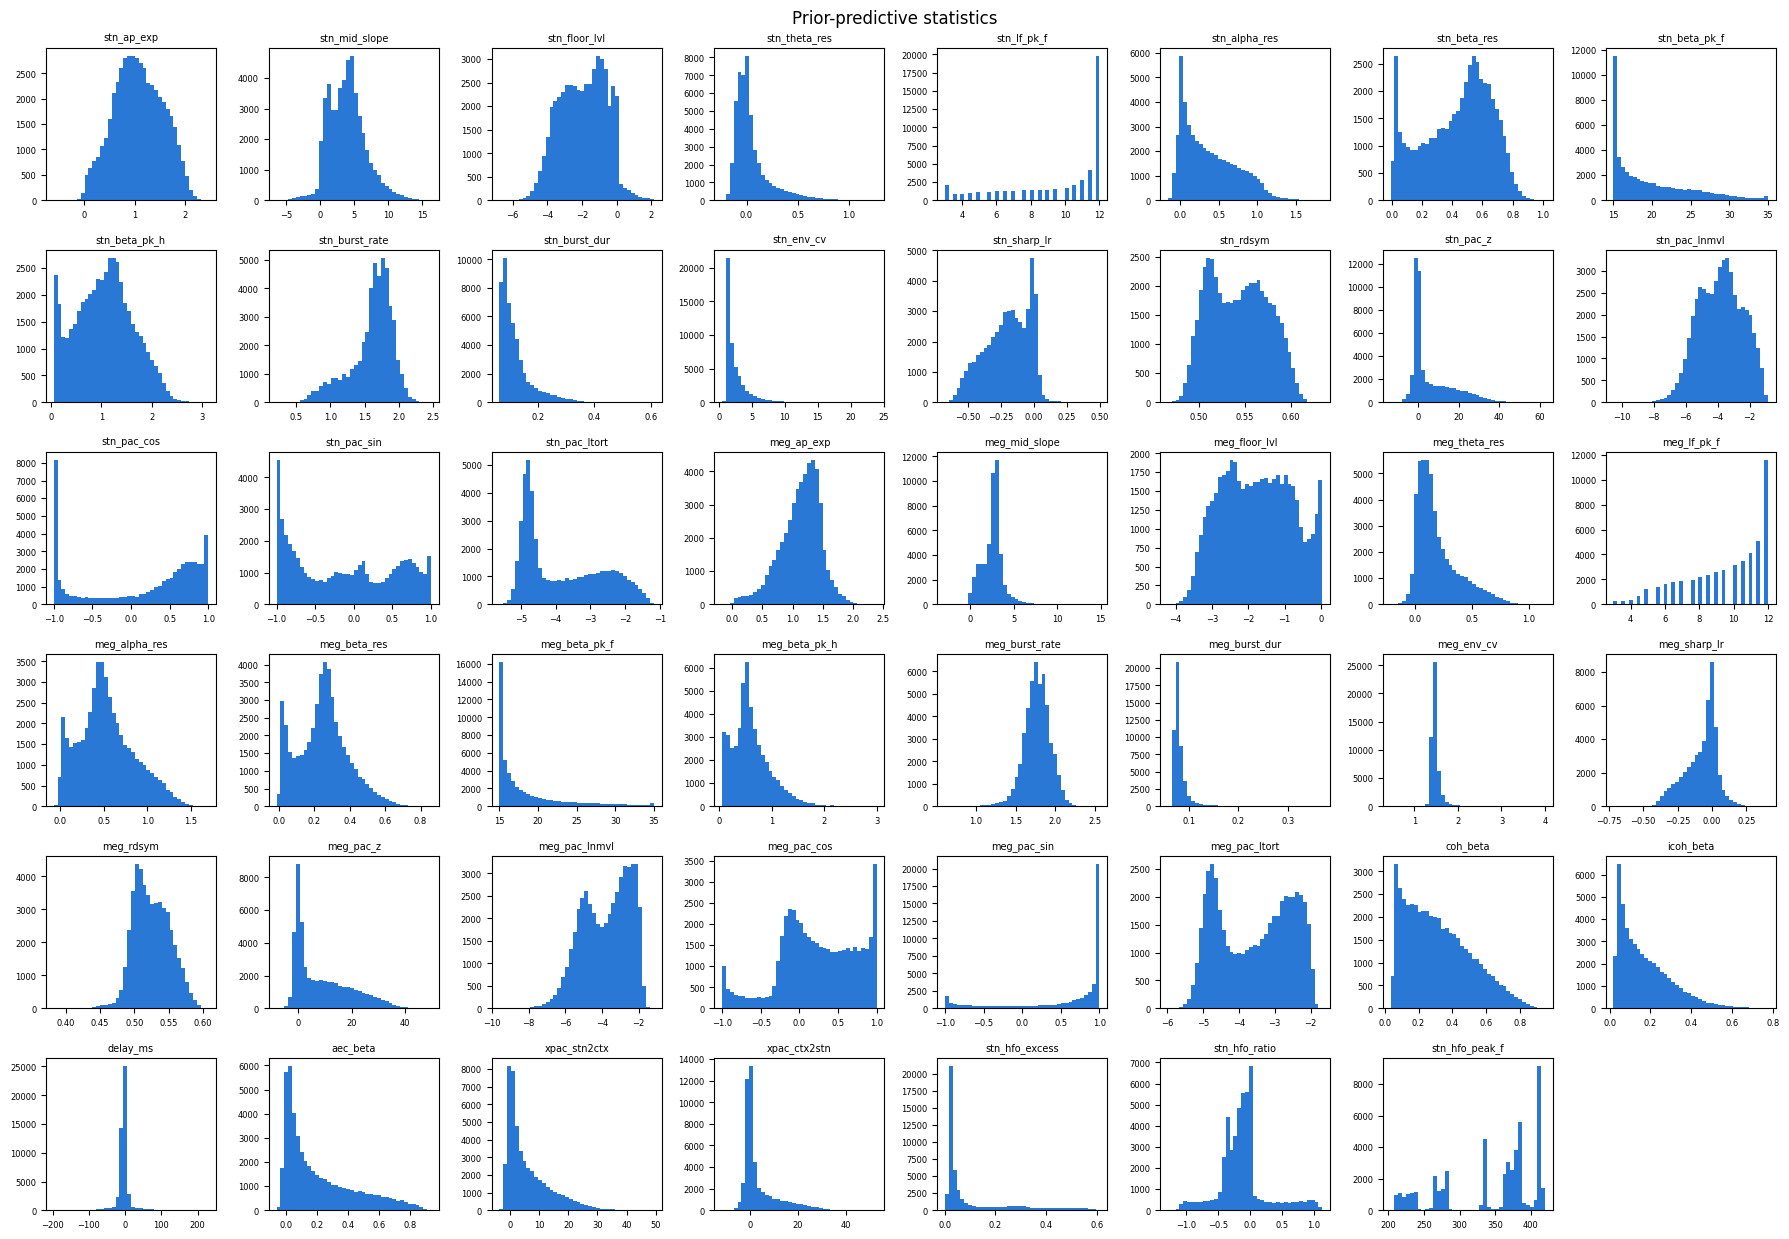

In [4]:
def sample_prior(n, rng):
    return PRIOR_LO + (PRIOR_HI - PRIOR_LO) * rng.random((n, len(PRIOR_NAMES)))


def sim_bank(n, seed, tag):
    fn = OUT_DIR / f"bank_{tag}_{n}_{config_hash()}.npz"
    if fn.exists():
        d = np.load(fn); print(f"loaded {fn.name}"); return d["theta"], d["X"]
    theta = sample_prior(n, np.random.default_rng(seed)); t0 = time.time()
    X = simulate_stats(theta, seed)
    print(f"  bank {tag}: {n} sims ({(time.time() - t0) / 60:.1f} min)")
    np.savez(fn, theta=theta, X=X)
    return theta, X


if RUN_SBI:
    _th, _X = sim_bank(N_SIM + N_RECOVERY, SEED, "train+test")
    THETA_BANK, X_BANK = _th[:N_SIM], _X[:N_SIM]; THETA_TEST, X_TEST = _th[N_SIM:], _X[N_SIM:]
    good = np.isfinite(X_BANK).all(1)
    print(f"bank: {len(X_BANK)} sims, {100 * (1 - good.mean()):.1f}% non-finite (dropped)")
    nc = 8; nr = int(np.ceil(len(STAT_NAMES) / nc))
    fig, axs = plt.subplots(nr, nc, figsize=(18, 2.1 * nr))
    for i, ax in enumerate(axs.flat):
        if i < len(STAT_NAMES):
            ax.hist(X_BANK[good, i], 40, color="#2a78d6"); ax.set_title(STAT_NAMES[i], fontsize=7); ax.tick_params(labelsize=6)
        else:
            ax.axis("off")
    fig.suptitle("Prior-predictive statistics"); fig.tight_layout(); plt.show()

## 5. NPE: recovery, calibration, identifiability

loaded npe_48752_4cd50520a75b_s0.pt
    param     R2  contraction  coverage90
     w_GS  0.892        0.896       0.870
     w_CS  0.266        0.369       0.878
     w_TC  0.635        0.709       0.888
log10_sig  0.935        0.942       0.860
 log10_aH  0.631        0.655       0.868
 log10_gC  0.357        0.387       0.880
    snr_S  0.521        0.528       0.878
    snr_C  0.463        0.515       0.872
    chi_S  0.435        0.543       0.882
    chi_C  0.377        0.442       0.862
      f_a  0.536        0.573       0.862
      w_a  0.481        0.554       0.895
      k_d  0.882        0.898       0.880
    g_ctx  0.766        0.806       0.910
log10_flS  0.527        0.545       0.882
log10_flC  0.474        0.473       0.870
      f_H  0.358        0.376       0.870
    lam_H  0.224        0.283       0.880
 sig_slow  0.778        0.822       0.868
      f_T  0.502        0.618       0.828
     w_TS  0.507        0.500       0.888
     w_TM  0.219        0.268       0.89

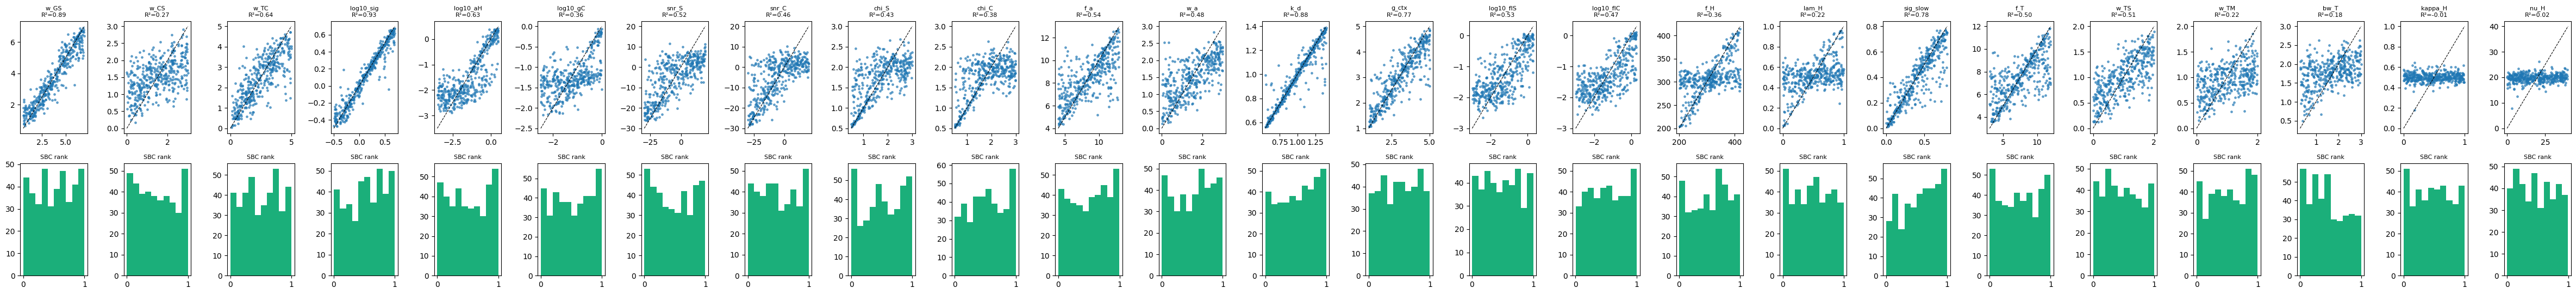

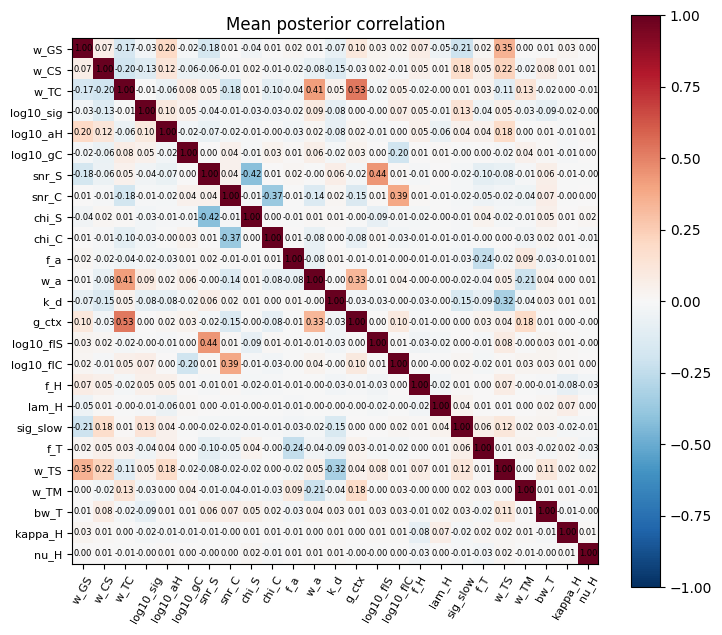

In [5]:
def make_npe(theta, X, seed=0):
    fn = OUT_DIR / f"npe_{len(theta)}_{config_hash()}_s{seed}.pt"
    if fn.exists():
        print(f"loaded {fn.name}")
        return torch.load(fn, weights_only=False)
    post = _make_npe(theta, X, seed)
    try:
        torch.save(post, fn)
    except Exception as e:
        warnings.warn(f"could not cache the posterior ({e})")
    return post


def _make_npe(theta, X, seed=0):
    from sbi.utils import BoxUniform
    try:
        from sbi.inference import NPE
    except ImportError:
        from sbi.inference import SNPE as NPE
    torch.manual_seed(seed)
    good = np.isfinite(X).all(1)
    prior = BoxUniform(torch.tensor(PRIOR_LO, dtype=torch.float32), torch.tensor(PRIOR_HI, dtype=torch.float32))
    inf = NPE(prior=prior, density_estimator="nsf")
    inf.append_simulations(torch.tensor(theta[good], dtype=torch.float32), torch.tensor(X[good], dtype=torch.float32))
    return inf.build_posterior(inf.train(show_train_summary=False))


def post_samples(posterior, x, n=1000, return_frac=False, max_draws=400_000, chunk=20_000):
    """Rejection sampling, as sbi does by default: draw from the flow until n in-prior samples are collected
    (or max_draws). frac = in-prior fraction, reported as a diagnostic of leakage."""
    xt = torch.tensor(np.asarray(x, float), dtype=torch.float32)
    keep, drawn = [], 0
    while drawn < max_draws:
        m = min(chunk, max_draws - drawn) if drawn else max(n, 2000)
        s = posterior.sample((m,), x=xt, show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()
        drawn += m
        keep.append(s[((s >= PRIOR_LO) & (s <= PRIOR_HI)).all(1)])
        if sum(len(k) for k in keep) >= n:
            break
    inside = np.concatenate(keep); frac = len(inside) / drawn
    s = inside[:n] if len(inside) >= 50 else np.clip(s[:n], PRIOR_LO, PRIOR_HI)
    return (s, frac) if return_frac else s


if RUN_SBI:
    POSTERIOR = make_npe(THETA_BANK, X_BANK)
    ok = np.isfinite(X_TEST).all(1)
    pm, psd, ranks, C = [], [], [], []
    for th, x in zip(THETA_TEST[ok], X_TEST[ok]):
        s = post_samples(POSTERIOR, x, 500)
        pm.append(s.mean(0)); psd.append(s.std(0)); ranks.append((s < th).mean(0)); C.append(np.corrcoef(s.T))
    pm, psd, ranks, C = map(np.array, (pm, psd, ranks, C)); truth = THETA_TEST[ok]
    prior_sd = (PRIOR_HI - PRIOR_LO) / np.sqrt(12)
    REC = pd.DataFrame(dict(param=PRIOR_NAMES,
                            R2=[1 - ((pm[:, i] - truth[:, i]) ** 2).sum() / ((truth[:, i] - truth[:, i].mean()) ** 2).sum() for i in range(len(PRIOR_NAMES))],
                            contraction=1 - (psd ** 2).mean(0) / prior_sd ** 2,
                            coverage90=((ranks > 0.05) & (ranks < 0.95)).mean(0)))
    print(REC.round(3).to_string(index=False)); REC.to_csv(OUT_DIR / "parameter_recovery.csv", index=False)
    fig, ax = plt.subplots(2, len(PRIOR_NAMES), figsize=(1.9 * len(PRIOR_NAMES), 5.5))
    for i, nm in enumerate(PRIOR_NAMES):
        ax[0, i].scatter(truth[:, i], pm[:, i], s=6, alpha=.6)
        ax[0, i].plot([PRIOR_LO[i], PRIOR_HI[i]], [PRIOR_LO[i], PRIOR_HI[i]], "k--", lw=.8)
        ax[0, i].set_title(f"{nm}\nR²={REC.R2[i]:.2f}", fontsize=8)
        ax[1, i].hist(ranks[:, i], 10, color="#1baf7a"); ax[1, i].set_title("SBC rank", fontsize=8)
    fig.tight_layout(); fig.savefig(OUT_DIR / "parameter_recovery.png", dpi=200); plt.show()
    Cm = np.nanmean(C, 0)
    fig, ax = plt.subplots(figsize=(7.5, 6.5)); im = ax.imshow(Cm, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(PRIOR_NAMES)), PRIOR_NAMES, rotation=60, fontsize=8); ax.set_yticks(range(len(PRIOR_NAMES)), PRIOR_NAMES, fontsize=8)
    for i in range(len(Cm)):
        for j in range(len(Cm)):
            ax.text(j, i, f"{Cm[i, j]:.2f}", ha="center", va="center", fontsize=6)
    fig.colorbar(im); ax.set_title("Mean posterior correlation"); fig.tight_layout()
    fig.savefig(OUT_DIR / "posterior_correlation.png", dpi=200); plt.show()

## 6. Which pathway does levodopa act on? (amortised model comparison + model recovery)

**Factorial design (v4.5).** β route × HFO shift: none / GPe→STN loop gain (w_GS × 0.3–0.8) / slow burst
input (σ_slow × 0.2–0.7) / noise-excitability (σ × 0.5–0.8), each with or without the HFO shift; plus
hyperdirect, BG→cortex, cortical gain and β-locking. Family-level inference asks which β route and whether
HFO shifts, regardless of the other factor.

| label | OFF → ON |
|---|---|
| H_HFO | HFO frequency + 20–80 Hz and power × 1.2–2.5 (slow → fast HFO) |
| H_lock | β-locking λ × 0.1–0.6 |
| H_GS_HFO | GPe→STN × 0.3–0.8 **and** HFO shift: levodopa reshapes both rhythms, coupling untouched |
| none | nothing |
| H_GS | GPe→STN × 0.3–0.8 (β loop gain) |
| H_HD | hyperdirect × 0.2–0.7 |
| H_TC | BG→cortex × 0.2–0.7 |
| H_ctx | cortical E–I gain × 0.5–0.85 (levodopa acting on cortex directly) |

Every pair also gets session nuisance: SNR_S and SNR_C each + N(0, 1.5 dB); low-frequency component
(f_T + N(0, 1 Hz), bandwidth × e^N(0,0.3), weights × e^N(0,0.4)); α (f_α + N(0, 0.5 Hz), w_α × e^N(0,0.2)).

loaded pairs_682_4cd50520a75b_fact12v5.npz
model recovery: accuracy = 0.455, log-loss = 1.497


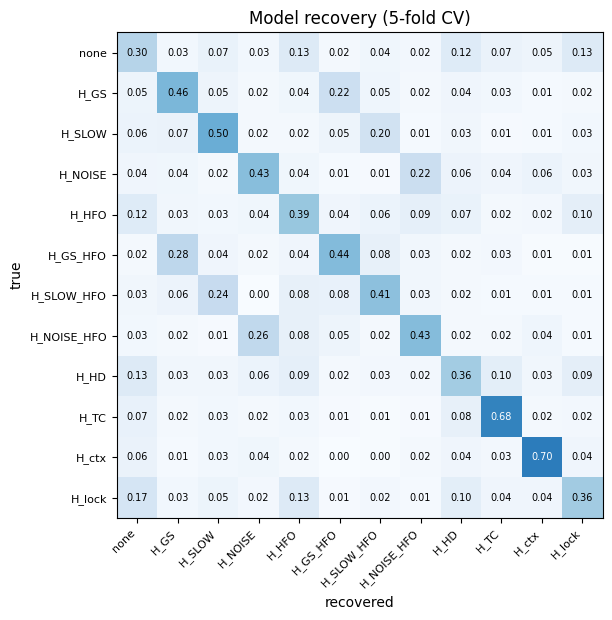

family recovery [beta_route] accuracy 0.72; rows = true ['none', 'GPe-STN', 'slow input', 'noise']
            none  GPe-STN  slow input  noise
none        0.70     0.07        0.12   0.11
GPe-STN     0.10     0.74        0.10   0.06
slow input  0.13     0.14        0.70   0.04
noise       0.14     0.07        0.03   0.76
family recovery [HFO_shift] accuracy 0.66; rows = true ['no', 'yes']
       no   yes
no   0.68  0.32
yes  0.36  0.64
loaded clf_8184_4cd50520a75b_fact12v5.joblib


In [6]:
HYPS = ["none", "H_GS", "H_SLOW", "H_NOISE", "H_HFO", "H_GS_HFO", "H_SLOW_HFO", "H_NOISE_HFO",
        "H_HD", "H_TC", "H_ctx", "H_lock"]
HYP_TAG = "fact12v5"                   # pair/classifier caches are keyed on the hypothesis set
# factorial families (over the first 8 hypotheses) for family-level RFX-BMS
FAMILIES = {
    "beta_route": {"none": ["none", "H_HFO"], "GPe-STN": ["H_GS", "H_GS_HFO"],
                   "slow input": ["H_SLOW", "H_SLOW_HFO"], "noise": ["H_NOISE", "H_NOISE_HFO"]},
    "HFO_shift": {"no": ["none", "H_GS", "H_SLOW", "H_NOISE"], "yes": ["H_HFO", "H_GS_HFO", "H_SLOW_HFO", "H_NOISE_HFO"]},
}


def perturb(th_off, hyp, rng):
    th = th_off.copy(); n = len(th); u = lambda a, b: a + (b - a) * rng.random(n)
    if hyp in ("H_GS", "H_GS_HFO"):
        th[:, IX["w_GS"]] *= u(0.3, 0.8)
    if hyp in ("H_SLOW", "H_SLOW_HFO"):
        th[:, IX["sig_slow"]] *= u(0.2, 0.7)
    if hyp in ("H_NOISE", "H_NOISE_HFO"):
        th[:, IX["log10_sig"]] += np.log10(u(0.5, 0.8))
    if hyp == "H_HD":
        th[:, IX["w_CS"]] *= u(0.2, 0.7)
    if hyp == "H_TC":
        th[:, IX["w_TC"]] *= u(0.2, 0.7)
    if hyp in ("H_HFO", "H_GS_HFO", "H_SLOW_HFO", "H_NOISE_HFO"):
        th[:, IX["f_H"]] += u(20, 80); th[:, IX["log10_aH"]] += np.log10(u(1.2, 2.5))
    if hyp == "H_lock":
        th[:, IX["lam_H"]] *= u(0.1, 0.6)
    if hyp == "H_ctx":
        th[:, IX["g_ctx"]] *= u(0.5, 0.85)
    th[:, IX["snr_S"]] += rng.normal(0, 1.5, n); th[:, IX["snr_C"]] += rng.normal(0, 1.5, n)
    # session nuisance (all hypotheses): tremor / θ–α and α change between real sessions too
    th[:, IX["f_T"]] += rng.normal(0, 1.0, n); th[:, IX["bw_T"]] *= np.exp(rng.normal(0, 0.3, n))
    th[:, IX["w_TS"]] *= np.exp(rng.normal(0, 0.4, n)); th[:, IX["w_TM"]] *= np.exp(rng.normal(0, 0.4, n))
    th[:, IX["f_a"]] += rng.normal(0, 0.5, n); th[:, IX["w_a"]] *= np.exp(rng.normal(0, 0.2, n))
    return np.clip(th, PRIOR_LO, PRIOR_HI)


def pair_features(S_off, S_on):
    return np.column_stack([S_off, S_on - S_off])


def pair_bank(n_per, seed):
    fn = OUT_DIR / f"pairs_{n_per}_{config_hash()}_{HYP_TAG}.npz"
    if fn.exists():
        d = np.load(fn); print(f"loaded {fn.name}"); return d["F"], d["y"]
    rng = np.random.default_rng(seed)
    TH_OFF, TH_ON, y = [], [], []
    for h, hyp in enumerate(HYPS):
        th_off = sample_prior(n_per, rng); TH_OFF.append(th_off); TH_ON.append(perturb(th_off, hyp, rng)); y.append(np.full(n_per, h))
    TH_OFF, TH_ON, y = map(np.concatenate, (TH_OFF, TH_ON, y))
    t0 = time.time()
    S_off = simulate_stats(TH_OFF, seed); print(f"  pairs OFF ({(time.time() - t0) / 60:.1f} min)")
    S_on = simulate_stats(TH_ON, seed + 500_000); print(f"  pairs ON ({(time.time() - t0) / 60:.1f} min)")
    F = pair_features(S_off, S_on); np.savez(fn, F=F, y=y)
    return F, y


def family_bms(LE, label):
    """Family-level RFX-BMS (Penny et al., 2010) over the 8 factorial hypotheses: family log-evidence =
    log mean of member evidences (uniform prior within family)."""
    out = {}
    for fam, groups in FAMILIES.items():
        cols = {g: [HYPS.index(h) for h in hs] for g, hs in groups.items()}
        L = LE.values if hasattr(LE, "values") else LE
        F = np.column_stack([np.logaddexp.reduce(L[:, ix], axis=1) - np.log(len(ix)) for ix in cols.values()])
        fq, xp_ = rfx_bms(F)
        out[fam] = dict(zip(groups, xp_))
        print(f"[{label}] family '{fam}': " + ", ".join(f"{g} freq {f:.2f} / XP {x:.2f}" for g, f, x in zip(groups, fq, xp_)))
    return out


def rfx_bms(logev, n_samp=200_000, seed=0):
    N, K = logev.shape; a0 = np.ones(K); a = a0.copy()
    for _ in range(500):
        lu = logev + digamma(a) - digamma(a.sum()); lu -= lu.max(1, keepdims=True)
        g = np.exp(lu); g /= g.sum(1, keepdims=True); a_new = a0 + g.sum(0)
        if np.abs(a_new - a).max() < 1e-8:
            a = a_new; break
        a = a_new
    r = np.random.default_rng(seed).dirichlet(a, n_samp)
    return a / a.sum(), np.bincount(r.argmax(1), minlength=K) / n_samp


if RUN_MODELCOMP:
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.calibration import CalibratedClassifierCV
    from sklearn.model_selection import cross_val_predict, StratifiedKFold
    from sklearn.metrics import confusion_matrix, log_loss
    F_PAIR, Y_PAIR = pair_bank(N_PAIR, SEED + 77)
    okp = np.isfinite(F_PAIR).all(1); F_PAIR, Y_PAIR = F_PAIR[okp], Y_PAIR[okp]
    clf = CalibratedClassifierCV(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05), method="isotonic", cv=3)
    P_cv = cross_val_predict(clf, F_PAIR, Y_PAIR, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")
    CM = confusion_matrix(Y_PAIR, P_cv.argmax(1), normalize="true")
    print(f"model recovery: accuracy = {(P_cv.argmax(1) == Y_PAIR).mean():.3f}, log-loss = {log_loss(Y_PAIR, P_cv):.3f}")
    fig, ax = plt.subplots(figsize=(7.5, 6.3)); ax.imshow(CM, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(len(HYPS)), HYPS, rotation=45, ha="right", fontsize=8); ax.set_yticks(range(len(HYPS)), HYPS, fontsize=8)
    for i in range(len(HYPS)):
        for j in range(len(HYPS)):
            ax.text(j, i, f"{CM[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w" if CM[i, j] > .5 else "k")
    ax.set_xlabel("recovered"); ax.set_ylabel("true"); ax.set_title("Model recovery (5-fold CV)")
    fig.tight_layout(); fig.savefig(OUT_DIR / "model_recovery.png", dpi=200); plt.show()
    # family-level recovery among the 8 factorial hypotheses
    fact = np.isin(Y_PAIR, range(8))
    for fam, groups in FAMILIES.items():
        lab = {HYPS.index(h): gi for gi, (g, hs) in enumerate(groups.items()) for h in hs}
        yt = np.array([lab[y] for y in Y_PAIR[fact]])
        Pf = np.column_stack([P_cv[fact][:, [HYPS.index(h) for h in hs]].sum(1) for hs in groups.values()])
        cmf = confusion_matrix(yt, Pf.argmax(1), normalize="true")
        print(f"family recovery [{fam}] accuracy {np.mean(Pf.argmax(1) == yt):.2f}; rows = true " + str(list(groups)))
        print(pd.DataFrame(cmf, index=list(groups), columns=list(groups)).round(2).to_string())
    import joblib
    _fn = OUT_DIR / f"clf_{len(F_PAIR)}_{config_hash()}_{HYP_TAG}.joblib"
    if _fn.exists():
        MODEL_CLF = joblib.load(_fn); print(f"loaded {_fn.name}")
    else:
        MODEL_CLF = clf.fit(F_PAIR, Y_PAIR); joblib.dump(MODEL_CLF, _fn)
    # two more classifiers with different seeds (robustness of the empirical model comparison, §10.4)
    CLF_SEEDS = [MODEL_CLF]
    for sd in (1, 2):
        _fs = OUT_DIR / f"clf_{len(F_PAIR)}_{config_hash()}_{HYP_TAG}_seed{sd}.joblib"
        if _fs.exists():
            CLF_SEEDS.append(joblib.load(_fs))
        else:
            c2 = CalibratedClassifierCV(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=sd),
                                        method="isotonic", cv=StratifiedKFold(3, shuffle=True, random_state=sd))
            CLF_SEEDS.append(c2.fit(F_PAIR, Y_PAIR)); joblib.dump(CLF_SEEDS[-1], _fs)

## 7. ds004998: manifest, loading, preprocessing

* One rest recording per subject × medication: `task-Rest` if present, else the first 300 s ('rest'
  event) of HoldL, MoveL, HoldR, MoveR (run 1), in that order.
* Contacts renamed with the dataset's montage file; bipolar pairs between adjacent good contacts.
* Notches: 50 Hz harmonics to 450 Hz and the four head-position-coil frequencies, before resampling to
  1 kHz. Optional tSSS (off by default).
* Segment: longest stretch of the rest period free of `bad_lfp`, length `seg_len`.
* **Channel selection without medication bias:** per hemisphere, the bipolar pair with the most HFO power
  above 1/f (200–420 Hz) and the ipsilateral gradiometer with the highest STN–MEG β coherence, both averaged
  over OFF and ON, so selection cannot favour either session.
* **EMG:** 4 forearm EMGs, 20–200 Hz envelope; samples above median + 4·MAD (± 250 ms) are masked in
  all PAC statistics. Tremor index = EMG-envelope power at 3–7 Hz.

In [7]:
def build_manifest(root):
    rows = []
    for f in sorted(Path(root).glob("sub-*/ses-*/meg/*_meg.fif")):
        name = f.name
        if "task-noise" in name:
            continue
        ent = dict(re.findall(r"(sub|ses|task|acq|run|split)-([A-Za-z0-9]+)", name))
        if ent.get("split", "01") != "01" or "acq" not in ent:
            continue
        rows.append(dict(subject=ent["sub"], session=ent.get("ses"), task=ent["task"], med=ent["acq"],
                         run=int(ent.get("run", 1)), path=str(f)))
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    df["prio"] = df.task.map({t: i for i, t in enumerate(PIPE["task_priority"])}).fillna(99)
    # all candidates, best first; process_ds004998 tries them in order until one has a clean rest stretch
    return df.sort_values(["subject", "med", "prio", "run"]).drop(columns="prio").reset_index(drop=True)


def _sidecar(path, suffix):
    p = Path(path)
    stem = re.sub(r"(_split-\d+)?_meg\.fif$", "", p.name)
    cands = [p.with_name(stem + suffix), p.with_name(re.sub(r"_meg\.fif$", "", p.name) + suffix)]
    return next((c for c in cands if c.exists()), None)


_BIDS_WARNED = False


def read_recording(path):
    """Raw with LFP contacts renamed, bads from channels.tsv, annotations from events.tsv."""
    import mne
    global _BIDS_WARNED
    raw = None
    try:
        import mne_bids
        bp = mne_bids.get_bids_path_from_fname(path)
        raw = mne_bids.read_raw_bids(bp, verbose="error")
    except Exception as err:
        if not _BIDS_WARNED:
            print(f"  (mne-bids not used: {type(err).__name__}: {str(err)[:120]} — reading .fif + sidecars directly)")
            _BIDS_WARNED = True
        raw = mne.io.read_raw_fif(path, preload=False, verbose="error", allow_maxshield=True)
        ev = _sidecar(path, "_events.tsv")
        if ev is not None:
            e = pd.read_csv(ev, sep="\t")
            # BIDS onsets are relative to the first sample; MNE annotations with orig_time are relative to
            # meas_date, so the first-sample offset must be added (this was the v4 bug)
            shift = raw.first_time if raw.annotations.orig_time is not None else 0.0
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                raw.set_annotations(mne.Annotations(e.onset.values + shift, e.duration.values,
                                                    e.trial_type.astype(str).values, orig_time=raw.annotations.orig_time))
        ch = _sidecar(path, "_channels.tsv")
        if ch is not None:
            c = pd.read_csv(ch, sep="\t")
            raw.info["bads"] = [n for n in c.loc[c.status == "bad", "name"] if n in raw.ch_names]
    mont = list(Path(path).parents[1].glob("montage/*_montage.tsv"))
    if mont:
        m = pd.read_csv(mont[0], sep="\t")
        mapping = {r.right_contacts_old: r.right_contacts_new for r in m.itertuples() if isinstance(r.right_contacts_old, str)}
        mapping.update({r.left_contacts_old: r.left_contacts_new for r in m.itertuples() if isinstance(r.left_contacts_old, str)})
        mapping = {k: v for k, v in mapping.items() if k in raw.ch_names}
        raw.rename_channels(mapping)
        raw.info["bads"] = [mapping.get(b, b) for b in raw.info["bads"]]
    return raw


def rest_segment(raw, L):
    """Start (s, relative to the first sample) of the longest bad_lfp-free stretch inside 'rest'."""
    sh = raw.first_time if raw.annotations.orig_time is not None else 0.0
    ann = [(a["onset"] - sh, a["duration"], a["description"]) for a in raw.annotations]
    rest = [(o, d) for o, d, s in ann if s.lower() == "rest"]
    if not rest:
        rest = [(0.0, raw.n_times / raw.info["sfreq"])] if "rest" in Path(raw.filenames[0]).name.lower() else []
    bad = [(o, o + d) for o, d, s in ann if "bad" in s.lower()]
    best = None
    for o, d in rest:
        for t0 in np.arange(o, o + d - L + 1e-9, 1.0):
            if not any(b0 < t0 + L and b1 > t0 for b0, b1 in bad):
                return t0
    return best


def preprocess_recording(path):
    """→ dict(lfp: {pair: x}, grad: (names, X), emg: X, side info, n_ok) at PIPE['fs'], seg_len long."""
    import mne
    raw = read_recording(path)
    fs0 = raw.info["sfreq"]; L = PIPE["seg_len"]
    t0 = rest_segment(raw, L + 2.0)
    if t0 is None:
        return None
    raw.crop(tmin=t0, tmax=t0 + L + 2.0 - 1 / fs0).load_data(verbose="error")
    if PIPE["use_tsss"]:
        raw = mne.preprocessing.maxwell_filter(raw, st_duration=10.0, verbose="error")
    lf = PIPE["line_freq"]
    notch = [lf * k for k in range(1, int(450 // lf) + 1)] + [h for h in PIPE["hpi_freqs"] if h < fs0 / 2]
    raw.notch_filter(notch, notch_widths=1.0, picks="all", verbose="error")
    raw.resample(PIPE["fs"], verbose="error")
    good = [c for c in raw.ch_names if c not in raw.info["bads"]]
    out = dict(lfp={}, side={})
    for side in ("left", "right"):
        cont = sorted([c for c in good if c.startswith(f"LFP-{side}-")], key=lambda c: int(c.split("-")[-1]))
        nums = [int(c.split("-")[-1]) for c in cont]
        for (a, na), (b, nb) in zip(zip(cont, nums), zip(cont[1:], nums[1:])):
            if nb == na + 1:
                out["lfp"][f"LFP-{side}-{na}{nb}"] = (raw.get_data(picks=[a])[0] - raw.get_data(picks=[b])[0])
                out["side"][f"LFP-{side}-{na}{nb}"] = side
    grads = [c for c, t in zip(raw.ch_names, raw.get_channel_types()) if t == "grad" and c in good]
    out["grad_names"] = grads
    out["grad_x"] = np.array([raw.info["chs"][raw.ch_names.index(c)]["loc"][0] for c in grads])
    out["grad"] = raw.get_data(picks=grads) if grads else np.zeros((0, raw.n_times))
    emg = [c for c, t in zip(raw.ch_names, raw.get_channel_types()) if t == "emg" and c in good]
    out["emg"] = raw.get_data(picks=emg) if emg else np.zeros((0, raw.n_times))
    out["t0"] = t0
    return out


def emg_mask(emg, fs):
    """1 = keep, 0 = EMG burst (any channel), dilated; plus tremor index."""
    N = emg.shape[-1]
    if len(emg) == 0:
        return np.ones(N), np.nan
    env = np.abs(signal.hilbert(bandpass(emg, *PIPE["emg_band"], fs), axis=-1))
    env = signal.sosfiltfilt(signal.butter(2, 10.0, fs=fs, output="sos"), env, axis=-1)
    med = np.median(env, -1, keepdims=True); mad = np.median(np.abs(env - med), -1, keepdims=True) * 1.4826
    bad = (env > med + PIPE["emg_mad"] * mad).any(0)
    k = int(PIPE["emg_dilate"] * fs)
    bad = np.convolve(bad.astype(float), np.ones(2 * k + 1), "same") > 0
    f, P = signal.welch(zs(env), fs, nperseg=int(4 * fs), axis=-1)
    trem = (P[:, (f >= 3) & (f <= 7)].sum(-1) / P[:, (f >= 1) & (f <= 20)].sum(-1)).max()
    return (~bad).astype(float), float(trem)


def beta_coh(a, B, fs):
    f, Cab = signal.csd(a[None], B, fs, nperseg=int(fs), axis=-1)
    _, Pa = signal.welch(a, fs, nperseg=int(fs)); _, Pb = signal.welch(B, fs, nperseg=int(fs), axis=-1)
    mb = (f >= PIPE["beta"][0]) & (f <= PIPE["beta"][1])
    return (np.abs(Cab[:, mb]) ** 2 / (Pa[None, mb] * Pb[:, mb])).mean(-1)


def process_ds004998(man):
    fn = OUT_DIR / f"metrics_ds004998_{config_hash()}.csv"
    if fn.exists():
        print(f"loaded {fn.name}"); return pd.read_csv(fn), json.loads((OUT_DIR / f"selection_{config_hash()}.json").read_text())
    fs = PIPE["fs"]; cache = {}; used = {}
    groups = list(man.groupby(["subject", "med"], sort=True))
    for gi, ((subj, med), cand) in enumerate(groups):
        t = time.time(); seg = None
        for _, r in cand.iterrows():
            try:
                seg = preprocess_recording(r.path)
            except Exception as e:
                print(f"  ! {Path(r.path).name}: {e}"); seg = None
            if seg is not None:
                used[(subj, med)] = Path(r.path).name; break
        if seg is None:
            print(f"  skip {subj} {med}: none of {len(cand)} file(s) has a clean {PIPE['seg_len']:.0f}-s rest stretch"); continue
        cache[(subj, med)] = seg
        print(f"  {gi + 1}/{len(groups)} {subj} {med} ← {used[(subj, med)]} ({time.time() - t:.0f} s; "
              f"{len(seg['lfp'])} bipolar, {len(seg['grad_names'])} grads, {len(seg['emg'])} EMG)")
    rows, selection = [], {}
    for subj in sorted({k[0] for k in cache}):
        meds = [m for m in ("MedOff", "MedOn") if (subj, m) in cache]
        for side in ("left", "right"):
            pairs = set.intersection(*[{p for p, s in cache[(subj, m)]["side"].items() if s == side} for m in meds]) if meds else set()
            if not pairs:
                continue
            # HFO-best pair (pooled OFF+ON, so the choice cannot favour either session)
            hp = {p: np.mean([hfo_stats(zs(cache[(subj, m)]["lfp"][p][None]), fs)[0][0] for m in meds]) for p in pairs}
            pair = max(hp, key=hp.get)
            gsets = [set(np.array(cache[(subj, m)]["grad_names"])[(cache[(subj, m)]["grad_x"] < 0) == (side == "left")]) for m in meds]
            gnames = sorted(set.intersection(*gsets)) if gsets else []
            if not gnames:
                continue
            ch_score = np.zeros(len(gnames))
            for m in meds:
                seg = cache[(subj, m)]; idx = [seg["grad_names"].index(g) for g in gnames]
                ch_score += beta_coh(zs(seg["lfp"][pair]), zs(seg["grad"][idx]), fs) / len(meds)
            grad = gnames[int(np.argmax(ch_score))]
            selection[f"{subj}_{side}"] = dict(pair=pair, grad=grad, coh=float(ch_score.max()))
            for m in meds:
                seg = cache[(subj, m)]
                lfp = seg["lfp"][pair]; meg = seg["grad"][seg["grad_names"].index(grad)]
                n = int(PIPE["seg_len"] * fs)
                lfp, meg = lfp[:n], meg[:n]
                w, trem = emg_mask(seg["emg"][:, :n], fs)
                S = compute_stats(lfp[None], meg[None], w=w[None])[0]
                S0 = compute_stats(lfp[None], meg[None])[0]         # unmasked, for the EMG sensitivity check
                e = int(PIPE["edge_trim"] * fs)
                h = np.abs(signal.hilbert(bandpass(zs(lfp), *PIPE["hfa_stn"], fs)))[e:-e]
                emg_env = np.abs(signal.hilbert(bandpass(seg["emg"][:, :n], *PIPE["emg_band"], fs), axis=-1))[:, e:-e] \
                    if len(seg["emg"]) else np.zeros((0, len(h)))
                hfa_emg_r = max([abs(np.corrcoef(h, ee)[0, 1]) for ee in emg_env], default=np.nan)
                rows.append(dict(subject=subj, side=side, med=m, pair=pair, grad=grad, sel_coh=float(ch_score.max()),
                                 masked_frac=1 - w.mean(), tremor_idx=trem, hfa_emg_r=hfa_emg_r,
                                 stn_pac_z_unmasked=S0[STAT_NAMES.index("stn_pac_z")],
                                 meg_pac_z_unmasked=S0[STAT_NAMES.index("meg_pac_z")],
                                 **dict(zip(STAT_NAMES, S))))
    df = pd.DataFrame(rows); df.to_csv(fn, index=False)
    (OUT_DIR / f"selection_{config_hash()}.json").write_text(json.dumps(selection, indent=1))
    return df, selection


if RUN_DATA:
    MAN = build_manifest(DS_ROOT)
    print(MAN.groupby(["med", "task"]).size().unstack(fill_value=0) if len(MAN) else f"no recordings found under {DS_ROOT}")
    print(f"{MAN.subject.nunique() if len(MAN) else 0} subjects; candidate files are tried in priority order")
    M_DS, SEL = process_ds004998(MAN)
    if len(M_DS):
        print(f"{M_DS.groupby(['subject', 'side']).ngroups} hemispheres, {len(M_DS)} hemisphere-sessions")
    else:
        warnings.warn("no hemisphere qualified — check DS_ROOT and seg_len (rest must hold seg_len + 2 s free of bad_lfp)")

task    HoldL  HoldR  MoveL  MoveR  Rest
med                                     
MedOff     16      9     20      8     3
MedOn      17      9     16      6     4
20 subjects; candidate files are tried in priority order
loaded metrics_ds004998_4cd50520a75b.csv
39 hemispheres, 76 hemisphere-sessions


## 8. Data: OFF vs ON, EMG control, UPDRS

Unit of analysis: hemisphere (STN pair + ipsilateral gradiometer). Paired OFF vs ON (Wilcoxon,
Hedges g_av). UPDRS: ΔSUM per subject; contralateral akinesia–rigidity (right STN ↔ "AR left") per
hemisphere.

[ds004998 OFF vs ON]
            metric  n     off      on  p_wilcoxon  g_off_on
         stn_pac_z 37   0.977   1.389       0.455    -0.157
stn_pac_z_unmasked 37   2.115   2.034       0.976     0.020
         meg_pac_z 37  -0.092  -0.009       0.788    -0.073
meg_pac_z_unmasked 37   0.192   0.283       0.823    -0.060
      stn_beta_res 37   0.205   0.130       0.000     0.485
      meg_beta_res 37   0.078   0.084       0.561    -0.075
    stn_hfo_excess 37   0.049   0.066       0.029    -0.369
     stn_hfo_ratio 37  -0.018   0.048       0.000    -0.483
    stn_hfo_peak_f 37 311.486 316.865       0.718    -0.090
        stn_env_cv 37   1.605   1.561       0.655     0.214
     stn_burst_dur 37   0.087   0.082       0.107     0.432
    stn_burst_rate 37   1.798   1.784       0.769     0.083
      stn_sharp_lr 37  -0.020  -0.036       0.354     0.139
          coh_beta 37   0.121   0.132       0.823    -0.174
         icoh_beta 37   0.071   0.072       0.929    -0.017
          delay_ms 

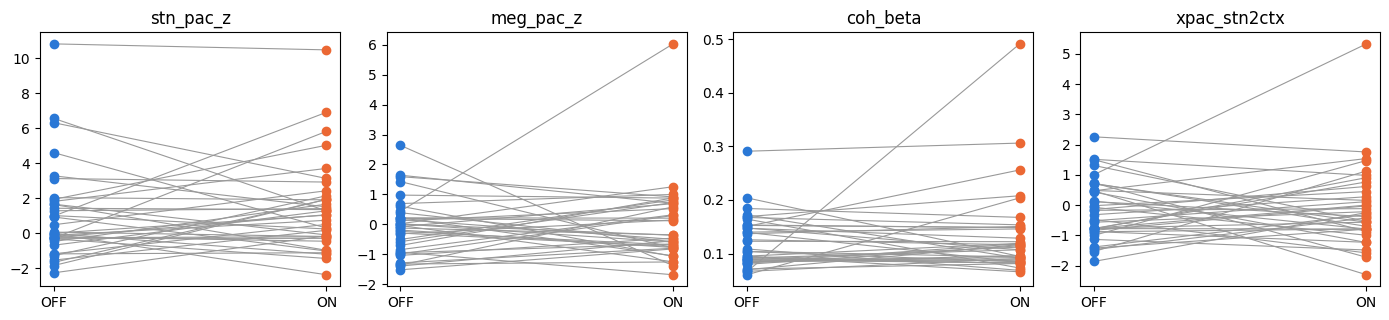

In [8]:
def hedges_paired(a, b):
    d = a - b; n = len(d)
    return d.mean() / ((a.std(ddof=1) + b.std(ddof=1)) / 2) * (1 - 3 / (4 * (n - 1) - 1))


def paired_table(df, metrics, label):
    off = df[df.med == "MedOff"].set_index(["subject", "side"]); on = df[df.med == "MedOn"].set_index(["subject", "side"])
    idx = off.index.intersection(on.index); rows = []
    for m in metrics:
        a, b = off.loc[idx, m].astype(float).values, on.loc[idx, m].astype(float).values
        ok = np.isfinite(a) & np.isfinite(b); a, b = a[ok], b[ok]
        r = dict(metric=m, n=len(a), off=np.mean(a) if len(a) else np.nan, on=np.mean(b) if len(b) else np.nan)
        if len(a) > 4:
            r.update(p_wilcoxon=stats.wilcoxon(a, b).pvalue, g_off_on=hedges_paired(a, b))
        rows.append(r)
    T = pd.DataFrame(rows); print(f"[{label}]"); print(T.round(3).to_string(index=False)); return T


def load_updrs(root):
    out = {}
    for med, fn in (("MedOff", "participants_updrs_off.tsv"), ("MedOn", "participants_updrs_on.tsv")):
        p = Path(root) / fn
        if p.exists():
            u = pd.read_csv(p, sep="\t"); u["subject"] = u.participant_id.str.replace("sub-", "", regex=False)
            out[med] = u.set_index("subject")
    return out


KEY_METRICS = ["stn_pac_z", "stn_pac_z_unmasked", "meg_pac_z", "meg_pac_z_unmasked", "stn_beta_res", "meg_beta_res",
               "stn_hfo_excess", "stn_hfo_ratio", "stn_hfo_peak_f", "stn_env_cv",
               "stn_burst_dur", "stn_burst_rate", "stn_sharp_lr", "coh_beta", "icoh_beta", "delay_ms", "aec_beta",
               "xpac_stn2ctx", "xpac_ctx2stn", "stn_ap_exp", "meg_ap_exp", "masked_frac", "tremor_idx", "hfa_emg_r"]

if RUN_DATA and len(M_DS):
    T_DS = paired_table(M_DS, KEY_METRICS, "ds004998 OFF vs ON"); T_DS.to_csv(OUT_DIR / "ds_off_on.csv", index=False)
    UPDRS = load_updrs(DS_ROOT)
    if len(UPDRS) == 2:
        off = M_DS[M_DS.med == "MedOff"].set_index(["subject", "side"]); on = M_DS[M_DS.med == "MedOn"].set_index(["subject", "side"])
        idx = off.index.intersection(on.index)
        print("Δ(OFF−ON) metric vs Δ contralateral AR score (hemisphere level, Spearman):")
        for m in ("stn_pac_z", "meg_pac_z", "stn_beta_res", "coh_beta", "xpac_stn2ctx"):
            dm, du = [], []
            for s, side in idx:
                col = "AR left" if side == "right" else "AR right"
                try:
                    du.append(float(UPDRS["MedOff"].loc[s, col]) - float(UPDRS["MedOn"].loc[s, col])); dm.append(off.loc[(s, side), m] - on.loc[(s, side), m])
                except (KeyError, ValueError, TypeError):
                    pass
            ok = np.isfinite(dm) & np.isfinite(du)
            if ok.sum() > 5:
                rho, p = stats.spearmanr(np.array(dm)[ok], np.array(du)[ok]); print(f"   Δ{m}: ρ = {rho:+.2f}, p = {p:.3f}, n = {ok.sum()}")
    fig, axs = plt.subplots(1, 4, figsize=(14, 3.3))
    for ax, m in zip(axs, ("stn_pac_z", "meg_pac_z", "coh_beta", "xpac_stn2ctx")):
        off = M_DS[M_DS.med == "MedOff"].set_index(["subject", "side"])[m]; on = M_DS[M_DS.med == "MedOn"].set_index(["subject", "side"])[m]
        idx = off.index.intersection(on.index)
        for k in idx:
            ax.plot([0, 1], [off[k], on[k]], color="#999", lw=.8)
        ax.scatter(np.zeros(len(idx)), off[idx], color="#2a78d6", zorder=3); ax.scatter(np.ones(len(idx)), on[idx], color="#eb6834", zorder=3)
        ax.set_xticks([0, 1], ["OFF", "ON"]); ax.set_title(m)
    fig.tight_layout(); fig.savefig(OUT_DIR / "ds_off_on.png", dpi=200); plt.show()

## 8b. Calibrated STN β→HFO coupling on the full rest period

Descriptive statistics that do not depend on the model (the fit in §10 uses 120-s segments so that data and
simulations have identical length; here every clean second of rest is used).

* Contacts and bands as in diagnostic 2: HFO-best pair; β peak ± 3 Hz; HFO peak ± 40 Hz (pooled OFF+ON).
* Masks: gentle EMG mask **and** transient rejection (|LFP| or HFO envelope > median + 6 MAD, ± 100 ms).
* Two nulls: (1) circular shifts; (2) **cross-session surrogate**: β phase from this session paired with HFO
  amplitude from the *other* session of the same contact pair, which cannot contain coupling. z_cross compares
  the observed normalised MVL with that distribution.
* Robust group tests (medians, Wilcoxon), fraction significant under both nulls, coupling vs β strength and
  burst duration across hemispheres, the most extreme hemispheres, the HFO shift and UPDRS.

In [9]:
COUP = dict(min_rest=60.0, min_piece=5.0, min_total_hold=30.0, transient_mad=6.0, transient_dilate=0.10,
            sig=2.58,
            # "contralateral": right STN ↔ "AR left" (left body side). Use "ipsilateral" if participants.json
            # defines "AR left/right" by hemisphere.
            ar_map="contralateral")


def ann_intervals(raw, regex):
    sh = raw.first_time if raw.annotations.orig_time is not None else 0.0
    dur = raw.n_times / raw.info["sfreq"]
    ann = [(a["onset"] - sh, a["duration"], a["description"]) for a in raw.annotations]
    bad = [(o, o + d) for o, d, s_ in ann if "bad" in s_.lower()]
    hits = [(max(0.0, o), min(dur, o + d)) for o, d, s_ in ann if re.search(regex, s_, re.I)]
    if not hits and regex.startswith("^rest") and "task-rest" in Path(raw.filenames[0]).name.lower():
        hits = [(0.0, dur)]
    out = []
    for a0, a1 in hits:
        segs = [(a0, a1)]
        for b0, b1 in bad:
            new = []
            for s0, s1 in segs:
                if b1 <= s0 or b0 >= s1:
                    new.append((s0, s1)); continue
                if b0 > s0:
                    new.append((s0, b0))
                if b1 < s1:
                    new.append((b1, s1))
            segs = new
        out += [(s0, s1) for s0, s1 in segs if s1 - s0 >= COUP["min_piece"]]
    return out


def load_lfp_emg(path):
    raw = read_recording(path)
    good = [c for c in raw.ch_names if c not in raw.info["bads"]]
    lfp_ch = [c for c in good if c.startswith("LFP-")]
    emg_ch = [c for c, t in zip(raw.ch_names, raw.get_channel_types()) if t == "emg" and c in good]
    if not lfp_ch:
        return None
    rest_iv, hold_iv = ann_intervals(raw, r"^rest$"), ann_intervals(raw, r"^hold")
    raw.pick(lfp_ch + emg_ch).load_data(verbose="error")
    fs0 = raw.info["sfreq"]; lf = PIPE["line_freq"]
    notch = [lf * k for k in range(1, int(450 // lf) + 1)] + [h for h in PIPE["hpi_freqs"] if h < fs0 / 2]
    raw.notch_filter(notch, notch_widths=1.0, picks="all", verbose="error")
    raw.resample(PIPE["fs"], verbose="error")
    fs_ = PIPE["fs"]; lfp = {}
    for side in ("left", "right"):
        cont = sorted([c for c in lfp_ch if c.startswith(f"LFP-{side}-")], key=lambda c: int(c.split("-")[-1]))
        nums = [int(c.split("-")[-1]) for c in cont]
        for (a, na), (b, nb_) in zip(zip(cont, nums), zip(cont[1:], nums[1:])):
            if nb_ == na + 1:
                lfp[f"LFP-{side}-{na}{nb_}"] = raw.get_data(picks=[a])[0] - raw.get_data(picks=[b])[0]
    emg = raw.get_data(picks=emg_ch) if emg_ch else np.zeros((0, raw.n_times))
    to_idx = lambda iv: [(int(a * fs_), int(b * fs_)) for a, b in iv]
    return dict(lfp=lfp, emg=emg, rest=to_idx(rest_iv), hold=to_idx(hold_iv), path=Path(path).name)


def spectra_iv(x, ivs, fs_):
    Ps, L = [], []
    for i0, i1 in ivs:
        seg = x[i0:i1]
        if len(seg) >= 2 * fs_:
            f, P = signal.welch(seg, fs_, nperseg=int(fs_)); Ps.append(P); L.append(len(seg))
    return (f, np.average(Ps, axis=0, weights=L)) if Ps else (None, None)


def flat_spec(f, P, lo, hi):
    ap, off = aperiodic_fit(f, P[None], lo, hi)
    return np.log10(P) - (off[0] - ap[0] * np.log10(np.maximum(f, f[1])))


def transient_mask(x, aband, fs_):
    """0 where |x| or the HFO-band envelope exceeds median + k·MAD (± dilation)."""
    env = np.abs(signal.hilbert(bandpass(x, *aband, fs_)))
    bad = np.zeros(len(x), bool)
    for v in (np.abs(x - np.median(x)), env):
        med = np.median(v); mad = np.median(np.abs(v - med)) * 1.4826
        bad |= v > med + COUP["transient_mad"] * mad
    k = int(COUP["transient_dilate"] * fs_)
    return (~(np.convolve(bad.astype(float), np.ones(2 * k + 1), "same") > 0)).astype(float)


def ph_am_iv(x, ivs, pband, aband, fs_, w=None):
    e = int(PIPE["edge_trim"] * fs_); PH, AM, W = [], [], []
    for i0, i1 in ivs:
        seg = x[i0:i1]
        if len(seg) < 2 * e + 2 * fs_:
            continue
        PH.append(np.angle(signal.hilbert(bandpass(seg, *pband, fs_)))[e:-e])
        AM.append(np.abs(signal.hilbert(bandpass(seg, *aband, fs_)))[e:-e])
        W.append(np.ones(len(PH[-1])) if w is None else w[i0:i1][e:-e])
    return (np.concatenate(PH), np.concatenate(AM), np.concatenate(W)) if PH else None


def nmvl(ph, am, w):
    return np.abs((w * am * np.exp(1j * ph)).sum()) / (w * am).sum()


def z_circ(pa, fs_):
    ph, am, w = pa
    return pac_masked(ph[None], am[None], w[None], draw_shifts(len(ph), fs_))[0][0]


def z_cross(pa, pb, fs_):
    """Observed nMVL of session a vs a null pairing a's phase with session b's amplitude (circularly shifted)."""
    ph, am, w = pa; _, am_b, w_b = pb
    L = min(len(ph), len(am_b)); obs = nmvl(ph, am, w)
    sh = draw_shifts(L, fs_)
    null = np.array([nmvl(ph[:L], np.roll(am_b[:L], k), w[:L] * np.roll(w_b[:L], k)) for k in sh])
    return (obs - null.mean()) / null.std(), obs


if RUN_COUPLING and RUN_DATA:
    fs = PIPE["fs"]; DATA2 = {}
    for (subj, med), cand in MAN.groupby(["subject", "med"]):
        for pth in cand.path:
            try:
                d = load_lfp_emg(pth)
            except Exception as err:
                print(f"  ! {Path(pth).name}: {err}"); d = None
            if d is not None and sum(b - a for a, b in d["rest"]) >= COUP["min_rest"] * fs:
                DATA2[(subj, med)] = d; break
    print(f"{len(DATA2)} subject × medication recordings with ≥ {COUP['min_rest']:.0f} s clean rest")
    rows = []
    for subj in sorted({k[0] for k in DATA2}):
        meds = [m for m in ("MedOff", "MedOn") if (subj, m) in DATA2]
        for side in ("left", "right"):
            pairs = set.intersection(*[{p for p in DATA2[(subj, m)]["lfp"] if f"-{side}-" in p} for m in meds]) if meds else set()
            if not pairs:
                continue
            flat = {}
            for p in pairs:
                Fs = [spectra_iv(DATA2[(subj, m)]["lfp"][p], DATA2[(subj, m)]["rest"], fs) for m in meds]
                f = Fs[0][0]; P = np.mean([F[1] for F in Fs], 0)
                flat[p] = (flat_spec(f, P, 2.0, 45.0), flat_spec(f, P, 60.0, 450.0))
            nm = notch_mask(f, fs)
            mb = (f >= 13) & (f <= 35) & nm; mh = (f >= 200) & (f <= 420) & nm
            pair = max(pairs, key=lambda p: flat[p][1][mh].mean())
            fb = f[mb][np.argmax(flat[pair][0][mb])]
            sm = np.convolve(np.where(mh, flat[pair][1], np.nan), np.ones(21) / 21, "same")
            fh = f[mh][np.nanargmax(sm[mh])] if np.isfinite(sm[mh]).any() else 300.0
            pb_ = (max(fb - 3, 8.0), fb + 3); ab_ = (max(fh - 40, 150.0), min(fh + 40, fs / 2 - 10))
            PA = {}
            for m in meds:
                d = DATA2[(subj, m)]; x = d["lfp"][pair]
                w = emg_mask(d["emg"], fs)[0] * transient_mask(x, ab_, fs)
                PA[m] = (ph_am_iv(x, d["rest"], pb_, ab_, fs, w=w), ph_am_iv(x, d["rest"], pb_, ab_, fs), w)
            for m in meds:
                d = DATA2[(subj, m)]; x = d["lfp"][pair]
                pa_m, pa_u, w = PA[m]
                if pa_m is None:
                    continue
                other = [o for o in meds if o != m]
                zx, obs = z_cross(pa_m, PA[other[0]][0], fs) if other and PA[other[0]][0] is not None else (np.nan, nmvl(*pa_m))
                fsp, Pm = spectra_iv(x, d["rest"], fs); nmm = notch_mask(fsp, fs)
                fl = flat_spec(fsp, Pm, 2.0, 45.0); mbb = (fsp >= pb_[0]) & (fsp <= pb_[1])
                env = np.concatenate([np.abs(signal.hilbert(bandpass(x[i0:i1], *pb_, fs))) for i0, i1 in d["rest"] if i1 - i0 > 2 * fs])
                _, bdur, _ = burst_stats(env[None], fs)
                band = lambda lo, hi: Pm[(fsp >= lo) & (fsp <= hi) & nmm].mean()
                r = dict(subject=subj, side=side, med=m, pair=pair, beta_f=fb, hfo_f=fh,
                         rest_s=pa_m[2].sum() / fs, kept_frac=w[np.concatenate([np.arange(a, b) for a, b in d["rest"]])].mean(),
                         z_circ=z_circ(pa_m, fs), z_circ_unmasked=z_circ(pa_u, fs), z_cross=zx, nmvl=obs,
                         beta_power=fl[mbb].mean(), beta_burst_dur=bdur[0],
                         hfo_ratio=np.log10(band(300, 400) / band(200, 290)), hfo_excess=flat_spec(fsp, Pm, 60.0, 450.0)[(fsp >= 200) & (fsp <= 420) & nmm].mean())
                if sum(b - a for a, b in d["hold"]) >= COUP["min_total_hold"] * fs:
                    ph_h = ph_am_iv(x, d["hold"], pb_, ab_, fs, w=w)
                    r["z_circ_hold"] = z_circ(ph_h, fs) if ph_h is not None else np.nan
                rows.append(r)
    CPL = pd.DataFrame(rows); CPL.to_csv(OUT_DIR / "coupling_full_rest.csv", index=False)

    print("\nSTN β→HFO coupling, full rest (EMG + transient masks). median [IQR]; one-sample Wilcoxon vs 0; paired OFF vs ON")
    for v in [c for c in ("z_circ", "z_cross", "z_circ_unmasked", "z_circ_hold") if c in CPL]:
        off = CPL[CPL.med == "MedOff"].set_index(["subject", "side"])[v].dropna(); on = CPL[CPL.med == "MedOn"].set_index(["subject", "side"])[v].dropna()
        idx = off.index.intersection(on.index)
        q = lambda z: f"{z.median():5.2f} [{z.quantile(.25):5.2f}, {z.quantile(.75):5.2f}]"
        print(f"  {v:16s} OFF {q(off)} ({np.mean(off > COUP['sig']):.0%} sig) | ON {q(on)} ({np.mean(on > COUP['sig']):.0%}) | "
              f"p(OFF>0) {stats.wilcoxon(off).pvalue if len(off) > 5 else np.nan:.3f} | p(OFF vs ON) {stats.wilcoxon(off[idx], on[idx]).pvalue if len(idx) > 5 else np.nan:.3f}")
    both = (CPL.z_circ > COUP["sig"]) & (CPL.z_cross > COUP["sig"])
    print(f"significant under BOTH nulls: OFF {both[CPL.med == 'MedOff'].mean():.0%}, ON {both[CPL.med == 'MedOn'].mean():.0%}")
    print("\nAcross hemispheres: does coupling track β strength / burst duration? (Spearman)")
    for m in ("MedOff", "MedOn"):
        g_ = CPL[CPL.med == m]
        for c in ("beta_power", "beta_burst_dur", "hfo_excess"):
            ok = g_[["z_cross", c]].dropna()
            if len(ok) > 5:
                rho, pv = stats.spearmanr(ok.z_cross, ok[c]); print(f"  {m}: z_cross vs {c}: ρ = {rho:+.2f}, p = {pv:.3f}, n = {len(ok)}")
    print("\nMost extreme hemispheres (unmasked z), before/after masking:")
    print(CPL.sort_values("z_circ_unmasked", ascending=False).head(5)[
        ["subject", "side", "med", "z_circ_unmasked", "z_circ", "z_cross", "kept_frac"]].round(2).to_string(index=False))
    T_CPL = paired_table(CPL, ["hfo_ratio", "hfo_excess", "beta_power", "beta_burst_dur", "nmvl", "kept_frac"], "full-rest HFO and β, OFF vs ON")
    UPD = load_updrs(DS_ROOT)
    if len(UPD) == 2:
        off = CPL[CPL.med == "MedOff"].set_index(["subject", "side"]); on = CPL[CPL.med == "MedOn"].set_index(["subject", "side"])
        idx = off.index.intersection(on.index)
        print(f"Δ(OFF−ON) vs Δ AR ({COUP['ar_map']} mapping), Spearman:")
        for mtr in ("hfo_ratio", "hfo_excess", "beta_power", "z_cross"):
            dm, du = [], []
            for s_, side in idx:
                col = ("AR left" if side == "right" else "AR right") if COUP["ar_map"] == "contralateral" else ("AR right" if side == "right" else "AR left")
                try:
                    du.append(float(UPD["MedOff"].loc[s_, col]) - float(UPD["MedOn"].loc[s_, col])); dm.append(off.loc[(s_, side), mtr] - on.loc[(s_, side), mtr])
                except (KeyError, ValueError, TypeError):
                    pass
            ok = np.isfinite(dm) & np.isfinite(du)
            if ok.sum() > 5:
                rho, pv = stats.spearmanr(np.array(dm)[ok], np.array(du)[ok]); print(f"   Δ{mtr}: ρ = {rho:+.2f}, p = {pv:.3f}, n = {ok.sum()}")
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
    for k, v in enumerate(("z_circ", "z_cross")):
        for j, (m, col) in enumerate((("MedOff", "#2a78d6"), ("MedOn", "#eb6834"))):
            z = CPL[CPL.med == m][v].dropna()
            ax[0].scatter(np.full(len(z), k + (j - .5) * .3), z, s=12, color=col, alpha=.7, label=m if k == 0 else None)
    ax[0].axhline(COUP["sig"], color="k", ls=":", lw=.8); ax[0].set_xticks([0, 1], ["circular-shift z", "cross-session z"])
    ax[0].set_yscale("symlog", linthresh=5); ax[0].legend(); ax[0].set_title("STN β→HFO coupling, full rest")
    g_ = CPL[CPL.med == "MedOff"]
    ax[1].scatter(g_.beta_power, g_.z_cross, color="#2a78d6", s=14); ax[1].set_xlabel("β power above 1/f (log10)"); ax[1].set_ylabel("cross-session z")
    ax[1].set_yscale("symlog", linthresh=5); ax[1].set_title("OFF: coupling vs β strength")
    off = CPL[CPL.med == "MedOff"].set_index(["subject", "side"]).hfo_ratio; on = CPL[CPL.med == "MedOn"].set_index(["subject", "side"]).hfo_ratio
    idx = off.index.intersection(on.index)
    for k_ in idx:
        ax[2].plot([0, 1], [off[k_], on[k_]], color="#999", lw=.8)
    ax[2].scatter(np.zeros(len(idx)), off[idx], color="#2a78d6"); ax[2].scatter(np.ones(len(idx)), on[idx], color="#eb6834")
    ax[2].set_xticks([0, 1], ["OFF", "ON"]); ax[2].set_title("fast/slow HFO ratio")
    fig.tight_layout(); fig.savefig(OUT_DIR / "coupling_full_rest.png", dpi=200); plt.show()

## 9. Lock the pipeline

In [10]:
LOCK_FUNCS = [simulate_circuit, observe, shaped_noise, apply_notches, notch_mask, robust_cv, hfo_stats, compute_stats, site_stats, pac_masked, aperiodic_fit,
              burst_stats, waveform_shape, build_manifest, read_recording, rest_segment, preprocess_recording,
              emg_mask, process_ds004998, perturb, pair_features]


def pipeline_hash():
    return hashlib.sha256((config_hash() + "".join(inspect.getsource(f) for f in LOCK_FUNCS)).encode()).hexdigest()


LOCK_FILE = OUT_DIR / "pipeline_lock_v51.json"
if RUN_DATA and not LOCK_FILE.exists() and not QUICK:
    LOCK_FILE.write_text(json.dumps(dict(hash=pipeline_hash(), config=config_hash(), PIPE=PIPE, CIRC=CIRC,
                                         prior=[PRIOR_LO.tolist(), PRIOR_HI.tolist()], date=time.strftime("%Y-%m-%d %H:%M")),
                                    indent=2, default=str))
    print("pipeline locked:", LOCK_FILE)
elif LOCK_FILE.exists():
    print("lock", "MATCHES" if json.loads(LOCK_FILE.read_text())["hash"] == pipeline_hash() else "DIFFERS")
else:
    print("not locked (QUICK run)")

pipeline locked: pd_pac_v4_outputs\pipeline_lock_v51.json


## 10. Fit the circuit to every hemisphere and session

10.1 out-of-distribution check · 10.2 posteriors and OFF→ON pathway change · 10.3 posterior
predictive check · 10.4 which pathway (RFX-BMS) · 10.5 pathway change vs clinical change.

Mahalanobis: 3% of recordings beyond the simulations' 99th percentile
         stat  frac_outside  median_pct
    stn_rdsym          0.21        4.31
 stn_beta_res          0.11       12.80
  meg_lf_pk_f          0.11       17.33
   stn_ap_exp          0.08       67.95
   meg_ap_exp          0.07       22.23
     delay_ms          0.05        7.06
meg_theta_res          0.05       40.38
stn_beta_pk_f          0.04       80.27
 meg_beta_res          0.04       11.01
meg_beta_pk_h          0.03       13.30
  stn_pac_sin          0.03       57.01
meg_alpha_res          0.03       18.02
 stn_sharp_lr          0.03       90.18
meg_mid_slope          0.03        6.49
stn_theta_res          0.01       79.31
posterior mass inside prior: median 0.60; excluded: 2 out-of-distribution, 2 with < 0.2% in-prior mass → 72/76 fitted
parameters whose posterior means sit within 5 % of a prior edge in > 10 % of recordings:
   none
[fitted circuit parameters, OFF vs ON]
   metric  n     off      on  p_wilc

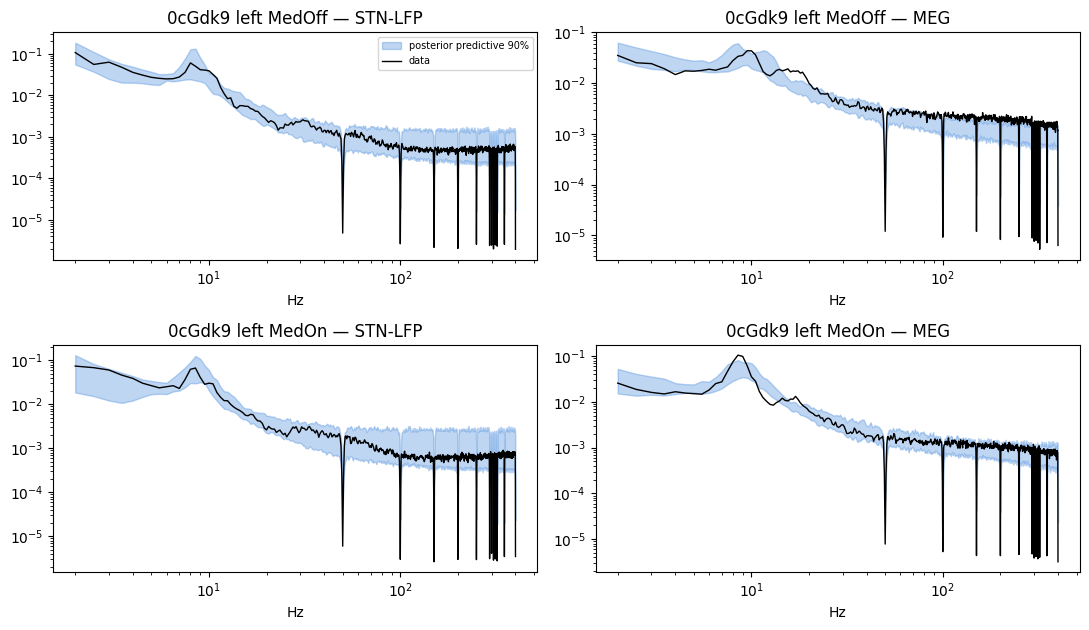

Mahalanobis: 8% of recordings beyond the simulations' 99th percentile
            stat  frac_outside  median_pct
   off_stn_rdsym          0.22        5.00
 d_meg_beta_pk_f          0.14       27.96
 off_meg_lf_pk_f          0.11       20.56
  off_stn_ap_exp          0.11       74.12
    d_meg_ap_exp          0.11       54.29
off_stn_beta_res          0.08       19.40
  off_meg_ap_exp          0.05       20.88
 d_stn_beta_pk_f          0.05       45.67
per-subject winning pathway:
H_GS_HFO      6
H_TC          3
H_GS          3
H_HD          3
none          1
H_SLOW        1
H_ctx         1
H_SLOW_HFO    1
RFX-BMS expected frequency: none 0.06, H_GS 0.21, H_SLOW 0.04, H_NOISE 0.06, H_HFO 0.04, H_GS_HFO 0.27, H_SLOW_HFO 0.05, H_NOISE_HFO 0.04, H_HD 0.09, H_TC 0.06, H_ctx 0.05, H_lock 0.04
RFX-BMS exceedance prob.:   none 0.00, H_GS 0.29, H_SLOW 0.00, H_NOISE 0.00, H_HFO 0.00, H_GS_HFO 0.66, H_SLOW_HFO 0.00, H_NOISE_HFO 0.00, H_HD 0.02, H_TC 0.01, H_ctx 0.00, H_lock 0.00
  classifier 0: 

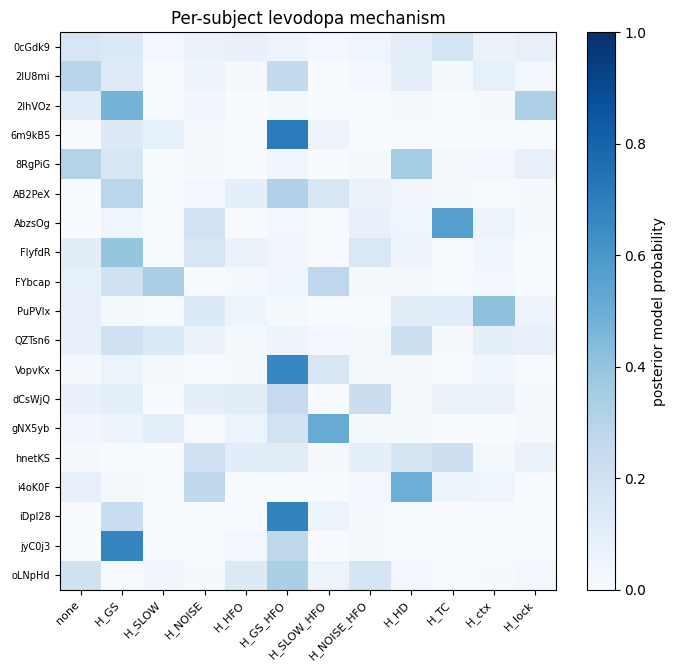

[ds004998] family 'beta_route': none freq 0.08 / XP 0.00, GPe-STN freq 0.72 / XP 1.00, slow input freq 0.06 / XP 0.00, noise freq 0.14 / XP 0.00
[ds004998] family 'HFO_shift': no freq 0.64 / XP 0.90, yes freq 0.36 / XP 0.10
Δθ (OFF−ON) vs Δ contralateral AR (Spearman):
   Δw_GS: ρ = -0.04, p = 0.827, n = 31
   Δw_CS: ρ = +0.32, p = 0.081, n = 31
   Δw_TC: ρ = +0.12, p = 0.513, n = 31
   Δf_H: ρ = +0.17, p = 0.373, n = 31
   Δlog10_aH: ρ = -0.11, p = 0.540, n = 31
   Δlam_H: ρ = -0.17, p = 0.375, n = 31
   Δsig_slow: ρ = -0.04, p = 0.831, n = 31


In [11]:
def ood_report(X_emp, X_sim, names, return_flags=False):
    Xs = X_sim[np.isfinite(X_sim).all(1)]; mu = Xs.mean(0); icov = np.linalg.pinv(np.cov(Xs.T))
    md = lambda X: np.sqrt(np.einsum("ij,jk,ik->i", X - mu, icov, X - mu))
    thr = np.percentile(md(Xs), 99)
    pct = np.array([[stats.percentileofscore(Xs[:, j], v) if np.isfinite(v) else np.nan for j, v in enumerate(x)] for x in X_emp])
    rep = pd.DataFrame(dict(stat=names, frac_outside=np.nanmean((pct < 0.5) | (pct > 99.5), 0), median_pct=np.nanmedian(pct, 0)))
    d = md(np.nan_to_num(X_emp)); print(f"Mahalanobis: {np.mean(d > thr):.0%} of recordings beyond the simulations' 99th percentile")
    rep = rep.sort_values("frac_outside", ascending=False)
    return (rep, d > thr) if return_flags else rep


# v4.2.1: exclusion is by out-of-distribution distance, not by posterior mass inside the prior. With 19
# parameters the flow leaks a little mass past every box edge (≈ 8 % per dimension → ≈ 20 % inside overall),
# so a 0.5 in-prior threshold excluded recordings the model reproduces well. MIN_INPRIOR now only guarantees
# enough in-prior samples to summarise the posterior.
MIN_INPRIOR = 0.002     # v4.3: rejection sampling; only near-total leakage excludes

if RUN_FIT and RUN_SBI and RUN_DATA and len(M_DS):
    X_EMP = M_DS[STAT_NAMES].values.astype(float)
    _rep, OOD_FLAG = ood_report(X_EMP, X_BANK, STAT_NAMES, return_flags=True)
    print(_rep.head(15).round(2).to_string(index=False))
    rows = []; SAMP = {}
    for (_, r), x, ood in zip(M_DS.iterrows(), X_EMP, OOD_FLAG):
        if not np.isfinite(x).all():
            continue
        s, frac = post_samples(POSTERIOR, x, 4000, return_frac=True)
        SAMP[(r.subject, r.side, r.med)] = s
        rows.append(dict(subject=r.subject, side=r.side, med=r.med, inprior=frac, ood=bool(ood), **dict(zip(PRIOR_NAMES, s.mean(0))),
                         **{p + "_sd": v for p, v in zip(PRIOR_NAMES, s.std(0))}))
    FIT = pd.DataFrame(rows); FIT.to_csv(OUT_DIR / "ds_fitted_parameters.csv", index=False)
    keep = (FIT.inprior >= MIN_INPRIOR) & ~FIT.ood
    print(f"posterior mass inside prior: median {FIT.inprior.median():.2f}; excluded: {FIT.ood.sum()} out-of-distribution, "
          f"{(FIT.inprior < MIN_INPRIOR).sum()} with < {MIN_INPRIOR:.1%} in-prior mass → {keep.sum()}/{len(FIT)} fitted")
    FITg = FIT[keep]
    # boundary diagnostic: posterior means within 5 % of a prior edge
    span = PRIOR_HI - PRIOR_LO
    lo_pile = ((FITg[PRIOR_NAMES].values - PRIOR_LO) < 0.05 * span).mean(0)
    hi_pile = ((PRIOR_HI - FITg[PRIOR_NAMES].values) < 0.05 * span).mean(0)
    BND = pd.DataFrame(dict(param=PRIOR_NAMES, at_lower=lo_pile, at_upper=hi_pile))
    BND = BND[(BND.at_lower > 0.1) | (BND.at_upper > 0.1)]
    print("parameters whose posterior means sit within 5 % of a prior edge in > 10 % of recordings:")
    print(BND.round(2).to_string(index=False) if len(BND) else "   none")
    if FITg.empty:
        warnings.warn("no recording is inside the model's reach (posterior mass < MIN_INPRIOR everywhere): "
                      "read the out-of-distribution table above before going further")
    else:
        T_FIT = paired_table(FITg, PRIOR_NAMES, "fitted circuit parameters, OFF vs ON"); T_FIT.to_csv(OUT_DIR / "ds_param_change.csv", index=False)

    # 10.2b paired parameter test: posterior of θ_OFF − θ_ON per hemisphere (independent sessions → sample pairing)
    PAIRED = []
    rng_p = np.random.default_rng(0)
    for (sj, sd), g_ in FITg.groupby(["subject", "side"]):
        if set(g_.med) >= {"MedOff", "MedOn"}:
            a, b = SAMP[(sj, sd, "MedOff")], SAMP[(sj, sd, "MedOn")]
            m_ = min(len(a), len(b)); a = a[rng_p.permutation(len(a))[:m_]]; b = b[rng_p.permutation(len(b))[:m_]]
            d = a - b
            PAIRED.append(dict(subject=sj, side=sd, **{f"d_{p_}": d[:, i].mean() for i, p_ in enumerate(PRIOR_NAMES)},
                               **{f"P_dec_{p_}": (d[:, i] > 0).mean() for i, p_ in enumerate(PRIOR_NAMES)}))
    PAIRED = pd.DataFrame(PAIRED); PAIRED.to_csv(OUT_DIR / "ds_paired_parameter_change.csv", index=False)
    if len(PAIRED) > 4:
        print(f"Paired parameter change OFF→ON over {len(PAIRED)} hemispheres "
              "(Δ = OFF − ON; P_dec = posterior probability the parameter is lower ON):")
        rows_p = []
        for p_ in ("w_GS", "w_CS", "w_TC", "g_ctx", "log10_aH", "f_H", "lam_H", "sig_slow", "k_d", "w_TS", "f_T"):
            d_, P_ = PAIRED[f"d_{p_}"], PAIRED[f"P_dec_{p_}"]
            boot = np.array([rng_p.choice(d_.values, len(d_)).mean() for _ in range(2000)])
            rows_p.append(dict(param=p_, mean_delta=d_.mean(), ci95=f"[{np.percentile(boot, 2.5):.3g}, {np.percentile(boot, 97.5):.3g}]",
                               p_wilcoxon=stats.wilcoxon(d_).pvalue if len(d_) > 5 else np.nan, median_P_dec=P_.median(),
                               frac_P_dec_gt_0_9=(P_ > 0.9).mean(), frac_P_inc_gt_0_9=(P_ < 0.1).mean()))
        T_PAIRED = pd.DataFrame(rows_p); print(T_PAIRED.round(3).to_string(index=False))
        T_PAIRED.to_csv(OUT_DIR / "ds_paired_parameter_summary.csv", index=False)

    # 10.3 posterior predictive check (spectra of both sites); uses all fitted recordings if none passed
    ex = (FITg if len(FITg) else FIT).groupby("med").head(1).head(2)
    fig, axs = plt.subplots(len(ex), 2, figsize=(11, 3.2 * len(ex)), squeeze=False)
    for row, (_, r) in zip(axs, ex.iterrows()):
        rr = M_DS[(M_DS.subject == r.subject) & (M_DS.side == r.side) & (M_DS.med == r.med)].iloc[0]
        seg = None
        for pth in MAN[(MAN.subject == r.subject) & (MAN.med == r.med)].path:
            seg = preprocess_recording(pth)
            if seg is not None:
                break
        n = int(PIPE["seg_len"] * PIPE["fs"])
        dat = (seg["lfp"][rr.pair][:n], seg["grad"][seg["grad_names"].index(rr.grad)][:n])
        th = post_samples(POSTERIOR, rr[STAT_NAMES].values.astype(float), 12)
        rec = simulate_circuit(theta_to_sim(th), PIPE["seg_len"] + 2.0, seed=99)
        sims = observe(rec, th, np.random.default_rng(5))
        for ax, x, xs, lab in zip(row, dat, sims, ("STN-LFP", "MEG")):
            f, P = signal.welch(zs(x), PIPE["fs"], nperseg=int(2 * PIPE["fs"])); _, Ps = signal.welch(zs(xs), PIPE["fs"], nperseg=int(2 * PIPE["fs"]), axis=-1)
            m = (f >= 2) & (f <= 400); nrm = lambda Q: Q / Q[..., (f >= 2) & (f <= 45)].sum(-1, keepdims=True)
            ax.fill_between(f[m], np.percentile(nrm(Ps)[:, m], 5, 0), np.percentile(nrm(Ps)[:, m], 95, 0), color="#2a78d6", alpha=.3, label="posterior predictive 90%")
            ax.loglog(f[m], nrm(P)[m], "k", lw=1, label="data"); ax.set_title(f"{r.subject} {r.side} {r.med} — {lab}"); ax.set_xlabel("Hz")
    axs[0, 0].legend(fontsize=7); fig.tight_layout(); fig.savefig(OUT_DIR / "ds_ppc.png", dpi=200); plt.show()

    # 10.4 which pathway
    if RUN_MODELCOMP:
        off = M_DS[M_DS.med == "MedOff"].set_index(["subject", "side"]); on = M_DS[M_DS.med == "MedOn"].set_index(["subject", "side"])
        idx = off.index.intersection(on.index)
        Fe = pair_features(off.loc[idx, STAT_NAMES].values.astype(float), on.loc[idx, STAT_NAMES].values.astype(float))
        okf = np.isfinite(Fe).all(1)
        print(ood_report(Fe[okf], F_PAIR, [f"off_{s}" for s in STAT_NAMES] + [f"d_{s}" for s in STAT_NAMES]).head(8).round(2).to_string(index=False))
        P = MODEL_CLF.predict_proba(Fe[okf])
        LE = pd.DataFrame(np.log(np.clip(P, 1e-6, 1)), columns=HYPS, index=pd.MultiIndex.from_tuples(np.array(list(idx), dtype=object)[okf].tolist()))
        LEs = LE.groupby(level=0).sum()                       # two hemispheres → one subject
        freq, xp = rfx_bms(LEs.values)
        print("per-subject winning pathway:\n" + LEs.idxmax(1).value_counts().to_string())
        print("RFX-BMS expected frequency: " + ", ".join(f"{h} {v:.2f}" for h, v in zip(HYPS, freq)))
        print("RFX-BMS exceedance prob.:   " + ", ".join(f"{h} {v:.2f}" for h, v in zip(HYPS, xp)))
        best = HYPS[int(np.argmax(xp))]
        # robustness 1: three independently trained classifiers
        for k, c_ in enumerate(CLF_SEEDS):
            Pk = c_.predict_proba(Fe[okf]); LEk = pd.DataFrame(np.log(np.clip(Pk, 1e-6, 1)), columns=HYPS, index=LE.index).groupby(level=0).sum()
            fk, xk = rfx_bms(LEk.values); print(f"  classifier {k}: winner {HYPS[int(np.argmax(xk))]} (XP {xk.max():.2f}, freq {fk.max():.2f})")
        # robustness 2: leave one subject out
        xps = []
        for sj in LEs.index:
            _, xj = rfx_bms(LEs.drop(index=sj).values); xps.append(xj[HYPS.index(best)])
        print(f"  leave-one-subject-out XP({best}): min {min(xps):.2f}, median {np.median(xps):.2f} over {len(xps)} subjects")
        # per-subject posterior model probabilities
        PS = np.exp(LEs.values - LEs.values.max(1, keepdims=True)); PS /= PS.sum(1, keepdims=True)
        fig, ax = plt.subplots(figsize=(7, 0.28 * len(PS) + 1.5))
        im = ax.imshow(PS, cmap="Blues", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(len(HYPS)), HYPS, rotation=45, ha="right", fontsize=8); ax.set_yticks(range(len(PS)), LEs.index, fontsize=7)
        fig.colorbar(im, label="posterior model probability"); ax.set_title("Per-subject levodopa mechanism")
        fig.tight_layout(); fig.savefig(OUT_DIR / "ds_model_probabilities.png", dpi=200); plt.show()
        pd.DataFrame(PS, index=LEs.index, columns=HYPS).to_csv(OUT_DIR / "ds_model_probabilities.csv")
        FAM_DS = family_bms(LEs, "ds004998")

    # 10.5 pathway change vs clinical change
    UPDRS = load_updrs(DS_ROOT)
    if len(UPDRS) == 2 and len(FITg):
        off = FITg[FITg.med == "MedOff"].set_index(["subject", "side"]); on = FITg[FITg.med == "MedOn"].set_index(["subject", "side"])
        idx = off.index.intersection(on.index)
        print("Δθ (OFF−ON) vs Δ contralateral AR (Spearman):")
        for p in ("w_GS", "w_CS", "w_TC", "f_H", "log10_aH", "lam_H", "sig_slow"):
            dm, du = [], []
            for s, side in idx:
                col = "AR left" if side == "right" else "AR right"
                try:
                    du.append(float(UPDRS["MedOff"].loc[s, col]) - float(UPDRS["MedOn"].loc[s, col])); dm.append(off.loc[(s, side), p] - on.loc[(s, side), p])
                except (KeyError, ValueError, TypeError):
                    pass
            ok = np.isfinite(dm) & np.isfinite(du)
            if ok.sum() > 5:
                rho, pv = stats.spearmanr(np.array(dm)[ok], np.array(du)[ok]); print(f"   Δ{p}: ρ = {rho:+.2f}, p = {pv:.3f}, n = {ok.sum()}")

## 10.6 Joint OFF/ON network: which parameters does levodopa change?

The classifier (§6, §10.4) compares 12 discrete hypotheses; the single-session posteriors (§10.2b) fit OFF
and ON independently. Neither directly asks *how much each parameter changes in the same hemisphere*. This
network does: it sees OFF and ON together, x = [S_OFF, S_ON − S_OFF], and returns the joint posterior of
θ_OFF and Δθ for 11 candidate parameters.

**Change prior (neutral, sparse, two-sided).** Every candidate parameter independently changes with
probability 0.5; if it changes, Δ ~ U(−w, +w) (log-ratio for gains, additive otherwise); if not, Δ ~ N(0, 0.02w).
Increases and decreases are equally likely a priori, so P(Δ < 0) is not pushed in either direction, and all
parameters can change at once, so the network must disentangle them. P(decrease) is P(Δ < −ε) with ε = 0.1·w;
the prior value is 0.225. Session nuisance (SNR, low-frequency component, α) is the same as in §6, and the
aperiodic exponent χ_S is a candidate too (aperiodic steepening ON levodopa, Wiest et al. 2023).

OFF simulations are the §4 bank (already simulated); only the ON partner of each is new.

**Validation before data:** (a) held-out pairs (recovery R², 90% coverage, AUC of P(decrease));
(b) attribution on the §6 hypothesis pairs: does an H_NOISE pair get blamed on w_GS?
(c) posterior predictive check: θ_OFF and Δθ drawn from the posteriors must reproduce the observed OFF→ON
changes better than a no-mechanism null (nuisance changes only).

loaded joint_24176_4cd50520a75b_j1v5.npz
loaded jnpe_full_24176_4cd50520a75b_j1v5_s0.pt
joint network, held-out pairs (n = 400):
    param    R2  coverage90  AUC_decrease  mean_Pdec_if_true_dec  mean_Pdec_if_not
     w_GS 0.592       0.920         0.908                  0.593             0.137
 sig_slow 0.327       0.880         0.868                  0.491             0.157
log10_sig 0.525       0.870         0.860                  0.536             0.150
     w_CS 0.016       0.875         0.650                  0.256             0.206
     w_TC 0.352       0.890         0.822                  0.415             0.142
    g_ctx 0.475       0.900         0.824                  0.442             0.140
      k_d 0.451       0.892         0.834                  0.464             0.125
 log10_aH 0.046       0.915         0.657                  0.254             0.194
      f_H 0.102       0.890         0.668                  0.275             0.202
    lam_H 0.006       0.935         0.595

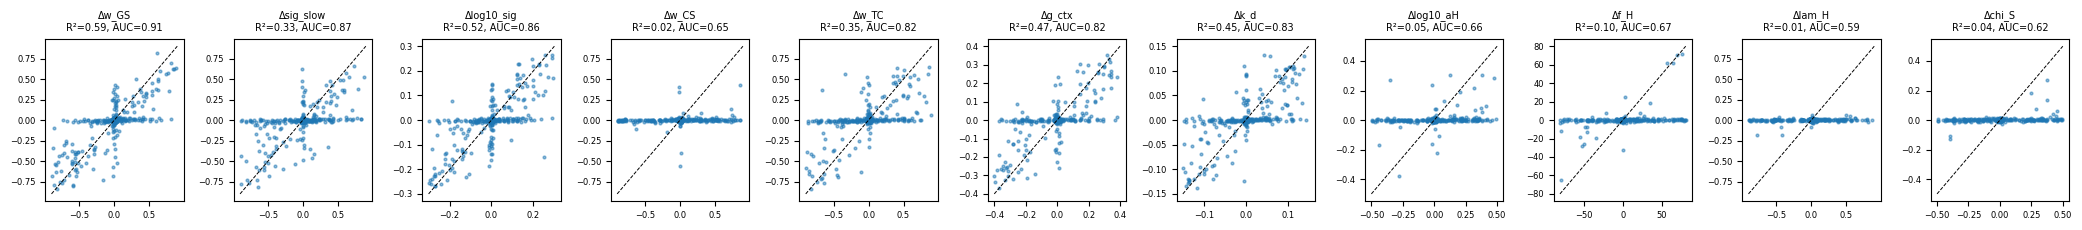

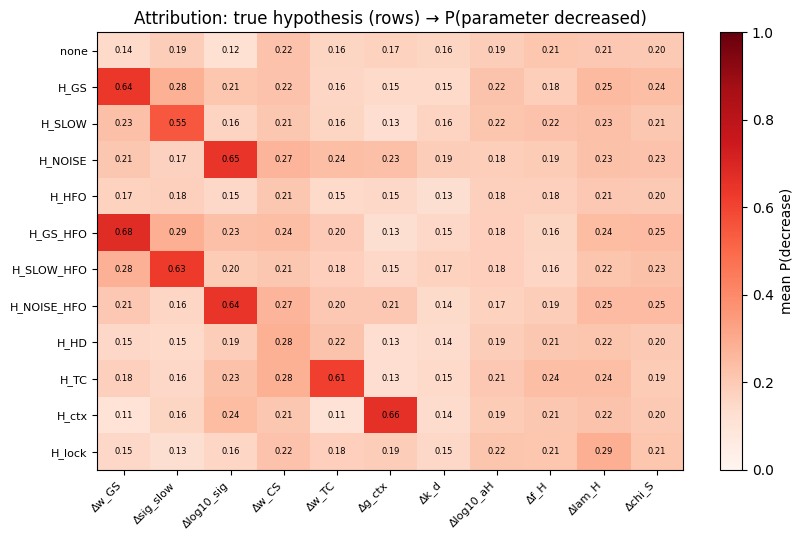

attribution, mean P(decrease) (rows = true hypothesis of the §6 pairs):
             w_GS  sig_slow  log10_sig  w_CS  w_TC  g_ctx   k_d  log10_aH   f_H  lam_H  chi_S
none         0.14      0.19       0.12  0.22  0.16   0.17  0.16      0.19  0.21   0.21   0.20
H_GS         0.64      0.28       0.21  0.22  0.16   0.15  0.15      0.22  0.18   0.25   0.24
H_SLOW       0.23      0.55       0.16  0.21  0.16   0.13  0.16      0.22  0.22   0.23   0.21
H_NOISE      0.21      0.17       0.65  0.27  0.24   0.23  0.19      0.18  0.19   0.23   0.23
H_HFO        0.17      0.18       0.15  0.21  0.15   0.15  0.13      0.18  0.18   0.21   0.20
H_GS_HFO     0.68      0.29       0.23  0.24  0.20   0.13  0.15      0.18  0.16   0.24   0.25
H_SLOW_HFO   0.28      0.63       0.20  0.21  0.18   0.15  0.17      0.18  0.16   0.22   0.23
H_NOISE_HFO  0.21      0.16       0.64  0.27  0.20   0.21  0.14      0.17  0.19   0.25   0.25
H_HD         0.15      0.15       0.19  0.28  0.22   0.13  0.14      0.19  0.21   

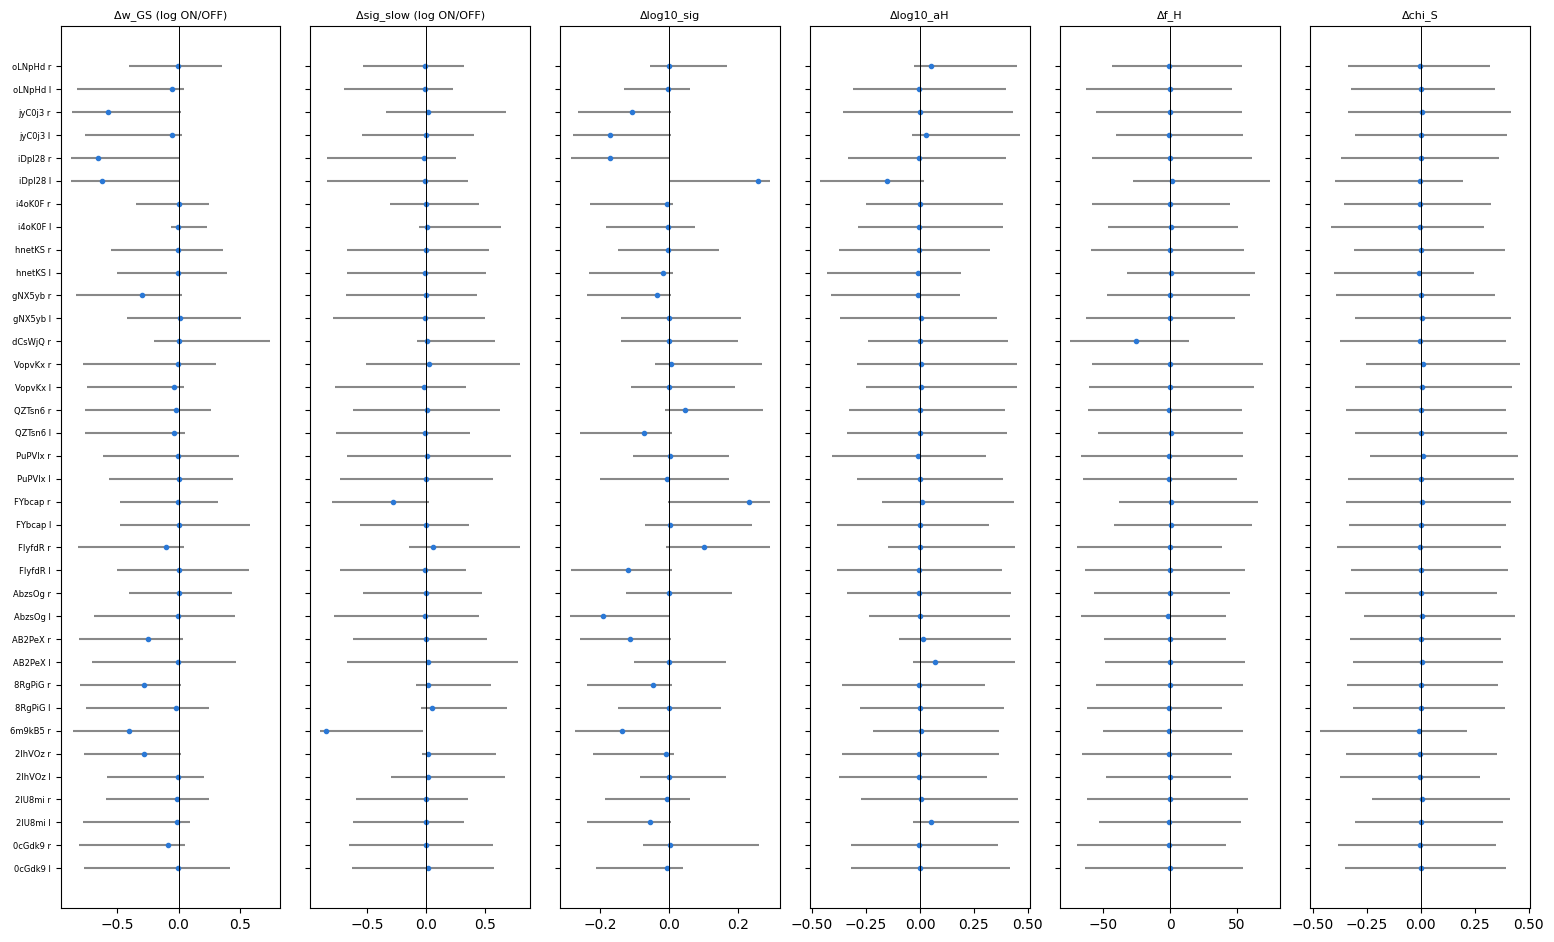

  288 sims: 100.0%  (  224 s)
    statistics: 54 s
  288 sims: 100.0%  (  224 s)
    statistics: 53 s
  288 sims: 100.0%  (  224 s)
    statistics: 53 s
  posterior predictive simulations: 864 (15.1 min)
posterior predictive OFF→ON change (ON − OFF): joint posterior vs no-mechanism null
          stat  obs_median  pred_median  null_median  rho_pred  rho_null  mae_pred  mae_null
  stn_beta_res      -0.064       -0.004       -0.000     0.488     0.482     0.085     0.079
stn_hfo_excess       0.017        0.001        0.000     0.013    -0.131     0.037     0.040
 stn_hfo_ratio       0.054        0.002        0.001     0.337     0.082     0.081     0.091
    stn_ap_exp      -0.032        0.023        0.009    -0.043    -0.035     0.212     0.195
     stn_pac_z       0.027       -0.162        0.032     0.194     0.045     2.037     2.511
  meg_beta_res       0.002        0.001        0.002     0.391     0.319     0.033     0.035
      coh_beta      -0.000        0.004        0.006     0.70

In [12]:
JOINT = {   # name: (kind, slab half-width w); "log" = log-ratio ln(ON/OFF), "add" = ON − OFF
    "w_GS": ("log", 0.9), "sig_slow": ("log", 0.9), "log10_sig": ("add", 0.3), "w_CS": ("log", 0.9),
    "w_TC": ("log", 0.9), "g_ctx": ("log", 0.4), "k_d": ("log", 0.15), "log10_aH": ("add", 0.5),
    "f_H": ("add", 80.0), "lam_H": ("log", 0.9), "chi_S": ("add", 0.5)}
JP = list(JOINT); JIX = [IX[p] for p in JP]
J_EPS = np.array([0.1 * JOINT[p][1] for p in JP])
J_PCHANGE, J_SPIKE = 0.5, 0.02
J_TAG = "j1v5"
J_N = (2 * BATCH - N_RECOVERY) if QUICK else (JOINT_BATCHES * BATCH - N_RECOVERY)


def joint_perturb(th_off, rng):
    """θ_ON from θ_OFF under the neutral sparse change prior + session nuisance. Returns θ_ON and realised Δ."""
    th = th_off.copy(); n = len(th)
    for p in JP:
        kind, w = JOINT[p]; j = IX[p]
        ch = rng.random(n) < J_PCHANGE
        d = np.where(ch, rng.uniform(-w, w, n), rng.normal(0, J_SPIKE * w, n))
        th[:, j] = th[:, j] * np.exp(d) if kind == "log" else th[:, j] + d
    th[:, IX["snr_S"]] += rng.normal(0, 1.5, n); th[:, IX["snr_C"]] += rng.normal(0, 1.5, n)
    th[:, IX["f_T"]] += rng.normal(0, 1.0, n); th[:, IX["bw_T"]] *= np.exp(rng.normal(0, 0.3, n))
    th[:, IX["w_TS"]] *= np.exp(rng.normal(0, 0.4, n)); th[:, IX["w_TM"]] *= np.exp(rng.normal(0, 0.4, n))
    th[:, IX["f_a"]] += rng.normal(0, 0.5, n); th[:, IX["w_a"]] *= np.exp(rng.normal(0, 0.2, n))
    th = np.clip(th, PRIOR_LO, PRIOR_HI)
    return th, realised_delta(th_off, th)


def realised_delta(th_off, th_on):
    D = np.empty((len(th_off), len(JP)))
    for k, p in enumerate(JP):
        j = IX[p]
        D[:, k] = (np.log(np.maximum(th_on[:, j], 1e-9) / np.maximum(th_off[:, j], 1e-9)) if JOINT[p][0] == "log"
                   else th_on[:, j] - th_off[:, j])
    return D


def apply_delta(th_off, D):
    th = th_off.copy()
    for k, p in enumerate(JP):
        j = IX[p]
        th[:, j] = th[:, j] * np.exp(D[:, k]) if JOINT[p][0] == "log" else th[:, j] + D[:, k]
    return np.clip(th, PRIOR_LO, PRIOR_HI)


J_W = np.array([JOINT[p][1] for p in JP])
J_LO = np.r_[PRIOR_LO[JIX], -1.001 * J_W]; J_HI = np.r_[PRIOR_HI[JIX], 1.001 * J_W]
J_NAMES = [f"off_{p}" for p in JP] + [f"d_{p}" for p in JP]


def joint_bank():
    """ON partners for the first J_N bank simulations (train) and for the held-out test simulations."""
    fn = OUT_DIR / f"joint_{J_N}_{config_hash()}_{J_TAG}.npz"
    th_off = np.concatenate([THETA_BANK[:J_N], THETA_TEST]); S_off = np.concatenate([X_BANK[:J_N], X_TEST])
    if fn.exists():
        d = np.load(fn); print(f"loaded {fn.name}")
        return th_off, d["th_on"], d["D"], S_off, d["S_on"]
    th_on, D = joint_perturb(th_off, np.random.default_rng(SEED + 4242))
    t0 = time.time(); S_on = simulate_stats(th_on, SEED + 900_000)
    print(f"  joint bank: {len(th_on)} ON simulations ({(time.time() - t0) / 60:.1f} min)")
    np.savez(fn, th_on=th_on, D=D, S_on=S_on)
    return th_off, th_on, D, S_off, S_on


def make_joint_npe(phi, F, tag, seed=0):
    fn = OUT_DIR / f"jnpe_{tag}_{len(phi)}_{config_hash()}_{J_TAG}_s{seed}.pt"
    if fn.exists():
        print(f"loaded {fn.name}"); return torch.load(fn, weights_only=False)
    from sbi.utils import BoxUniform
    try:
        from sbi.inference import NPE
    except ImportError:
        from sbi.inference import SNPE as NPE
    torch.manual_seed(seed)
    good = np.isfinite(F).all(1) & np.isfinite(phi).all(1)
    prior = BoxUniform(torch.tensor(J_LO, dtype=torch.float32), torch.tensor(J_HI, dtype=torch.float32))
    inf = NPE(prior=prior, density_estimator="nsf")
    inf.append_simulations(torch.tensor(phi[good], dtype=torch.float32), torch.tensor(F[good], dtype=torch.float32))
    t0 = time.time(); post = inf.build_posterior(inf.train(show_train_summary=False))
    print(f"  joint network '{tag}' trained on {good.sum()} pairs ({(time.time() - t0) / 60:.1f} min)")
    try:
        torch.save(post, fn)
    except Exception as e:
        warnings.warn(f"could not cache ({e})")
    return post


def joint_samples(post, x, n=2000, max_draws=200_000, chunk=20_000):
    xt = torch.tensor(np.asarray(x, float), dtype=torch.float32); keep, drawn = [], 0
    while drawn < max_draws:
        m = min(chunk, max_draws - drawn) if drawn else max(n, 2000)
        s = post.sample((m,), x=xt, show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy(); drawn += m
        keep.append(s[((s >= J_LO) & (s <= J_HI)).all(1)])
        if sum(len(k) for k in keep) >= n:
            break
    inside = np.concatenate(keep)
    return inside[:n] if len(inside) >= 50 else np.clip(s[:n], J_LO, J_HI)


def joint_summary(s):
    """Per-parameter posterior summary of Δ from joint samples s (n, 2·len(JP))."""
    D = s[:, len(JP):]
    out = {}
    for k, p in enumerate(JP):
        d = D[:, k]; pdec = (d < -J_EPS[k]).mean(); pinc = (d > J_EPS[k]).mean()
        out.update({f"med_{p}": np.median(d), f"lo_{p}": np.percentile(d, 5), f"hi_{p}": np.percentile(d, 95),
                    f"Pdec_{p}": pdec, f"Pinc_{p}": pinc, f"Pnull_{p}": 1 - pdec - pinc})
    return out


J_PRIOR_DEC = J_PCHANGE * 0.5 * 0.9          # P(Δ < −0.1w) under the change prior = 0.225


def _auc(y, s):
    from sklearn.metrics import roc_auc_score
    return roc_auc_score(y, s) if 0 < np.mean(y) < 1 else np.nan


def joint_group_table(SUM, Ssamp, label, seed=0):
    """Group-level Δ: per-hemisphere posteriors combined by averaging one draw per hemisphere (posterior of the
    cohort-mean change, hemispheres independent), plus counts of confident hemispheres."""
    rng = np.random.default_rng(seed)
    S = np.stack([s_[rng.integers(0, len(s_), 4000), len(JP):] for s_ in Ssamp])      # (H, 4000, P)
    G = S.mean(0)
    rows = []
    for k, p in enumerate(JP):
        kind = JOINT[p][0]
        fmt = (lambda v: f"×{np.exp(v):.2f}") if kind == "log" else (lambda v: f"{v:+.3g}")
        med = SUM[f"med_{p}"]
        rows.append(dict(param=p, group_mean=fmt(np.median(G[:, k])),
                         ci90=f"[{fmt(np.percentile(G[:, k], 5))}, {fmt(np.percentile(G[:, k], 95))}]",
                         P_group_dec=(G[:, k] < 0).mean(),
                         median_Pdec=SUM[f"Pdec_{p}"].median(), median_Pinc=SUM[f"Pinc_{p}"].median(),
                         n_dec_gt_0_9=int((SUM[f"Pdec_{p}"] > 0.9).sum()), n_inc_gt_0_9=int((SUM[f"Pinc_{p}"] > 0.9).sum()),
                         p_wilcoxon=stats.wilcoxon(med).pvalue if len(med) > 5 else np.nan))
    T = pd.DataFrame(rows)
    print(f"[{label}] joint OFF/ON posterior over {len(Ssamp)} hemispheres (gains as ON/OFF factor; "
          f"prior P(dec) = {J_PRIOR_DEC:.3f} per hemisphere, prior P(group mean < 0) = 0.5):")
    print(T.round(3).to_string(index=False))
    return T


if RUN_JOINT and RUN_SBI:
    J_TH_OFF, J_TH_ON, J_D, J_S_OFF, J_S_ON = joint_bank()
    J_PHI = np.column_stack([J_TH_OFF[:, JIX], J_D]); J_F = pair_features(J_S_OFF, J_S_ON)
    ntr = J_N
    JPOST = make_joint_npe(J_PHI[:ntr], J_F[:ntr], "full")

    # (a) held-out recovery
    te = np.arange(ntr, len(J_PHI)); te = te[np.isfinite(J_F[te]).all(1)]
    med, lo, hi, pdec = [], [], [], []
    for i in te:
        s_ = joint_samples(JPOST, J_F[i], 1000); d = s_[:, len(JP):]
        med.append(np.median(d, 0)); lo.append(np.percentile(d, 5, 0)); hi.append(np.percentile(d, 95, 0)); pdec.append((d < -J_EPS).mean(0))
    med, lo, hi, pdec = map(np.array, (med, lo, hi, pdec)); tru = J_D[te]
    from sklearn.metrics import roc_auc_score
    JREC = pd.DataFrame(dict(param=JP,
                             R2=[1 - ((med[:, k] - tru[:, k]) ** 2).sum() / ((tru[:, k] - tru[:, k].mean()) ** 2).sum() for k in range(len(JP))],
                             coverage90=[np.mean((tru[:, k] >= lo[:, k]) & (tru[:, k] <= hi[:, k])) for k in range(len(JP))],
                             AUC_decrease=[_auc(tru[:, k] < -J_EPS[k], pdec[:, k]) for k in range(len(JP))],
                             mean_Pdec_if_true_dec=[pdec[tru[:, k] < -J_EPS[k], k].mean() for k in range(len(JP))],
                             mean_Pdec_if_not=[pdec[tru[:, k] >= -J_EPS[k], k].mean() for k in range(len(JP))]))
    print(f"joint network, held-out pairs (n = {len(te)}):"); print(JREC.round(3).to_string(index=False))
    JREC.to_csv(OUT_DIR / "joint_recovery.csv", index=False)
    fig, axs = plt.subplots(1, len(JP), figsize=(1.9 * len(JP), 2.4))
    for k, ax in enumerate(axs):
        ax.scatter(tru[:, k], med[:, k], s=4, alpha=.5); w = J_W[k]; ax.plot([-w, w], [-w, w], "k--", lw=.7)
        ax.set_title(f"Δ{JP[k]}\nR²={JREC.R2[k]:.2f}, AUC={JREC.AUC_decrease[k]:.2f}", fontsize=7); ax.tick_params(labelsize=6)
    fig.tight_layout(); fig.savefig(OUT_DIR / "joint_recovery.png", dpi=200); plt.show()

    # (b) attribution on the §6 hypothesis pairs: P(decrease) per parameter, per true hypothesis
    if RUN_MODELCOMP:
        rng_a = np.random.default_rng(3); ATT = np.zeros((len(HYPS), len(JP))); ATI = np.zeros_like(ATT)
        for h in range(len(HYPS)):
            ii = rng_a.choice(np.where(Y_PAIR == h)[0], min(60, (Y_PAIR == h).sum()), replace=False)
            dd = [joint_samples(JPOST, F_PAIR[i], 500)[:, len(JP):] for i in ii]
            P_ = np.array([(d_ < -J_EPS).mean(0) for d_ in dd]); Q_ = np.array([(d_ > J_EPS).mean(0) for d_ in dd])
            ATT[h], ATI[h] = P_.mean(0), Q_.mean(0)
        fig, ax = plt.subplots(figsize=(8.5, 5.5)); im = ax.imshow(ATT, cmap="Reds", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(len(JP)), [f"Δ{p}" for p in JP], rotation=45, ha="right", fontsize=8); ax.set_yticks(range(len(HYPS)), HYPS, fontsize=8)
        for i in range(len(HYPS)):
            for j in range(len(JP)):
                ax.text(j, i, f"{ATT[i, j]:.2f}", ha="center", va="center", fontsize=6)
        fig.colorbar(im, label="mean P(decrease)"); ax.set_title("Attribution: true hypothesis (rows) → P(parameter decreased)")
        fig.tight_layout(); fig.savefig(OUT_DIR / "joint_attribution.png", dpi=200); plt.show()
        print("attribution, mean P(decrease) (rows = true hypothesis of the §6 pairs):")
        print(pd.DataFrame(ATT, index=HYPS, columns=JP).round(2).to_string())
        pd.DataFrame(ATT, index=HYPS, columns=JP).to_csv(OUT_DIR / "joint_attribution_Pdec.csv")
        pd.DataFrame(ATI, index=HYPS, columns=JP).to_csv(OUT_DIR / "joint_attribution_Pinc.csv")

    # (c) ds004998
    if RUN_DATA and len(M_DS):
        off = M_DS[M_DS.med == "MedOff"].set_index(["subject", "side"]); on = M_DS[M_DS.med == "MedOn"].set_index(["subject", "side"])
        idj = off.index.intersection(on.index)
        Fj = pair_features(off.loc[idj, STAT_NAMES].values.astype(float), on.loc[idj, STAT_NAMES].values.astype(float))
        okj = np.isfinite(Fj).all(1)
        _rep, OOD_J = ood_report(Fj[okj], J_F[:ntr], [f"off_{s}" for s in STAT_NAMES] + [f"d_{s}" for s in STAT_NAMES], return_flags=True)
        print(_rep.head(8).round(2).to_string(index=False))
        JS_DS, rows_j = {}, []
        for (sj, sd), x, ood in zip(np.array(list(idj), dtype=object)[okj], Fj[okj], OOD_J):
            s_ = joint_samples(JPOST, x, 4000); JS_DS[(sj, sd)] = s_
            rows_j.append(dict(subject=sj, side=sd, ood=bool(ood), **joint_summary(s_)))
        JSUM_DS = pd.DataFrame(rows_j); JSUM_DS.to_csv(OUT_DIR / "ds_joint_posterior.csv", index=False)
        ok_ = ~JSUM_DS.ood
        print(f"ds004998: {ok_.sum()}/{len(JSUM_DS)} OFF/ON pairs inside the joint simulations' reach")
        if ok_.sum() < 5:
            warnings.warn("fewer than 5 pairs inside the joint simulations' reach: summarising ALL pairs (interpret with care)")
            ok_ = pd.Series(True, index=JSUM_DS.index)
        T_JDS = joint_group_table(JSUM_DS[ok_], [JS_DS[(r.subject, r.side)] for r in JSUM_DS[ok_].itertuples()], "ds004998")
        T_JDS.to_csv(OUT_DIR / "ds_joint_group.csv", index=False)
        # forest plot of Δ per hemisphere for the β-route and HFO candidates
        show = ["w_GS", "sig_slow", "log10_sig", "log10_aH", "f_H", "chi_S"]
        fig, axs = plt.subplots(1, len(show), figsize=(2.6 * len(show), 0.22 * ok_.sum() + 1.6), sharey=True)
        Jg = JSUM_DS[ok_].reset_index(drop=True)
        for ax, p in zip(axs, show):
            y = np.arange(len(Jg)); ax.hlines(y, Jg[f"lo_{p}"], Jg[f"hi_{p}"], color="#888"); ax.plot(Jg[f"med_{p}"], y, "o", ms=3, color="#2a78d6")
            ax.axvline(0, color="k", lw=.7); ax.set_title(f"Δ{p}" + (" (log ON/OFF)" if JOINT[p][0] == "log" else ""), fontsize=8)
        axs[0].set_yticks(np.arange(len(Jg)), [f"{a} {b[0]}" for a, b in zip(Jg.subject, Jg.side)], fontsize=6)
        fig.tight_layout(); fig.savefig(OUT_DIR / "ds_joint_forest.png", dpi=200); plt.show()

        # (d) posterior predictive check of the OFF→ON change
        if RUN_FIT and "SAMP" in globals():
            PPC_STATS = ["stn_beta_res", "stn_hfo_excess", "stn_hfo_ratio", "stn_ap_exp", "stn_pac_z", "meg_beta_res", "coh_beta"]
            pc = [STAT_NAMES.index(s_) for s_ in PPC_STATS]; K = 8; rng_c = np.random.default_rng(11)
            TH_O, TH_N, TH_0, who = [], [], [], []
            NUIS = [IX[p] for p in ("snr_S", "snr_C", "f_T", "bw_T", "w_TS", "w_TM", "f_a", "w_a")]
            for r in JSUM_DS[ok_].itertuples():
                k_ = (r.subject, r.side)
                if (r.subject, r.side, "MedOff") not in SAMP or (r.subject, r.side, "MedOn") not in SAMP:
                    continue
                so, sn, sj_ = SAMP[(r.subject, r.side, "MedOff")], SAMP[(r.subject, r.side, "MedOn")], JS_DS[k_]
                a = so[rng_c.integers(0, len(so), K)].copy(); b = sn[rng_c.integers(0, len(sn), K)]; jj = sj_[rng_c.integers(0, len(sj_), K)]
                a[:, JIX] = jj[:, :len(JP)]
                ton = apply_delta(a, jj[:, len(JP):]); ton[:, NUIS] = b[:, NUIS]
                t0_ = a.copy(); t0_[:, NUIS] = b[:, NUIS]          # null: nuisance changes only
                TH_O.append(a); TH_N.append(ton); TH_0.append(t0_); who += [k_] * K
            if TH_O:
                TH_O, TH_N, TH_0 = map(np.concatenate, (TH_O, TH_N, TH_0))
                t0 = time.time()
                SO = simulate_stats(TH_O, SEED + 31); SN = simulate_stats(TH_N, SEED + 32); S0 = simulate_stats(TH_0, SEED + 33)
                print(f"  posterior predictive simulations: {3 * len(TH_O)} ({(time.time() - t0) / 60:.1f} min)")
                who = np.array(who, dtype=object)
                rows_c = []
                for c_, sname in zip(pc, PPC_STATS):
                    obs, pred, null = [], [], []
                    for k_ in dict.fromkeys(map(tuple, who)):
                        m_ = np.array([tuple(w_) == k_ for w_ in who])
                        obs.append(on.loc[k_, sname] - off.loc[k_, sname])
                        pred.append(np.nanmedian(SN[m_, c_] - SO[m_, c_])); null.append(np.nanmedian(S0[m_, c_] - SO[m_, c_]))
                    obs, pred, null = map(np.array, (obs, pred, null)); g_ = np.isfinite(obs) & np.isfinite(pred) & np.isfinite(null)
                    rows_c.append(dict(stat=sname, obs_median=np.median(obs[g_]), pred_median=np.median(pred[g_]), null_median=np.median(null[g_]),
                                       rho_pred=stats.spearmanr(obs[g_], pred[g_])[0], rho_null=stats.spearmanr(obs[g_], null[g_])[0],
                                       mae_pred=np.mean(np.abs(obs[g_] - pred[g_])), mae_null=np.mean(np.abs(obs[g_] - null[g_]))))
                T_PPC = pd.DataFrame(rows_c)
                print("posterior predictive OFF→ON change (ON − OFF): joint posterior vs no-mechanism null")
                print(T_PPC.round(3).to_string(index=False)); T_PPC.to_csv(OUT_DIR / "ds_joint_ppc.csv", index=False)

## 10.7 Full joint network and β-reachability analysis

**Why.** In v4.6 the joint posterior did not reproduce the observed β reduction (posterior predictive Δβ ≈ 0
vs observed −0.064). Two explanations: (1) the check mixed the joint posterior (11 OFF parameters) with the
separate single-session fits for the other 12, which need not be consistent; (2) the model cannot make the
β drop the way the data show it. This section separates them, without new bank simulations.

**(A) Full joint network:** same joint simulations, but the posterior now covers all 25 OFF parameters, the
11 candidate changes **and** the 8 session-nuisance changes (SNR, low-frequency component, α). The posterior
predictive check is then drawn from this one posterior: OFF match, ON match, OFF→ON change, and an
**ablation** (same draws with the 11 candidate changes set to zero) to show how much of the predicted change
is carried by the mechanism rather than by session nuisance.

**(B) β reachability:** for each hemisphere, the 300 joint simulations whose OFF statistics are closest to
that hemisphere's OFF data. Within them: how often a β drop as large as observed occurs; which parameter
changes produce it (drop-one R² of a linear model of Δβ on all changes; mean change in the pairs that reach
the observed drop); and whether the *other* OFF→ON changes that accompany such a β drop in the model
(β frequency, bursts, coherence, delay, HFO) match the data, i.e. whether the data's β drop carries the
model's signature.

loaded jnpe_full23_24176_4cd50520a75b_j1v5_s0.pt
full joint network, held-out recovery R²:
  Δ candidates: w_GS 0.59, sig_slow 0.38, log10_sig 0.52, w_CS 0.02, w_TC 0.40, g_ctx 0.42, k_d 0.39, log10_aH 0.04, f_H 0.08, lam_H 0.01, chi_S 0.03
  Δ nuisance:   snr_S 0.06, snr_C 0.18, f_T 0.13, bw_T -0.00, w_TS 0.12, w_TM 0.10, f_a 0.03, w_a 0.09
  OFF θ:        w_GS 0.83, w_CS 0.15, w_TC 0.52, log10_sig 0.90, log10_aH 0.57, log10_gC 0.26, snr_S 0.47, snr_C 0.38, chi_S 0.24, chi_C 0.32, f_a 0.44, w_a 0.40, k_d 0.85, g_ctx 0.72, log10_flS 0.32, log10_flC 0.35, f_H 0.31, lam_H 0.15, sig_slow 0.74, f_T 0.43, w_TS 0.33, w_TM 0.16, bw_T 0.04, kappa_H -0.03, nu_H -0.03
Mahalanobis: 3% of recordings beyond the simulations' 99th percentile
[ds004998, full joint network] joint OFF/ON posterior over 36 hemispheres (gains as ON/OFF factor; prior P(dec) = 0.225 per hemisphere, prior P(group mean < 0) = 0.5):
    param group_mean               ci90  P_group_dec  median_Pdec  median_Pinc  n_dec_gt_0_9  n

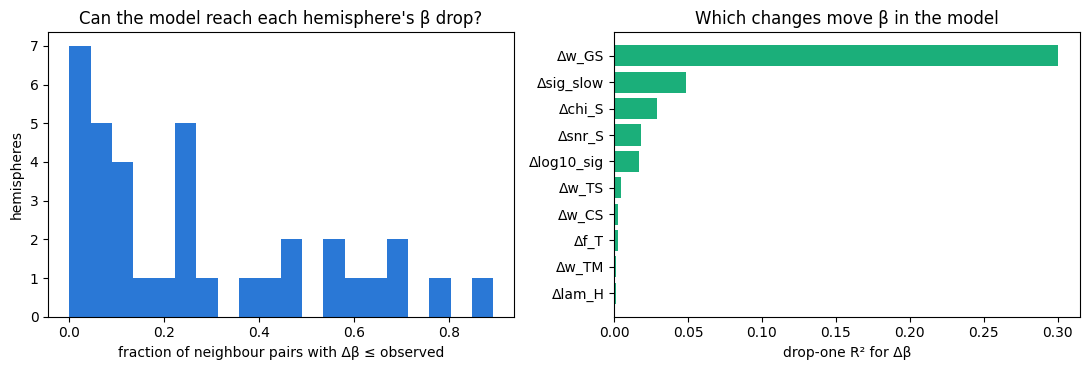

In [13]:
JNUIS = {"snr_S": "add", "snr_C": "add", "f_T": "add", "bw_T": "log", "w_TS": "log", "w_TM": "log", "f_a": "add", "w_a": "log"}
JNP = list(JNUIS); JNIX = [IX[p] for p in JNP]


def nuis_delta(th_off, th_on):
    return np.column_stack([np.log(np.maximum(th_on[:, IX[p]], 1e-9) / np.maximum(th_off[:, IX[p]], 1e-9)) if JNUIS[p] == "log"
                            else th_on[:, IX[p]] - th_off[:, IX[p]] for p in JNP])


def apply_full(th_off, Dm, Dn):
    th = apply_delta(th_off, Dm)
    for k, p in enumerate(JNP):
        j = IX[p]; th[:, j] = th[:, j] * np.exp(Dn[:, k]) if JNUIS[p] == "log" else th[:, j] + Dn[:, k]
    return np.clip(th, PRIOR_LO, PRIOR_HI)


def bounded_samples(post, x, lo, hi, n=2000, max_draws=200_000, chunk=20_000):
    xt = torch.tensor(np.asarray(x, float), dtype=torch.float32); keep, drawn = [], 0
    while drawn < max_draws:
        m = min(chunk, max_draws - drawn) if drawn else max(n, 2000)
        s = post.sample((m,), x=xt, show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy(); drawn += m
        keep.append(s[((s >= lo) & (s <= hi)).all(1)])
        if sum(len(k) for k in keep) >= n:
            break
    inside = np.concatenate(keep)
    return inside[:n] if len(inside) >= 50 else np.clip(s[:n], lo, hi)


def make_npe_bounded(phi, F, lo, hi, tag, seed=0):
    fn = OUT_DIR / f"jnpe_{tag}_{len(phi)}_{config_hash()}_{J_TAG}_s{seed}.pt"
    if fn.exists():
        print(f"loaded {fn.name}"); return torch.load(fn, weights_only=False)
    from sbi.utils import BoxUniform
    try:
        from sbi.inference import NPE
    except ImportError:
        from sbi.inference import SNPE as NPE
    torch.manual_seed(seed)
    good = np.isfinite(F).all(1) & np.isfinite(phi).all(1)
    inf = NPE(prior=BoxUniform(torch.tensor(lo, dtype=torch.float32), torch.tensor(hi, dtype=torch.float32)), density_estimator="nsf")
    inf.append_simulations(torch.tensor(phi[good], dtype=torch.float32), torch.tensor(F[good], dtype=torch.float32))
    t0 = time.time(); post = inf.build_posterior(inf.train(show_train_summary=False))
    print(f"  network '{tag}' ({phi.shape[1]} targets) trained on {good.sum()} pairs ({(time.time() - t0) / 60:.1f} min)")
    try:
        torch.save(post, fn)
    except Exception as e:
        warnings.warn(f"could not cache ({e})")
    return post


if RUN_JOINT and RUN_SBI and "J_F" in globals():
    # ---------------- (A) full joint network ----------------
    J_DN = nuis_delta(J_TH_OFF, J_TH_ON)
    FPHI = np.column_stack([J_TH_OFF, J_D, J_DN])
    nP, nM, nN = len(PRIOR_NAMES), len(JP), len(JNP)
    span_n = np.nanmax(np.abs(J_DN), 0) * 1.01 + 1e-6
    F_LO = np.r_[PRIOR_LO, -1.001 * J_W, -span_n]; F_HI = np.r_[PRIOR_HI, 1.001 * J_W, span_n]
    FPOST = make_npe_bounded(FPHI[:J_N], J_F[:J_N], F_LO, F_HI, "full23")
    te = np.arange(J_N, len(FPHI)); te = te[np.isfinite(J_F[te]).all(1)]
    med_ = np.array([np.median(bounded_samples(FPOST, J_F[i], F_LO, F_HI, 600), 0) for i in te]); tru_ = FPHI[te]
    r2 = lambda k: 1 - ((med_[:, k] - tru_[:, k]) ** 2).sum() / ((tru_[:, k] - tru_[:, k].mean()) ** 2).sum()
    print("full joint network, held-out recovery R²:")
    print("  Δ candidates: " + ", ".join(f"{p} {r2(nP + k):.2f}" for k, p in enumerate(JP)))
    print("  Δ nuisance:   " + ", ".join(f"{p} {r2(nP + nM + k):.2f}" for k, p in enumerate(JNP)))
    print("  OFF θ:        " + ", ".join(f"{p} {r2(k):.2f}" for k, p in enumerate(PRIOR_NAMES)))

    if RUN_DATA and len(M_DS):
        offd = M_DS[M_DS.med == "MedOff"].set_index(["subject", "side"]); ond = M_DS[M_DS.med == "MedOn"].set_index(["subject", "side"])
        idd = offd.index.intersection(ond.index)
        Fd = pair_features(offd.loc[idd, STAT_NAMES].values.astype(float), ond.loc[idd, STAT_NAMES].values.astype(float))
        okd = np.isfinite(Fd).all(1); KEYS = [tuple(k) for k in np.array(list(idd), dtype=object)[okd]]; Fd = Fd[okd]
        _, ood_d = ood_report(Fd, J_F[:J_N], [f"off_{s}" for s in STAT_NAMES] + [f"d_{s}" for s in STAT_NAMES], return_flags=True)
        if (~ood_d).sum() >= 5:
            KEYS = [k for k, o in zip(KEYS, ood_d) if not o]; Fd = Fd[~ood_d]
        FS_DS = {k: bounded_samples(FPOST, x, F_LO, F_HI, 4000) for k, x in zip(KEYS, Fd)}
        # cohort summary of the candidate changes under the full network (compare with §10.6)
        SUMF = pd.DataFrame([dict(subject=k[0], side=k[1], **joint_summary(np.column_stack([s_[:, JIX], s_[:, nP:nP + nM]])))
                             for k, s_ in FS_DS.items()])
        T_FULL = joint_group_table(SUMF, [np.column_stack([s_[:, JIX], s_[:, nP:nP + nM]]) for s_ in FS_DS.values()], "ds004998, full joint network")
        T_FULL.to_csv(OUT_DIR / "ds_fulljoint_group.csv", index=False)

        # posterior predictive check from the one posterior
        PPC2 = ["stn_beta_res", "stn_beta_pk_f", "stn_burst_dur", "stn_env_cv", "stn_hfo_excess", "stn_hfo_ratio", "stn_hfo_peak_f",
                "stn_ap_exp", "stn_pac_z", "meg_beta_res", "coh_beta", "delay_ms"]
        pc2 = [STAT_NAMES.index(s_) for s_ in PPC2]; K = 12; rng_c = np.random.default_rng(21)
        TO, TN, TA, who = [], [], [], []
        for k, s_ in FS_DS.items():
            d = s_[rng_c.integers(0, len(s_), K)]
            th_o = np.clip(d[:, :nP], PRIOR_LO, PRIOR_HI); Dm = d[:, nP:nP + nM]; Dn = d[:, nP + nM:]
            TO.append(th_o); TN.append(apply_full(th_o, Dm, Dn)); TA.append(apply_full(th_o, np.zeros_like(Dm), Dn)); who += [k] * K
        TO, TN, TA = map(np.concatenate, (TO, TN, TA)); t0 = time.time()
        SO = simulate_stats(TO, SEED + 41); SN = simulate_stats(TN, SEED + 42); SA = simulate_stats(TA, SEED + 43)
        print(f"  posterior predictive simulations: {3 * len(TO)} ({(time.time() - t0) / 60:.1f} min)")
        who_i = np.array([KEYS.index(k) for k in who])
        rows = []
        for c_, sname in zip(pc2, PPC2):
            r_ = dict(stat=sname)
            o_off = np.array([offd.loc[k, sname] for k in KEYS]); o_on = np.array([ond.loc[k, sname] for k in KEYS]); o_d = o_on - o_off
            for lab, A, B in (("pred", SO, SN), ("ablate", SO, SA)):
                dd = [(B[who_i == h, c_] - A[who_i == h, c_]) for h in range(len(KEYS))]
                pm = np.array([np.nanmedian(x) for x in dd])
                cov = np.array([np.nanpercentile(x, 5) <= o <= np.nanpercentile(x, 95) for x, o in zip(dd, o_d)])
                g_ = np.isfinite(pm) & np.isfinite(o_d)
                r_.update({f"{lab}_median": np.median(pm[g_]), f"{lab}_rho": stats.spearmanr(pm[g_], o_d[g_])[0],
                           f"{lab}_mae": np.mean(np.abs(pm[g_] - o_d[g_])), f"{lab}_cov90": cov[g_].mean()})
            off_cov = np.array([np.nanpercentile(SO[who_i == h, c_], 5) <= o <= np.nanpercentile(SO[who_i == h, c_], 95) for h, o in enumerate(o_off)])
            on_cov = np.array([np.nanpercentile(SN[who_i == h, c_], 5) <= o <= np.nanpercentile(SN[who_i == h, c_], 95) for h, o in enumerate(o_on)])
            r_.update(obs_median=np.median(o_d), OFF_cov90=off_cov.mean(), ON_cov90=on_cov.mean())
            rows.append(r_)
        T_PPC2 = pd.DataFrame(rows)[["stat", "obs_median", "pred_median", "ablate_median", "pred_rho", "ablate_rho", "pred_mae", "ablate_mae",
                                     "pred_cov90", "ablate_cov90", "OFF_cov90", "ON_cov90"]]
        print("posterior predictive check, full joint network (Δ = ON − OFF; cov90 = fraction of hemispheres whose observed value "
              "lies in the 90% predictive interval; 'ablate' = same draws, candidate changes set to 0):")
        print(T_PPC2.round(3).to_string(index=False)); T_PPC2.to_csv(OUT_DIR / "ds_fulljoint_ppc.csv", index=False)

        # ---------------- (B) β reachability ----------------
        from sklearn.neighbors import NearestNeighbors
        from sklearn.linear_model import LinearRegression
        jb = STAT_NAMES.index("stn_beta_res")
        Soff_tr, Son_tr = J_S_OFF[:J_N], J_S_ON[:J_N]
        okb = np.isfinite(Soff_tr).all(1) & np.isfinite(Son_tr).all(1)
        Soff_tr, Son_tr = Soff_tr[okb], Son_tr[okb]; Dm_tr, Dn_tr = J_D[:J_N][okb], J_DN[:J_N][okb]
        mu_, sd_ = Soff_tr.mean(0), Soff_tr.std(0) + 1e-9
        nn = NearestNeighbors(n_neighbors=300).fit((Soff_tr - mu_) / sd_)
        SIG = ["stn_beta_pk_f", "stn_burst_dur", "stn_burst_rate", "stn_env_cv", "stn_ap_exp", "stn_hfo_excess", "stn_hfo_ratio",
               "stn_pac_z", "meg_beta_res", "coh_beta", "delay_ms", "aec_beta"]
        sg = [STAT_NAMES.index(s_) for s_ in SIG]
        Xreg_names = [f"Δ{p}" for p in JP] + [f"Δ{p}" for p in JNP]
        reach, dropR2, big_mean, all_mean, sig_pct, n_big = [], [], [], [], [], []
        for k in KEYS:
            x_off = offd.loc[k, STAT_NAMES].values.astype(float); x_on = ond.loc[k, STAT_NAMES].values.astype(float)
            if not np.isfinite(x_off).all():
                continue
            _, ii = nn.kneighbors(((x_off - mu_) / sd_)[None]); ii = ii[0]
            dbeta = Son_tr[ii, jb] - Soff_tr[ii, jb]; obs = x_on[jb] - x_off[jb]
            reach.append((dbeta <= obs).mean())
            X_ = np.column_stack([Dm_tr[ii], Dn_tr[ii]]); X_ = (X_ - X_.mean(0)) / (X_.std(0) + 1e-9)
            full = LinearRegression().fit(X_, dbeta).score(X_, dbeta)
            dropR2.append([full - LinearRegression().fit(np.delete(X_, j, 1), dbeta).score(np.delete(X_, j, 1), dbeta) for j in range(X_.shape[1])] + [full])
            big = dbeta <= obs if (dbeta <= obs).sum() >= 20 else dbeta <= np.sort(dbeta)[19]
            n_big.append(big.sum())
            big_mean.append(Dm_tr[ii][big].mean(0)); all_mean.append(Dm_tr[ii].mean(0))
            dsig_sim = Son_tr[ii][big][:, sg] - Soff_tr[ii][big][:, sg]; dsig_obs = x_on[sg] - x_off[sg]
            sig_pct.append([stats.percentileofscore(dsig_sim[:, j][np.isfinite(dsig_sim[:, j])], dsig_obs[j]) if np.isfinite(dsig_obs[j]) else np.nan
                            for j in range(len(sg))])
        reach, dropR2, big_mean, all_mean, sig_pct = map(np.array, (reach, dropR2, big_mean, all_mean, sig_pct))
        obs_all = np.array([ond.loc[k, "stn_beta_res"] - offd.loc[k, "stn_beta_res"] for k in KEYS])
        print(f"\nβ reachability over {len(reach)} hemispheres (300 nearest OFF simulations each):")
        print(f"  fraction of neighbour pairs with Δβ ≤ observed: median {np.median(reach):.3f}; hemispheres where < 1%: "
              f"{np.mean(reach < 0.01):.0%}; where < 5%: {np.mean(reach < 0.05):.0%}")
        big_drop = obs_all < np.percentile(obs_all, 50)
        print(f"  (hemispheres with the larger half of β drops: median reach {np.median(reach[big_drop[:len(reach)]]):.3f})")
        T_R2 = pd.DataFrame(dict(change=Xreg_names + ["(full model R²)"], median_dropone_R2=np.median(dropR2, 0)))
        print("  what drives Δβ in the model near each hemisphere's OFF state (drop-one R², median over hemispheres):")
        print(T_R2.sort_values("median_dropone_R2", ascending=False).round(3).to_string(index=False))
        fmt_ = lambda p, v: f"×{np.exp(v):.2f}" if JOINT[p][0] == "log" else f"{v:+.3g}"
        T_BIG = pd.DataFrame(dict(param=JP, in_pairs_reaching_obs=[fmt_(p, v) for p, v in zip(JP, np.median(big_mean, 0))],
                                  all_neighbours=[fmt_(p, v) for p, v in zip(JP, np.median(all_mean, 0))]))
        print("  mean candidate change in neighbour pairs that reach the observed β drop vs all neighbours (median over hemispheres):")
        print(T_BIG.to_string(index=False))
        T_SIG = pd.DataFrame(dict(stat=SIG, median_pct=np.nanmedian(sig_pct, 0),
                                  frac_below_5=np.nanmean(sig_pct < 5, 0), frac_above_95=np.nanmean(sig_pct > 95, 0)))
        print("  signature test: percentile of each hemisphere's observed OFF→ON change among model pairs with the same β drop "
              "(50 = typical of the model; extreme = the data's β drop comes with a different pattern):")
        print(T_SIG.round(2).to_string(index=False))
        T_R2.to_csv(OUT_DIR / "beta_reach_drivers.csv", index=False); T_BIG.to_csv(OUT_DIR / "beta_reach_changes.csv", index=False)
        T_SIG.to_csv(OUT_DIR / "beta_reach_signature.csv", index=False)
        fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
        axs[0].hist(reach, 20, color="#2a78d6"); axs[0].set_xlabel("fraction of neighbour pairs with Δβ ≤ observed"); axs[0].set_ylabel("hemispheres")
        axs[0].set_title("Can the model reach each hemisphere's β drop?")
        o_ = np.argsort(np.median(dropR2[:, :-1], 0))[::-1][:10]
        axs[1].barh(np.array(Xreg_names)[o_][::-1], np.median(dropR2[:, :-1], 0)[o_][::-1], color="#1baf7a")
        axs[1].set_xlabel("drop-one R² for Δβ"); axs[1].set_title("Which changes move β in the model")
        fig.tight_layout(); fig.savefig(OUT_DIR / "beta_reachability.png", dpi=200); plt.show()

## 10.8 Does the HFO prediction need the β-state gate?

v5's joint posterior explains levodopa's HFO increase without an HFO change of its own (Δa_H, Δf_H ≈ 0), via the
β-state gate (κ_H, ν_H). But κ_H and ν_H are not identifiable (recovery R² ≈ 0), so the explanation could rest on
the prior. This section re-simulates the §10.7 posterior draws three ways, with **identical circuit runs and noise**
(one circuit simulation per session; only the HFO generator differs):

* **gated** — as fitted;
* **frozen gate** — E_β(t) replaced in BOTH sessions by the OFF session's mean β state (geometric mean). The OFF HFO
  level is unchanged, but the ON HFO no longer follows the ON β state: any predicted HFO change must come from
  Δa_H, Δf_H or the circuit's spiking (λ_H·S);
* **no gate** — κ_H = ν_H = 0 (a simpler but cruder ablation: also changes the OFF HFO level).

If the predicted HFO change and its fit to the data (coverage, ρ, MAE) collapse under the frozen gate, the HFO
increase is explained by the β change through the gate. Also reported: the posterior of κ_H, ν_H (cohort mean vs
prior), and how the predicted HFO change depends on κ_H across draws.

  432 sims: 100.0%  (  232 s)
  432 sims: 100.0%  (  232 s)
  gate ablation: 864 circuit runs × 3 observation variants (18.6 min)
predicted OFF→ON change under the fitted gate, a frozen gate and no gate (same circuit runs and noise):
          stat variant  obs_median  pred_median  pred_mean    rho    mae  cov90
stn_hfo_excess   gated       0.017        0.001      0.000  0.536  0.032  0.778
stn_hfo_excess  frozen       0.017        0.000     -0.002  0.599  0.035  0.639
stn_hfo_excess  nogate       0.017       -0.000     -0.001  0.691  0.037  0.556
 stn_hfo_ratio   gated       0.054        0.002      0.013  0.479  0.079  0.694
 stn_hfo_ratio  frozen       0.054       -0.000      0.007  0.438  0.084  0.694
 stn_hfo_ratio  nogate       0.054        0.001      0.004  0.447  0.088  0.583
stn_hfo_peak_f   gated      -2.500        0.000      0.792  0.045 30.597  0.694
stn_hfo_peak_f  frozen      -2.500        0.000     -1.903  0.027 31.208  0.750
stn_hfo_peak_f  nogate      -2.500        0.25

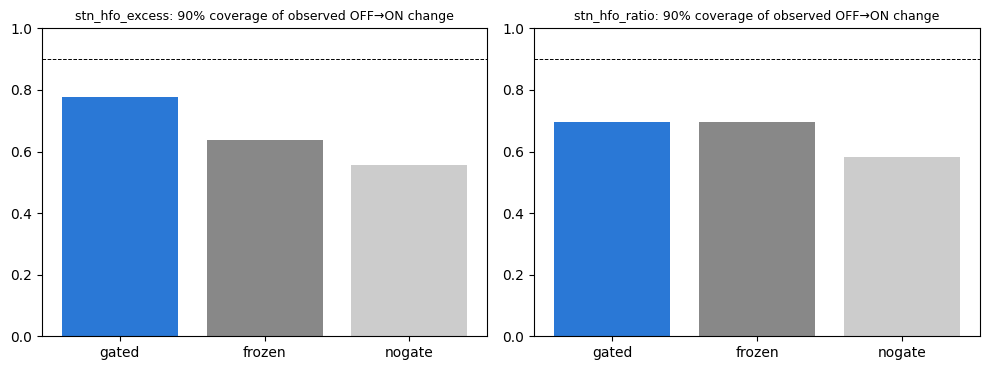

In [14]:
def run_variants(TH_off, TH_on, seed):
    """One circuit run per session; three observation variants each. Returns dict variant → (S_off, S_on)."""
    T = PIPE["seg_len"] + 2.0; fs = PIPE["fs"]; out = {v: ([], []) for v in ("gated", "frozen", "nogate")}
    for s0 in range(0, len(TH_off), BATCH):
        a, b = TH_off[s0:s0 + BATCH], TH_on[s0:s0 + BATCH]
        ln_ref = None
        for si, th in enumerate((a, b)):
            rec = simulate_circuit(theta_to_sim(th), T, seed=seed + 100 * si + s0, verbose=True)
            if si == 0:
                d0 = int(2.0 * fs); u = rec["uS"][:, d0:].astype(float)
                ln_ref = np.log(beta_state(u - u.mean(-1, keepdims=True), fs)).mean(-1)
            th0 = th.copy(); th0[:, IX["kappa_H"]] = 0.0; th0[:, IX["nu_H"]] = 0.0
            for v, (tt, kw) in {"gated": (th, {}), "frozen": (th, dict(lnEb_const=ln_ref)), "nogate": (th0, {})}.items():
                lfp, meg = observe(rec, tt, np.random.default_rng(seed + 11 + 100 * si + s0), **kw)
                out[v][si].append(compute_stats_parallel(lfp, meg)); del lfp, meg
            del rec
    return {v: (np.concatenate(o[0]), np.concatenate(o[1])) for v, o in out.items()}


if RUN_JOINT and RUN_SBI and "FS_DS" in globals():
    K = 12; rng_g = np.random.default_rng(51)
    GO, GN, who_g, KAP, NU = [], [], [], [], []
    for h, (k, s_) in enumerate(FS_DS.items()):
        d = s_[rng_g.integers(0, len(s_), K)]
        th_o = np.clip(d[:, :nP], PRIOR_LO, PRIOR_HI)
        GO.append(th_o); GN.append(apply_full(th_o, d[:, nP:nP + nM], d[:, nP + nM:])); who_g += [h] * K
    GO, GN = np.concatenate(GO), np.concatenate(GN); who_g = np.array(who_g)
    fn_g = OUT_DIR / f"gate_ablation_{len(GO)}_{config_hash()}_{J_TAG}.npz"
    if fn_g.exists():
        d_ = np.load(fn_g); VAR = {v: (d_[f"{v}_off"], d_[f"{v}_on"]) for v in ("gated", "frozen", "nogate")}; print(f"loaded {fn_g.name}")
    else:
        t0 = time.time(); VAR = run_variants(GO, GN, SEED + 5100)
        np.savez(fn_g, **{f"{v}_{s}": VAR[v][i] for v in VAR for i, s in enumerate(("off", "on"))})
        print(f"  gate ablation: {2 * len(GO)} circuit runs × 3 observation variants ({(time.time() - t0) / 60:.1f} min)")

    GSTATS = ["stn_hfo_excess", "stn_hfo_ratio", "stn_hfo_peak_f", "stn_beta_res", "stn_pac_z"]
    rows = []
    for sname in GSTATS:
        c_ = STAT_NAMES.index(sname)
        o_d = np.array([ond.loc[k, sname] - offd.loc[k, sname] for k in FS_DS])
        for v, (A, B) in VAR.items():
            dd = [B[who_g == h, c_] - A[who_g == h, c_] for h in range(len(FS_DS))]
            pm = np.array([np.nanmedian(x) for x in dd]); g_ = np.isfinite(pm) & np.isfinite(o_d)
            cov = np.array([np.nanpercentile(x, 5) <= o <= np.nanpercentile(x, 95) for x, o in zip(dd, o_d)])
            rows.append(dict(stat=sname, variant=v, obs_median=np.median(o_d[g_]), pred_median=np.median(pm[g_]),
                             pred_mean=np.mean(pm[g_]), rho=stats.spearmanr(pm[g_], o_d[g_])[0],
                             mae=np.mean(np.abs(pm[g_] - o_d[g_])), cov90=cov[g_].mean()))
    T_GATE = pd.DataFrame(rows)
    print("predicted OFF→ON change under the fitted gate, a frozen gate and no gate (same circuit runs and noise):")
    print(T_GATE.round(3).to_string(index=False)); T_GATE.to_csv(OUT_DIR / "ds_gate_ablation.csv", index=False)

    # paired test: does the gate add HFO increase beyond the frozen version, hemisphere by hemisphere?
    for sname in ("stn_hfo_excess", "stn_hfo_ratio"):
        c_ = STAT_NAMES.index(sname)
        gd = np.array([np.nanmedian(VAR["gated"][1][who_g == h, c_] - VAR["gated"][0][who_g == h, c_]) for h in range(len(FS_DS))])
        fd = np.array([np.nanmedian(VAR["frozen"][1][who_g == h, c_] - VAR["frozen"][0][who_g == h, c_]) for h in range(len(FS_DS))])
        g_ = np.isfinite(gd) & np.isfinite(fd)
        print(f"  {sname}: predicted ON−OFF, gated − frozen: median {np.median(gd[g_] - fd[g_]):+.4f}, "
              f"Wilcoxon p = {stats.wilcoxon(gd[g_] - fd[g_]).pvalue:.3g} (n = {g_.sum()})")

    # posterior of the gate parameters (cohort mean vs prior) and dependence of the prediction on κ_H
    rng_k = np.random.default_rng(7)
    Kp = np.stack([s_[rng_k.integers(0, len(s_), 4000)][:, [IX["kappa_H"], IX["nu_H"]]] for s_ in FS_DS.values()]).mean(0)
    print(f"  cohort-mean posterior: κ_H {np.median(Kp[:, 0]):.2f} [{np.percentile(Kp[:, 0], 5):.2f}, {np.percentile(Kp[:, 0], 95):.2f}] "
          f"(prior mean 0.50); ν_H {np.median(Kp[:, 1]):.1f} [{np.percentile(Kp[:, 1], 5):.1f}, {np.percentile(Kp[:, 1], 95):.1f}] Hz (prior mean 20)")
    c_h, c_b = STAT_NAMES.index("stn_hfo_excess"), STAT_NAMES.index("stn_beta_res")
    dH = VAR["gated"][1][:, c_h] - VAR["gated"][0][:, c_h]; dB = VAR["gated"][1][:, c_b] - VAR["gated"][0][:, c_b]
    kap = GO[:, IX["kappa_H"]]; ok_ = np.isfinite(dH) & np.isfinite(dB)
    terc = np.digitize(kap, np.quantile(kap, [1 / 3, 2 / 3]))
    print("  across draws: predicted ΔHFO excess vs Δβ, by κ_H tertile (slope = HFO change per unit β change):")
    for t in range(3):
        m = ok_ & (terc == t)
        sl = np.polyfit(dB[m], dH[m], 1)[0] if m.sum() > 5 else np.nan
        print(f"    κ_H {kap[m].min():.2f}–{kap[m].max():.2f}: slope {sl:+.3f}, Spearman ρ(Δβ, ΔHFO) {stats.spearmanr(dB[m], dH[m])[0]:+.2f}, n = {m.sum()}")
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
    for ax, sname in zip(axs, ("stn_hfo_excess", "stn_hfo_ratio")):
        sub = T_GATE[T_GATE.stat == sname]
        ax.bar(sub.variant, sub.cov90, color=["#2a78d6", "#888888", "#cccccc"]); ax.axhline(0.9, ls="--", c="k", lw=.7)
        ax.set_ylim(0, 1); ax.set_title(f"{sname}: 90% coverage of observed OFF→ON change", fontsize=9)
    fig.tight_layout(); fig.savefig(OUT_DIR / "gate_ablation.png", dpi=200); plt.show()

## 11. Oxford MRC BNDU — held-out STN-only replication

STN-LFP recordings with externalised leads, medication OFF and ON (and a separate DBS set). The model,
priors, statistics and simulation banks are **exactly those locked above**; only the observation set changes:
the Oxford files have no MEG, so an STN-only posterior network and an STN-only pathway classifier are trained
on the same simulation banks using the STN statistics alone. Nothing is tuned on Oxford.

* 11.1 file structure (MATLAB v7.3 / HDF5) — auto-detection of titles, data matrix and sampling rate; set
  `OX_FIELDS` / `OX_LFP_REGEX` in §1 if the printout shows a wrong guess;
* 11.2 loading, 50-Hz notches, resampling to 1 kHz, a 120-s segment with the fewest transients;
* 11.3 descriptive OFF vs ON (β, HFO, aperiodic, coupling with both nulls on the full recording);
* 11.4 STN-only posterior network: recovery on held-out simulations, fit, paired parameter change;
* 11.5 STN-only pathway classifier: RFX-BMS and family-level inference on the Oxford pairs;
* 11.6 DBS (exploratory): β and HFO before vs during 130-Hz stimulation.

In [ ]:
import h5py
from fractions import Fraction

OX_LFP_REGEX = r"^(L|R|Le|Ri|Lt|Rt)\d{2}$"   # raw bipolar STN channels (Le02, R13, L24); excludes F_/S_ filtered copies, DcRem, Ac*, Am*, Rs*, ...
OX_MONO_REGEX = r"^(L|R)\d$"                  # fallback when a hemisphere has no bipolar channel common to OFF and ON (G33, G34, K6)
OX_ALLOW_FALLBACK = True                       # set False for a bipolar-only sensitivity analysis
OX_WINDOW_POLICY = "prestim"                   # "prestim": only data before the FIRST stimulation block (no DBS after-effects)
                                               # "gap": also allow data >= OX_POSTSTIM_GAP s after a stimulation block (sensitivity)
OX_POSTSTIM_GAP = 60.0
OX_SEARCH_S = 300.0                            # segment search restricted to the first 300 s of stimulation-free data in EVERY session
OX_STIM_DB = 15.0                              # narrowband line > 15 dB above its neighbourhood in 110–270 Hz (not 50·k), >= 6 s = stimulation
                                               # (band starts above finely-tuned gamma, 60–100 Hz, so FTG is never flagged)
EEG_1020 = {c.lower() for c in ("Fp1 Fp2 Fpz AF3 AF4 AF7 AF8 AFz F1 F2 F3 F4 F5 F6 F7 F8 Fz FC1 FC2 FC3 FC4 FC5 FC6 FCz "
                                "FT7 FT8 C1 C2 C3 C4 C5 C6 Cz T3 T4 T5 T6 T7 T8 CP1 CP2 CP3 CP4 CP5 CP6 CPz TP7 TP8 "
                                "P1 P2 P3 P4 P5 P6 P7 P8 Pz PO3 PO4 PO7 PO8 POz O1 O2 Oz M1 M2 A1 A2").split()}
JUNK = re.compile(r"(?i)(emg|ecg|ekg|eog|eeg|acc|gyro|trig|ttl|mark|key|event|digit|photo|stim|sync|resp|temp|status|force|grip|tremor|button|audio|sound|pulse|ext|aux)")


def _mcls(obj):
    c = obj.attrs.get("MATLAB_class", b"")
    return c.decode() if isinstance(c, bytes) else str(c)


def h5_value(f, obj):
    """MATLAB v7.3 → Python: struct group → dict of h5 objects; cell/refs → list; char → str or list of str; numeric → array."""
    if isinstance(obj, h5py.Group):
        return {k: obj[k] for k in obj.keys()}
    if obj.dtype == h5py.ref_dtype or _mcls(obj) == "cell":
        return [h5_value(f, f[r]) for r in np.asarray(obj[()]).ravel()]
    if _mcls(obj) == "char":
        a = np.asarray(obj[()])
        if a.ndim == 2 and min(a.shape) > 1:                      # char matrix: one string per MATLAB row
            return ["".join(chr(c) for c in a[:, i] if c).strip() for i in range(a.shape[1])]
        return "".join(chr(c) for c in a.ravel() if c).strip()
    return np.asarray(obj[()])


def h5_tree(g, prefix="  ", depth=0, max_depth=2):
    for k in g.keys():
        o = g[k]
        if isinstance(o, h5py.Group):
            print(f"{prefix}{k}/ (group{', ' + _mcls(o) if _mcls(o) else ''})")
            if depth < max_depth:
                h5_tree(o, prefix + "  ", depth + 1, max_depth)
        else:
            print(f"{prefix}{k}: shape {o.shape}, {o.dtype}, {_mcls(o) or '-'}")


def _as_strings(v):
    if isinstance(v, str):
        return [v]
    if isinstance(v, list) and v and all(isinstance(x, str) for x in v):
        return v
    if isinstance(v, list) and v and all(isinstance(x, list) for x in v):
        return [x[0] if x and isinstance(x[0], str) else str(x) for x in v]
    return None


READ_INFO = {}
_TIT_RE = re.compile(r"(?i)tit|label|chan.*name|names?$")
_FS_RE = re.compile(r"(?i)^(sr|fs|srate|samp.*rate|sampling.*|rate|freq)$")


def _pick_titles(cands, n_ch, prefer):
    """cands: {field: list of str}. Choose the title field whose length equals the channel count (prefer wave titles)."""
    ok = {k: v for k, v in cands.items() if v and len(v) == n_ch}
    if OX_FIELDS.get("titles") in cands:
        return OX_FIELDS["titles"], cands[OX_FIELDS["titles"]]
    for pool in (ok, cands):
        for k in sorted(pool, key=lambda k: (not re.search(prefer, k), k)):
            if pool is ok or len(pool) == 1:
                return k, pool[k]
    return None, None


def _read_v5(path):
    """MATLAB v5/v7 (non-HDF5) SmrData file via scipy.io."""
    from scipy.io import loadmat
    d = loadmat(path, squeeze_me=True, struct_as_record=False)
    S = d.get("SmrData", next((v for k, v in d.items() if not k.startswith("__")), None))
    flds = {k: getattr(S, k) for k in S._fieldnames} if hasattr(S, "_fieldnames") else {"data": S}
    to_str = lambda v: [str(x).strip() for x in np.atleast_1d(v)] if np.asarray(v).dtype.kind in "OUS" else None
    data_key = OX_FIELDS.get("data") or max((k for k, v in flds.items() if isinstance(v, np.ndarray) and v.dtype.kind in "fiu"),
                                           key=lambda k: flds[k].size)
    D = np.asarray(flds[data_key], float)
    D = D[None] if D.ndim == 1 else D
    n_ch = min(D.shape)
    tk, titles = _pick_titles({k: to_str(v) for k, v in flds.items() if _TIT_RE.search(k) and to_str(v)}, n_ch, r"(?i)wv|wave|chan")
    fk = OX_FIELDS.get("fs") or next((k for k in flds if _FS_RE.search(k)), None)
    fs0 = float(np.atleast_1d(flds[fk]).ravel()[0]) if fk else None
    if D.shape[0] != n_ch:
        D = D.T
    return D, titles, fs0, dict(titles=tk, fs=fk, data=data_key, format="v5")


def read_smr(path, pick=None, header_only=False):
    """Oxford SmrData reader (MATLAB v7.3/HDF5, falls back to v5).
    pick: callable(titles) -> channel indices to load (None = all). Only the picked channels are read from disk.
    Returns (X (n_picked, n_samp), picked titles, fs, field keys); READ_INFO[name] keeps all titles and the shape."""
    name = Path(path).name
    if not h5py.is_hdf5(path):
        try:
            D, titles, fs0, keys = _read_v5(path)
        except Exception as e:
            raise ValueError(f"not a readable MAT file ({Path(path).stat().st_size / 1e6:.1f} MB; incomplete download?): {e}")
        titles = titles if titles and len(titles) == len(D) else [f"ch{i}" for i in range(len(D))]
        READ_INFO[name] = dict(all_titles=titles, shape=(len(D), D.shape[1]), format="v5")
        idx = list(range(len(D))) if pick is None else list(pick(titles))
        return (None if header_only else D[idx]), [titles[i] for i in idx], fs0, keys
    f = h5py.File(path, "r")
    g = f["SmrData"] if "SmrData" in f else f[[k for k in f.keys() if not k.startswith("#")][0]]
    fields = h5_value(f, g) if isinstance(g, h5py.Group) else {"data": g}
    # sampling rate
    fkey = OX_FIELDS.get("fs") or next((k for k in fields if _FS_RE.search(k)), None)
    fs0 = np.atleast_1d(h5_value(f, fields[fkey])).astype(float).ravel() if fkey else None
    # data
    dkey = OX_FIELDS.get("data")
    if dkey is None:
        cands = [(k, o) for k, o in fields.items() if isinstance(o, h5py.Dataset) and k != fkey and not _TIT_RE.search(k)]
        num = [(k, o) for k, o in cands if o.dtype.kind in "fiu" and o.size > 10_000]
        refs = [(k, o) for k, o in cands if o.dtype == h5py.ref_dtype]
        if num:
            dkey = max(num, key=lambda ko: ko[1].size)[0]
        elif refs:
            dkey = max(refs, key=lambda ko: sum(f[r].size for r in np.asarray(ko[1][()]).ravel()))[0]
    if dkey is None:
        f.close(); raise ValueError("no data field found: set OX_FIELDS['data'] to the field name shown in §11.1")
    dset = fields[dkey]
    is_cell = dset.dtype == h5py.ref_dtype
    if is_cell:
        refs_ = np.asarray(dset[()]).ravel(); lens = np.array([f[r].size for r in refs_])
        med = np.median(lens[lens > 0]); keep = [i for i, n in enumerate(lens) if n >= 0.5 * med and n > 0]
        n_ch = len(lens)
    else:
        if dset.ndim == 1:
            n_ch, ch_axis = 1, None
        else:
            ch_axis = int(np.argmin(dset.shape)); n_ch = dset.shape[ch_axis]
        keep = list(range(n_ch))
    # titles: the title field whose length matches the channel count (EvTits = event titles are skipped this way)
    tcands = {}
    for k in fields:
        if _TIT_RE.search(k):
            try:
                v = _as_strings(h5_value(f, fields[k]))
            except Exception:
                v = None
            if v:
                tcands[k] = v
    tkey, titles = _pick_titles(tcands, n_ch, r"(?i)wv|wave|chan")
    if not titles or len(titles) != n_ch:
        if titles:
            warnings.warn(f"{name}: title field '{tkey}' has {len(titles)} names for {n_ch} channels; using ch0…")
        titles = [f"ch{i}" for i in range(n_ch)]
    titles = [titles[i] for i in keep]
    if fs0 is not None and len(fs0) == n_ch:
        fs0 = fs0[keep]
    if fs0 is not None:
        if len(fs0) > 1 and len(set(np.round(fs0, 3))) > 1:
            warnings.warn(f"{name}: channels have different sampling rates {set(fs0)}; using the most common")
        fs0 = float(pd.Series(fs0).mode()[0])
    n_samp = (int(np.median([lens[i] for i in keep])) if is_cell else (dset.size if dset.ndim == 1 else dset.shape[1 - ch_axis]))
    READ_INFO[name] = dict(all_titles=titles, shape=(len(titles), n_samp), format="v7.3",
                           dropped=[f"cell{i}" for i in range(n_ch) if i not in keep] if is_cell else [])
    idx = list(range(len(titles))) if pick is None else sorted(pick(titles))
    keys = dict(titles=tkey, fs=fkey, data=dkey, format="v7.3")
    if header_only or not idx:
        f.close(); return None, [titles[i] for i in idx], fs0, keys
    if is_cell:
        vecs = [np.asarray(f[refs_[keep[i]]][()], float).ravel() for i in idx]
        L = min(len(v) for v in vecs); X = np.vstack([v[:L] for v in vecs])
    elif dset.ndim == 1:
        X = np.asarray(dset[()], float)[None]
    else:
        X = np.asarray(dset[:, idx] if ch_axis == 1 else dset[idx, :], float)
        X = X.T if ch_axis == 1 else X
    f.close()
    return X, [titles[i] for i in idx], fs0, keys


def side_filter(titles, idx, side):
    """If LFP titles carry explicit left/right tags for both sides, keep the channels of the file's side."""
    tag = lambda t: ("left" if re.search(r"(?i)^(l|le|lt|left)\d|(^|[^a-z])(l|le|left|lstn)([^a-z]|$)|stn_?l", t)
                     else "right" if re.search(r"(?i)^(r|ri|rt|right)\d|(^|[^a-z])(r|ri|right|rstn)([^a-z]|$)|stn_?r", t) else None)
    tags = {i: tag(titles[i]) for i in idx}
    if side in ("left", "right") and side in set(tags.values()):
        return [i for i in idx if tags[i] == side]
    return [i for i in idx if tags[i] is None] if side in ("left", "right") else idx


def pick_lfp(side=None):
    def _p(titles):
        lf, _, _ = classify_channels(titles)
        return side_filter(titles, lf, side)
    return _p


def classify_channels(titles):
    lfp, eeg, other = [], [], []
    for i, t in enumerate(titles):
        tl = t.strip().lower()
        if OX_LFP_REGEX is not None:
            ok = re.search(OX_LFP_REGEX, t.strip()) and (len(set(re.findall(r"\d", t))) == 2)
            if not ok and OX_ALLOW_FALLBACK and OX_MONO_REGEX:
                ok = bool(re.search(OX_MONO_REGEX, t.strip()))
            (lfp if ok else (eeg if tl in EEG_1020 else other)).append(i); continue
        toks = re.split(r"[\s_\-:/]+", tl)
        if tl in EEG_1020 or (toks and toks[0] == "eeg") or any(tk in EEG_1020 for tk in toks if tk != "eeg") and not re.search(r"stn|lfp", tl):
            eeg.append(i)
        elif JUNK.search(tl) or not tl:
            other.append(i)
        else:
            lfp.append(i)
    return lfp, eeg, other


def ox_manifest(root):
    rows = []
    for fpath in sorted(Path(root).rglob("*.mat")):
        if "dbs" in str(fpath.parent).lower() or fpath.name.upper().startswith("MATRIX"):
            continue
        m = re.search(r"(?i)(?P<sub>[A-Za-z]*\d+)(?:[_\- ]*[A-Za-z]+)??[_\- ]*(?P<side>le|ri|left|right|l|r)[_\- ]*STN[_\- ]*(?P<med>ON|OFF)", fpath.stem)
        if m:
            sub, side, med = m.group("sub"), m.group("side").lower(), m.group("med").upper()
        else:
            med = "OFF" if re.search(r"(?i)\boff\b|-\s*off", str(fpath.parent)) else ("ON" if re.search(r"(?i)\bon\b|-\s*on", str(fpath.parent)) else None)
            m2 = re.search(r"(?i)([A-Za-z]*\d+)", fpath.stem); sub = m2.group(1) if m2 else fpath.stem; side = "?"
        side = {"le": "left", "l": "left", "left": "left", "ri": "right", "r": "right", "right": "right"}.get(side, side)
        rows.append(dict(subject=sub, side=side, med="MedOff" if med == "OFF" else "MedOn" if med == "ON" else None, path=str(fpath)))
    return pd.DataFrame(rows)


def stim_mask(X, fs0, win=2.0):
    """Per-window flag of DBS/stimulation: a narrow spectral line in 110-270 Hz (not a 50-Hz harmonic) that stands
    OX_STIM_DB above the median of its +-10 Hz neighbourhood, on any channel. Returns a boolean per-sample 'clean' mask."""
    n = int(win * fs0); nw = X.shape[1] // n
    if nw < 1:
        return np.ones(X.shape[1], bool), 0.0
    seg = X[:, :nw * n].reshape(len(X), nw, n)
    seg = seg - seg.mean(-1, keepdims=True)
    P = np.abs(np.fft.rfft(seg * np.hanning(n), axis=-1)) ** 2
    f = np.fft.rfftfreq(n, 1 / fs0); df = f[1]
    band = np.where((f >= 110) & (f <= 270) & (np.min(np.abs(f[:, None] - OX_LINE_FREQ * np.arange(1, 7)), 1) > 2.0))[0]
    k = int(10 / df)
    lP = np.log10(P + 1e-30)
    prom = np.full(P.shape[:2], -np.inf)
    for b in band:
        nb = np.r_[max(0, b - k):max(0, b - 2), b + 3:min(len(f), b + k + 1)]
        prom = np.maximum(prom, 10 * (lP[..., b] - np.median(lP[..., nb], -1)))
    raw = (prom > OX_STIM_DB).any(0)
    # stimulation lasts many seconds: keep runs of >= 3 consecutive flagged windows, dilated by one window
    run = np.convolve(raw.astype(int), np.ones(3, int), "same") >= 3
    run = np.convolve(run.astype(int), np.ones(5, int), "same") > 0
    bad = run & (np.convolve(raw.astype(int), np.ones(3, int), "same") > 0)
    bad = np.convolve(bad.astype(int), np.ones(3, int), "same") > 0
    clean = np.repeat(~bad, n)
    clean = np.r_[clean, np.full(X.shape[1] - len(clean), clean[-1] if len(clean) else True)]
    return clean, bad.mean()


def first_clean_stretch(clean, fs0, need_s, max_s, policy="prestim", gap_s=60.0):
    """Analysis stretch of >= need_s stimulation-free data, cropped to max_s.
    'prestim': must lie before the first stimulation block. 'gap': otherwise the first run starting >= gap_s after a block.
    Returns (start, stop, kind, first_stim_s) or None."""
    d = np.diff(np.r_[0, clean.astype(int), 0]); st, en = np.where(d == 1)[0], np.where(d == -1)[0]
    bad = np.where(~clean)[0]; first = bad[0] if len(bad) else None
    fs_first = None if first is None else first / fs0
    if first is None or first >= need_s * fs0:
        stop = len(clean) if first is None else first
        return 0, min(stop, int(max_s * fs0)), "prestim", fs_first
    if policy == "gap":
        for a_, b_ in zip(st, en):
            a2 = a_ + (int(gap_s * fs0) if a_ > 0 else 0)
            if (b_ - a2) >= need_s * fs0:
                return a2, min(b_, a2 + int(max_s * fs0)), "poststim", fs_first
    return None


def ox_preprocess(X, fs0, extra_notch=()):
    """Notch 50-Hz harmonics (+ extra) at the original rate, then resample to PIPE['fs'] (polyphase)."""
    fr = [OX_LINE_FREQ * k for k in range(1, 20) if OX_LINE_FREQ * k < min(fs0 / 2 - 1, 460)] + [e for e in extra_notch if e < fs0 / 2 - 1]
    sos = np.concatenate([signal.tf2sos(*signal.iirnotch(f0, f0 / 1.0, fs0)) for f0 in fr])
    X = signal.sosfiltfilt(sos, X, axis=-1)
    q = Fraction(PIPE["fs"] / fs0).limit_denominator(1000)
    return signal.resample_poly(X, q.numerator, q.denominator, axis=-1)


def best_window(x, L, fs_, aband):
    """Start index of the L-sample window with the fewest transients (5-s steps)."""
    w = transient_mask(x, aband, fs_)
    starts = np.arange(0, len(x) - L + 1, int(5 * fs_))
    if not len(starts):
        return None, w
    bad = np.array([1 - w[s0:s0 + L].mean() for s0 in starts])
    return int(starts[np.argmin(bad)]), w


if RUN_OXFORD and OX_ROOT.exists():
    # ---------------- 11.1 structure ----------------
    OXM = ox_manifest(OX_ROOT)
    print(f"Oxford: {len(OXM)} files, {OXM.subject.nunique()} subjects; by medication:\n{OXM.groupby(['med', 'side']).size().to_string()}")
    ex = next((p_ for p_ in OXM.path if h5py.is_hdf5(p_)), OXM.path.iloc[0])
    print(f"\nstructure of {Path(ex).name}:")
    if h5py.is_hdf5(ex):
        with h5py.File(ex, "r") as _f:
            h5_tree(_f)
    unparsed = OXM[OXM.side.eq("?") | OXM.med.isna()]
    if len(unparsed):
        print(f"\n! {len(unparsed)} file name(s) without a parsable side/medication (kept only if both are known):")
        for p_ in unparsed.path: print("   ", p_)
    _, T0, FS0, KEYS0 = read_smr(ex, header_only=True)
    lf0, eg0, ot0 = classify_channels(T0)
    print(f"\nauto-detected fields {KEYS0}; data {READ_INFO[Path(ex).name]['shape']}, fs = {FS0} Hz, "
          f"duration {READ_INFO[Path(ex).name]['shape'][1] / FS0:.0f} s")
    print(f"  LFP: {[T0[i] for i in lf0]}\n  EEG: {[T0[i] for i in eg0]}\n  other: {[T0[i] for i in ot0]}")
    _sd = OXM.loc[OXM.path.eq(ex), "side"].iloc[0]
    print(f"  LFP kept for side '{_sd}': {[T0[i] for i in side_filter(T0, lf0, _sd)]}")
    # channel census over all files (headers only: fast)
    from collections import Counter
    cen, bad, dur = Counter(), [], {}
    for _, r_ in OXM.iterrows():
        try:
            _, Tt, ff, _ = read_smr(r_.path, header_only=True)
            cen.update(Tt); dur[Path(r_.path).name] = READ_INFO[Path(r_.path).name]["shape"][1] / ff
        except Exception as e:
            bad.append((Path(r_.path).name, str(e)[:120]))
    cls = {t: ("LFP" if classify_channels([t])[0] else "EEG" if classify_channels([t])[1] else "other") for t in cen}
    print("\nchannel census (title: n files → class):")
    print("  " + "; ".join(f"{t}: {n} → {cls[t]}" for t, n in sorted(cen.items(), key=lambda x: (cls[x[0]], x[0]))))
    if dur:
        print(f"durations: median {np.median(list(dur.values())):.0f} s, range {min(dur.values()):.0f}–{max(dur.values()):.0f} s")
    if bad:
        print(f"\n! {len(bad)} unreadable file(s) (check they downloaded completely):")
        for n_, e_ in bad: print(f"   {n_}: {e_}")
    OX_HFO_OK = FS0 >= 960

In [ ]:
if RUN_OXFORD and OX_ROOT.exists():
    # ---------------- 11.2 loading ----------------
    fs = PIPE["fs"]; Lseg = int(PIPE["seg_len"] * fs) + 2 * int(PIPE["edge_trim"] * fs)
    OXD, STIM_LOG = {}, {}
    for _, r in OXM.iterrows():
        if r.side == "?" or r.med is None or re.search(r"(?i)erna|dbs|stim", Path(r.path).stem):
            continue
        try:
            X, T, fs0, _ = read_smr(r.path, pick=pick_lfp(r.side))
        except Exception as e:
            print(f"  ! {Path(r.path).name}: {e}"); continue
        lf = list(range(len(T)))
        if not lf or fs0 is None or X is None:
            print(f"  skip {Path(r.path).name}: no LFP channel / sampling rate"); continue
        if X.shape[1] < 10 * fs0:
            print(f"  skip {Path(r.path).name}: only {X.shape[1]} samples ({X.shape[1] / fs0:.1f} s), data {X.shape}"); continue
        good = [i for i in lf if np.isfinite(X[i]).all() and np.std(X[i]) > 0]
        if len(good) < len(lf):
            print(f"  {Path(r.path).name}: dropped flat/non-finite channel(s) {[T[i] for i in lf if i not in good]}")
        lf = good
        if not lf:
            continue
        clean, fstim = stim_mask(X[lf], fs0)
        need = (Lseg / fs) + 1.0
        se = first_clean_stretch(clean, fs0, need, max(OX_SEARCH_S, need), OX_WINDOW_POLICY, OX_POSTSTIM_GAP)
        _bad = np.where(~clean)[0]; _first = f"{_bad[0] / fs0:.0f} s" if len(_bad) else "none"
        if se is None:
            print(f"  skip {Path(r.path).name}: {len(clean) / fs0:.0f} s, first stimulation at {_first} → "
                  f"less than {need:.0f} s before it (policy '{OX_WINDOW_POLICY}')"); continue
        X = X[:, se[0]:se[1]]
        STIM_LOG[Path(r.path).name] = dict(stim_frac=fstim, first_stim_s=se[3], start_s=se[0] / fs0, used_s=(se[1] - se[0]) / fs0,
                                           total_s=len(clean) / fs0, kind=se[2])
        print(f"  {Path(r.path).name}: {len(lf)} LFP {[T[i] for i in lf]}; {len(clean) / fs0:.0f} s, stimulation in {fstim:.0%} "
              f"of windows, first at {_first}; using {se[0] / fs0:.0f}–{se[1] / fs0:.0f} s ({se[2]})")
        Y = ox_preprocess(X[lf], fs0)
        OXD[(r.subject, r.side, r.med)] = dict(lfp={T[i]: y for i, y in zip(lf, Y)}, fs0=fs0, dur=Y.shape[1] / fs, path=Path(r.path).name,
                                               window=se[2])
    assert OXD, "no Oxford recording loaded: send the §11.1 printout and the skip messages above"
    print(f"loaded {len(OXD)} recordings; durations {np.min([d['dur'] for d in OXD.values()]):.0f}–{np.max([d['dur'] for d in OXD.values()]):.0f} s")
    short = [k for k, d in OXD.items() if d["dur"] * fs < Lseg]
    if short:
        print(f"  {len(short)} recording(s) shorter than {Lseg / fs:.0f} s cannot be fitted (simulations are {PIPE['seg_len']:.0f} s): {short}")

    # channel selection (HFO-best, pooled OFF+ON) and statistics
    OX_STATS = [n for n in STAT_NAMES if n.startswith("stn_")]
    if not OX_HFO_OK:
        OX_STATS = [n for n in OX_STATS if not re.search(r"pac|hfo|floor", n)]
        warnings.warn(f"Oxford sampling rate {FS0} Hz < 960 Hz: HFO, PAC and floor statistics dropped")
    OX_COLS = [STAT_NAMES.index(n) for n in OX_STATS]
    rows, SEG = [], {}
    for (sj, sd) in sorted({(k[0], k[1]) for k in OXD}):
        meds = [m for m in ("MedOff", "MedOn") if (sj, sd, m) in OXD]
        chans = set.intersection(*[set(OXD[(sj, sd, m)]["lfp"]) for m in meds])
        bip = {c for c in chans if re.search(r"\d{2}$", c)}
        chans = bip or chans
        if not chans:
            if len(meds) == 2:
                print(f"  {sj} {sd}: no channel common to OFF and ON ({sorted(OXD[(sj, sd, 'MedOff')]['lfp'])} vs "
                      f"{sorted(OXD[(sj, sd, 'MedOn')]['lfp'])}) → excluded")
            continue
        score = {c: np.mean([hfo_stats(zs(OXD[(sj, sd, m)]["lfp"][c][None]), fs)[0][0] for m in meds]) for c in chans}
        ch = max(score, key=score.get)
        for m in meds:
            x = OXD[(sj, sd, m)]["lfp"][ch]
            if len(x) < Lseg:
                continue
            s0, wfull = best_window(x, Lseg, fs, PIPE["hfa_stn"])
            seg = x[s0:s0 + Lseg]; w = wfull[s0:s0 + Lseg]
            S = compute_stats(seg[None], seg[None], w=w[None])[0]
            SEG[(sj, sd, m)] = (x, wfull, ch)
            rows.append(dict(subject=sj, side=sd, med=m, channel=ch, bipolar=bool(re.search(r"\d{2}$", ch)),
                             window=OXD[(sj, sd, m)].get("window", "prestim"),
                             kept_frac=w.mean(), **dict(zip(STAT_NAMES, S))))
    OXS = pd.DataFrame(rows); OXS.to_csv(OUT_DIR / "oxford_stn_statistics.csv", index=False)
    _pairs = OXS.groupby(["subject", "side"]).filter(lambda g: g.med.nunique() == 2)
    print(f"{OXS.groupby(['subject', 'side']).ngroups} hemispheres, {len(OXS)} hemisphere-sessions; "
          f"{_pairs.groupby(['subject', 'side']).ngroups} OFF/ON pairs "
          f"({_pairs[_pairs.bipolar].groupby(['subject', 'side']).ngroups} bipolar, "
          f"{_pairs[~_pairs.bipolar].groupby(['subject', 'side']).ngroups} single-label fallback)")
    _tab = OXS.assign(lab=OXS.channel + np.where(OXS.window.eq("prestim"), "", " (post-stim)"))
    print(_tab.pivot_table(index=["subject", "side"], columns="med", values="lab", aggfunc="first").to_string())

    # ---------------- 11.3 descriptive OFF vs ON ----------------
    T_OX = paired_table(OXS, [n for n in ("stn_beta_res", "stn_beta_pk_f", "stn_hfo_excess", "stn_hfo_ratio", "stn_hfo_peak_f",
                                          "stn_pac_z", "stn_burst_dur", "stn_env_cv", "stn_theta_res", "stn_ap_exp", "stn_mid_slope")
                                if n in OXS], "Oxford OFF vs ON (120-s segment)")
    T_OX.to_csv(OUT_DIR / "oxford_off_on.csv", index=False)
    if OX_HFO_OK:
        crow = []
        for (sj, sd) in sorted({(k[0], k[1]) for k in SEG}):
            meds = [m for m in ("MedOff", "MedOn") if (sj, sd, m) in SEG]
            ch = SEG[(sj, sd, meds[0])][2]
            Fs = [spectra_iv(SEG[(sj, sd, m)][0], [(0, len(SEG[(sj, sd, m)][0]))], fs) for m in meds]
            f_, P_ = Fs[0][0], np.mean([F[1] for F in Fs], 0); nm_ = notch_mask(f_, fs)
            fl_b, fl_h = flat_spec(f_, P_, 2.0, 45.0), flat_spec(f_, P_, 60.0, 450.0)
            mb_ = (f_ >= 13) & (f_ <= 35) & nm_; mh_ = (f_ >= 200) & (f_ <= 420) & nm_
            fb = f_[mb_][np.argmax(fl_b[mb_])]
            sm_ = np.convolve(np.where(mh_, fl_h, np.nan), np.ones(21) / 21, "same")
            fh = f_[mh_][np.nanargmax(sm_[mh_])] if np.isfinite(sm_[mh_]).any() else 300.0
            pb_, ab_ = (max(fb - 3, 8.0), fb + 3), (max(fh - 40, 150.0), min(fh + 40, fs / 2 - 10))
            PA = {m: ph_am_iv(SEG[(sj, sd, m)][0], [(0, len(SEG[(sj, sd, m)][0]))], pb_, ab_, fs, w=SEG[(sj, sd, m)][1]) for m in meds}
            for m in meds:
                if PA[m] is None:
                    continue
                oth = [o for o in meds if o != m]
                zx, obs = z_cross(PA[m], PA[oth[0]], fs) if oth and PA[oth[0]] is not None else (np.nan, nmvl(*PA[m]))
                x = SEG[(sj, sd, m)][0]; fsp, Pm = spectra_iv(x, [(0, len(x))], fs)
                crow.append(dict(subject=sj, side=sd, med=m, z_circ=z_circ(PA[m], fs), z_cross=zx,
                                 beta_power=flat_spec(fsp, Pm, 2.0, 45.0)[(fsp >= pb_[0]) & (fsp <= pb_[1])].mean(),
                                 hfo_excess=flat_spec(fsp, Pm, 60.0, 450.0)[(fsp >= 200) & (fsp <= 420) & notch_mask(fsp, fs)].mean()))
        OXC = pd.DataFrame(crow); OXC.to_csv(OUT_DIR / "oxford_coupling_full.csv", index=False)
        print("\nOxford STN β→HFO coupling, full recording (transient mask): median [IQR]")
        for v in ("z_circ", "z_cross"):
            off = OXC[OXC.med == "MedOff"].set_index(["subject", "side"])[v].dropna(); on = OXC[OXC.med == "MedOn"].set_index(["subject", "side"])[v].dropna()
            idx = off.index.intersection(on.index)
            q = lambda z: f"{z.median():5.2f} [{z.quantile(.25):5.2f}, {z.quantile(.75):5.2f}]"
            print(f"  {v:7s} OFF {q(off)} ({np.mean(off > 2.58):.0%} sig) | ON {q(on)} ({np.mean(on > 2.58):.0%}) | "
                  f"p(OFF vs ON) {stats.wilcoxon(off[idx], on[idx]).pvalue if len(idx) > 5 else np.nan:.3f}")
        for m in ("MedOff", "MedOn"):
            g_ = OXC[OXC.med == m]
            for c in ("beta_power", "hfo_excess"):
                ok = g_[["z_cross", c]].dropna()
                if len(ok) > 5:
                    rho, pv = stats.spearmanr(ok.z_cross, ok[c]); print(f"  {m}: z_cross vs {c}: ρ = {rho:+.2f}, p = {pv:.3f}, n = {len(ok)}")

In [ ]:
if RUN_OXFORD and OX_ROOT.exists() and RUN_SBI and len(OXS):
    # ---------------- 11.4 STN-only posterior network ----------------
    def make_npe_tagged(theta, X, tag, seed=0):
        fn = OUT_DIR / f"npe_{tag}_{len(theta)}_{config_hash()}_s{seed}.pt"
        if fn.exists():
            print(f"loaded {fn.name}"); return torch.load(fn, weights_only=False)
        post = _make_npe(theta, X, seed)
        try:
            torch.save(post, fn)
        except Exception as e:
            warnings.warn(f"could not cache ({e})")
        return post

    OX_POST = make_npe_tagged(THETA_BANK, X_BANK[:, OX_COLS], "stnonly")
    okt = np.isfinite(X_TEST[:, OX_COLS]).all(1); pm_ = []
    for x in X_TEST[okt][:, OX_COLS]:
        pm_.append(post_samples(OX_POST, x, 500).mean(0))
    pm_ = np.array(pm_); tr_ = THETA_TEST[okt]
    R2 = {p_: 1 - ((pm_[:, i] - tr_[:, i]) ** 2).sum() / ((tr_[:, i] - tr_[:, i].mean()) ** 2).sum() for i, p_ in enumerate(PRIOR_NAMES)}
    print("STN-only recovery R² (held-out simulations): " + ", ".join(f"{k} {v:.2f}" for k, v in R2.items()
                                                                       if k in ("w_GS", "sig_slow", "log10_sig", "k_d", "log10_aH", "f_H", "lam_H", "w_TS", "f_T")))
    X_OX = OXS[OX_STATS].values.astype(float)
    _rep, OOD_OX = ood_report(X_OX, X_BANK[:, OX_COLS], OX_STATS, return_flags=True)
    print(_rep.head(8).round(2).to_string(index=False))
    rows, SAMP_OX = [], {}
    for (_, r), x, ood in zip(OXS.iterrows(), X_OX, OOD_OX):
        if not np.isfinite(x).all():
            continue
        s_, frac = post_samples(OX_POST, x, 4000, return_frac=True)
        SAMP_OX[(r.subject, r.side, r.med)] = s_
        rows.append(dict(subject=r.subject, side=r.side, med=r.med, inprior=frac, ood=bool(ood), **dict(zip(PRIOR_NAMES, s_.mean(0)))))
    FIT_OX = pd.DataFrame(rows); keep_ = (FIT_OX.inprior >= MIN_INPRIOR) & ~FIT_OX.ood
    print(f"Oxford fitted: {keep_.sum()}/{len(FIT_OX)} (out-of-distribution {FIT_OX.ood.sum()}, low in-prior mass {(FIT_OX.inprior < MIN_INPRIOR).sum()})")
    FIT_OX = FIT_OX[keep_]; FIT_OX.to_csv(OUT_DIR / "oxford_fitted_parameters.csv", index=False)
    PO = []
    rng_o = np.random.default_rng(1)
    for (sj, sd), g_ in FIT_OX.groupby(["subject", "side"]):
        if set(g_.med) >= {"MedOff", "MedOn"}:
            a, b = SAMP_OX[(sj, sd, "MedOff")], SAMP_OX[(sj, sd, "MedOn")]; m_ = min(len(a), len(b))
            d = a[rng_o.permutation(len(a))[:m_]] - b[rng_o.permutation(len(b))[:m_]]
            PO.append({"subject": sj, "side": sd, **{f"d_{p_}": d[:, i].mean() for i, p_ in enumerate(PRIOR_NAMES)},
                       **{f"P_dec_{p_}": (d[:, i] > 0).mean() for i, p_ in enumerate(PRIOR_NAMES)}})
    PO = pd.DataFrame(PO)
    if len(PO) > 4:
        print(f"Oxford paired parameter change OFF→ON over {len(PO)} hemispheres (Δ = OFF − ON):")
        rr = []
        for p_ in ("w_GS", "sig_slow", "log10_sig", "k_d", "log10_aH", "f_H", "lam_H", "w_TS", "f_T"):
            d_, P_ = PO[f"d_{p_}"], PO[f"P_dec_{p_}"]
            rr.append(dict(param=p_, mean_delta=d_.mean(), p_wilcoxon=stats.wilcoxon(d_).pvalue if len(d_) > 5 else np.nan,
                           median_P_dec=P_.median(), frac_dec_gt_0_9=(P_ > 0.9).mean(), frac_inc_gt_0_9=(P_ < 0.1).mean()))
        T_PO = pd.DataFrame(rr); print(T_PO.round(3).to_string(index=False)); T_PO.to_csv(OUT_DIR / "oxford_paired_parameters.csv", index=False)

    # ---------------- 11.5 STN-only pathway classifier ----------------
    if RUN_MODELCOMP:
        nS = len(STAT_NAMES); PCOLS = OX_COLS + [nS + i for i in OX_COLS]
        _fo = OUT_DIR / f"clf_stnonly_{len(F_PAIR)}_{config_hash()}_{HYP_TAG}.joblib"
        if _fo.exists():
            CLF_OX = joblib.load(_fo); print(f"loaded {_fo.name}")
        else:
            CLF_OX = CalibratedClassifierCV(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05), method="isotonic", cv=3)
            CLF_OX.fit(F_PAIR[:, PCOLS], Y_PAIR); joblib.dump(CLF_OX, _fo)
        Pcv_o = cross_val_predict(CalibratedClassifierCV(HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05), method="isotonic", cv=3),
                                  F_PAIR[:, PCOLS], Y_PAIR, cv=StratifiedKFold(3, shuffle=True, random_state=0), method="predict_proba")
        print(f"STN-only model recovery: accuracy {(Pcv_o.argmax(1) == Y_PAIR).mean():.3f} (all 12), with MEG it was {(P_cv.argmax(1) == Y_PAIR).mean():.3f}")
        offo = OXS[OXS.med == "MedOff"].set_index(["subject", "side"]); ono = OXS[OXS.med == "MedOn"].set_index(["subject", "side"])
        idx = offo.index.intersection(ono.index)
        Fo = pair_features(offo.loc[idx, STAT_NAMES].values.astype(float), ono.loc[idx, STAT_NAMES].values.astype(float))[:, PCOLS]
        okf = np.isfinite(Fo).all(1)
        print(ood_report(Fo[okf], F_PAIR[:, PCOLS], [f"off_{n}" for n in OX_STATS] + [f"d_{n}" for n in OX_STATS]).head(6).round(2).to_string(index=False))
        Po = CLF_OX.predict_proba(Fo[okf])
        LEo = pd.DataFrame(np.log(np.clip(Po, 1e-6, 1)), columns=HYPS,
                           index=pd.MultiIndex.from_tuples(np.array(list(idx), dtype=object)[okf].tolist())).groupby(level=0).sum()
        fq_o, xp_o = rfx_bms(LEo.values)
        print("Oxford per-subject winner:\n" + LEo.idxmax(1).value_counts().to_string())
        print("Oxford RFX-BMS expected frequency: " + ", ".join(f"{h} {v:.2f}" for h, v in zip(HYPS, fq_o)))
        print("Oxford RFX-BMS exceedance prob.:   " + ", ".join(f"{h} {v:.2f}" for h, v in zip(HYPS, xp_o)))
        FAM_OX = family_bms(LEo, "Oxford")
        # same STN-only classifier on ds004998, for a like-for-like comparison of the two cohorts
        if RUN_DATA:
            offd = M_DS[M_DS.med == "MedOff"].set_index(["subject", "side"]); ond = M_DS[M_DS.med == "MedOn"].set_index(["subject", "side"])
            idd = offd.index.intersection(ond.index)
            Fd = pair_features(offd.loc[idd, STAT_NAMES].values.astype(float), ond.loc[idd, STAT_NAMES].values.astype(float))[:, PCOLS]
            okd = np.isfinite(Fd).all(1)
            LEd = pd.DataFrame(np.log(np.clip(CLF_OX.predict_proba(Fd[okd]), 1e-6, 1)), columns=HYPS,
                               index=pd.MultiIndex.from_tuples(np.array(list(idd), dtype=object)[okd].tolist())).groupby(level=0).sum()
            fq_d, xp_d = rfx_bms(LEd.values)
            print("ds004998 with the STN-only classifier, exceedance prob.: " + ", ".join(f"{h} {v:.2f}" for h, v in zip(HYPS, xp_d)))
            family_bms(LEd, "ds004998 STN-only")


    # ---------------- 11.5b joint OFF/ON network, STN-only ----------------
    if RUN_JOINT and "J_F" in globals():
        nS = len(STAT_NAMES); PCOLS = OX_COLS + [nS + i for i in OX_COLS]
        JPOST_OX = make_joint_npe(J_PHI[:J_N], J_F[:J_N][:, PCOLS], "stnonly")
        te = np.arange(J_N, len(J_PHI)); te = te[np.isfinite(J_F[te][:, PCOLS]).all(1)]
        dd = [joint_samples(JPOST_OX, J_F[i, PCOLS], 600)[:, len(JP):] for i in te]
        md_ = np.array([np.median(d_, 0) for d_ in dd]); pdx = np.array([(d_ < -J_EPS).mean(0) for d_ in dd]); tru = J_D[te]
        from sklearn.metrics import roc_auc_score
        print("STN-only joint network, held-out: " + ", ".join(
            f"Δ{p} R² {1 - ((md_[:, k] - tru[:, k]) ** 2).sum() / ((tru[:, k] - tru[:, k].mean()) ** 2).sum():.2f} / "
            f"AUC {_auc(tru[:, k] < -J_EPS[k], pdx[:, k]):.2f}" for k, p in enumerate(JP)))

        def _joint_cohort(df, label):
            o_ = df[df.med == "MedOff"].set_index(["subject", "side"]); n_ = df[df.med == "MedOn"].set_index(["subject", "side"])
            ii = o_.index.intersection(n_.index)
            F_ = pair_features(o_.loc[ii, STAT_NAMES].values.astype(float), n_.loc[ii, STAT_NAMES].values.astype(float))[:, PCOLS]
            ok = np.isfinite(F_).all(1)
            _, oo = ood_report(F_[ok], J_F[:J_N][:, PCOLS], [f"off_{s}" for s in OX_STATS] + [f"d_{s}" for s in OX_STATS], return_flags=True)
            SS, rr = [], []
            use_all = (~oo).sum() < 5
            if use_all:
                warnings.warn(f"[{label}] fewer than 5 pairs inside the joint simulations' reach: using all {len(oo)}")
            for (sj, sd), x, ood in zip(np.array(list(ii), dtype=object)[ok], F_[ok], oo):
                if ood and not use_all:
                    continue
                s_ = joint_samples(JPOST_OX, x, 4000); SS.append(s_); rr.append(dict(subject=sj, side=sd, **joint_summary(s_)))
            if len(rr) < 3:
                print(f"[{label}] too few pairs ({len(rr)})"); return None
            SUM = pd.DataFrame(rr); SUM.to_csv(OUT_DIR / f"{label.replace(' ', '_')}_joint_posterior.csv", index=False)
            T = joint_group_table(SUM, SS, label); T.to_csv(OUT_DIR / f"{label.replace(' ', '_')}_joint_group.csv", index=False)
            return T

        T_JOX = _joint_cohort(OXS, "Oxford STN-only")
        if RUN_DATA:
            T_JDS_STN = _joint_cohort(M_DS, "ds004998 STN-only")

In [ ]:
# ---------------- 11.6 DBS (exploratory, descriptive) ----------------
if RUN_OXFORD and (OX_ROOT / "DBS" / "MATRIX_DBS.mat").exists():
    try:
        fdbs = h5py.File(OX_ROOT / "DBS" / "MATRIX_DBS.mat", "r")
        G = fdbs["MATRIX_DBS"]
        print("MATRIX_DBS structure:"); h5_tree(G if isinstance(G, h5py.Group) else fdbs, max_depth=1)
        F_ = h5_value(fdbs, G)
        get = lambda pat: next((h5_value(fdbs, F_[k]) for k in F_ if re.search(pat, k, re.I)), None)
        fs_d = np.atleast_1d(get(r"^fs$|samp|rate")).astype(float).ravel()
        base, dbs = get(r"base"), get(r"dbs")
        to_list = lambda v: v if isinstance(v, list) else [np.asarray(v)[i] for i in range(np.asarray(v).shape[0])]
        base, dbs = to_list(base), to_list(dbs)
        rows = []
        for i, (xb, xd) in enumerate(zip(base, dbs)):
            fsi = fs_d[i] if len(fs_d) > i else fs_d[0]
            xb, xd = np.asarray(xb, float), np.asarray(xd, float)
            xb = xb if xb.ndim == 1 else xb.reshape(-1, xb.shape[-1])[0] if xb.shape[0] < xb.shape[-1] else xb[:, 0]
            xd = xd if xd.ndim == 1 else xd.reshape(-1, xd.shape[-1])[0] if xd.shape[0] < xd.shape[-1] else xd[:, 0]
            yb = ox_preprocess(xb[None], fsi)[0]; yd = ox_preprocess(xd[None], fsi, extra_notch=[130.0 * k for k in range(1, 4)])[0]
            r_ = dict(hemisphere=i, fs=fsi, dur_base=len(yb) / fs, dur_dbs=len(yd) / fs)
            for lab, y in (("base", yb), ("dbs", yd)):
                fsp, Pm = signal.welch(zs(y), fs, nperseg=int(fs)); nm_ = notch_mask(fsp, fs) & ~np.isin(np.round(fsp), [129, 130, 131, 259, 260, 261, 389, 390, 391])
                r_[f"beta_{lab}"] = flat_spec(fsp, Pm, 2.0, 45.0)[(fsp >= 13) & (fsp <= 35) & nm_].mean()
                if fsi >= 960:
                    r_[f"hfo_{lab}"] = flat_spec(fsp, Pm, 60.0, 450.0)[(fsp >= 200) & (fsp <= 420) & nm_].mean()
            rows.append(r_)
        DBS = pd.DataFrame(rows); DBS.to_csv(OUT_DIR / "oxford_dbs.csv", index=False)
        print(f"DBS: {len(DBS)} hemispheres, fs {sorted(set(DBS.fs))}")
        for v in ("beta", "hfo"):
            if f"{v}_base" in DBS:
                a, b = DBS[f"{v}_base"].values, DBS[f"{v}_dbs"].values; ok = np.isfinite(a) & np.isfinite(b)
                print(f"  {v} above 1/f: base {a[ok].mean():.3f} → DBS {b[ok].mean():.3f}, Wilcoxon p = {stats.wilcoxon(a[ok], b[ok]).pvalue:.4f} (n = {ok.sum()})")
        print("  (exploratory: stimulation harmonics are notched, but the HFO band during DBS contains evoked resonant activity (ERNA)\n   and artefact residue, so only the β change is interpretable; the model is not fitted to DBS data)")
    except Exception as e:
        print(f"DBS file could not be parsed automatically ({type(e).__name__}: {e}). The structure printed above shows the fields;"
              " send it and the reader will be adapted.")